# EXP_07. ¿La heterogeneidad espacial añade información al NDVI medio?

**CRISP-DM: entender, preparar, modelar y evaluar.** Dos parcelas pueden tener
el mismo verdor medio y diferente dispersión interna. Preguntamos si la
desviación espacial NDVI **entregada por Planet** añade información fuera de
muestra después de municipio y NDVI medio. No es variación temporal ni una
medición de incertidumbre del rendimiento.

La ronda se ejecutó con un registro previo propio el **8/oct/2026**. Este
cuaderno **lee esa corrida**: reconstruye L/S desde capturas y recalcula métricas
desde OOF guardadas. **Cero ajustes al ejecutarlo**; no vuelve a entrenar ni
genera los 59 rendimientos de entrega. No es una confirmación independiente:
la hipótesis aprovechó etiquetas y resultados de rondas anteriores.

**Recorrido:** una captura → soporte pareado → 197 parcelas → factibilidad X →
comparación C0/C1 → selector → ecuación guardada → errores → decisión.
Basta este notebook, sin Git, Drive, ZIP ni otros cuadernos. El código científico
es visible; dos bloques técnicos pueden desplegarse para inspeccionar detalles.

## 1. Fuentes y alcance de esta lectura

| Entrada | Se hace aquí | No se hace aquí |
| --- | --- | --- |
| Capturas Planet del ciclo, seis columnas | Parear promedio/std y reconstruir L/S | Leer píxeles, fabricar una máscara o filtrar nubes |
| Metadatos y roles guardados | Verificar soporte y cada entrenamiento solo con X | Usar rendimiento para elegir fechas o receta |
| Scores, parámetros y OOF de la corrida | Verificar selección y recalcular errores | Reentrenar ni transformar esas OOF en etiquetas |
| Código del motor y registro previo | Inspeccionar implementación y hashes | Ejecutar el motor automáticamente |

En la celda técnica los insumos se verifican por tamaño/SHA-256. El código
completo del motor queda también como texto comentado inspeccionable: **no
se ejecuta**. La implementación ajustada originalmente no está oculta detrás
de resultados, pero estudiarla no exige leer toda la infraestructura.

In [1]:
# @title Preparación de Colab: tres bibliotecas, sin descargar datos { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = ("numpy", "pandas", "matplotlib")
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Este lector requiere Python 3.13 en local y Colab.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print(preparacion["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
assert all(metadata.version(k) == v for k, v in VERSIONES.items())
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(pd.DataFrame([{"biblioteca": k, "version": v} for k, v in VERSIONES.items()]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.13 | Ejecución UTC: 2026-10-08T22:10:05.165859+00:00


,biblioteca,version
0,numpy,2.4.4
1,pandas,2.2.3
2,matplotlib,3.11.2


In [4]:
# @title Insumos verificados y código de la corrida para inspección; no se entrena { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'capturas': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/capturas_planet.csv', 'bytes': 1449029, 'sha256': '3253329e801cdbc41aa9bb7720eb08a4eda3f045265a74805134f5cfa76a200f', 'uso': 'capturas', 'origen': 'data/exp_07_heterogeneidad_parcela/capturas_planet.csv', 'bytes_zlib_base64': '...'}, 'metadata': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/metadatos.csv', 'bytes': 11239, 'sha256': '6842063626fdc7637365424815f6e97661b2e8021ca3979ba21ce2e655856868', 'uso': 'metadata', 'origen': 'data/exp_07_heterogeneidad_parcela/metadatos.csv', 'bytes_zlib_base64': 'eNqlWsFuHDcMvfcr8gEDQZQoSjouNovYRbMOUveSSzB1DGeLza6RZIH27ysHRZIZ8YUqsgefRFOiHh8fqbl+/vbVzW/XL272N9PLy+lwd3g8nKfdp8/zu/O0eb3bvL3aTNub/a9/7G9vftm82L71nqbtfHy8HNuf+TTdHue/7+bjPGUn5L//xWm3v329229eXu++WYdp+/7wcJrfX+Yn81eX+z+bcXBxaUyqcZx+P5weLofj5a7ZXh3ezceH80TFSZlevd49v95ur2/2/y1mfZ9F/c8JbCtkdbmoy6MrsS5+qnFWTxFcyQMhKKpn8i7rO63T9jJfPt8/3t89e3f/7OpwOv91/jR/detdVCNCXnWUXZDFCUU1JmBMsorP+tZIxwc7X+zgUFSNk0t1YM8M9sy88MyqsY4fclW9FRLkaxmfHtWUgSPxA/EpyFhs2FLV8yk5SXaAgp92Hw7Hw3w6P3vTnH/+hsDi4kDWBAIZWtKAsY4qavejr4+I4zKtLkizZuQtBXurSXcdOigEAWjnuriPoLrJgB0bBBfWfYoGhKIiKwh2lhBCyx03CK1No9epPzqffuw0EkrNPrsiwInjAYRGnX0COR9tY1bPVxrvDXhOBsmHVplseogAUH2YAHhCI5IBN0U9amy11s6tWHFmdvtkj/DGaglg0itzcmQnLgdwrEJGWnBE1TIZWcEMWdU3TbRMqqTuGhUu1g8pKPyVbJxynm4bRudmf3f+ulNht4yuWjK5TPv5NN/N7byP8xPKX84fvxx88/HQ9Or3FBaWOaOisJ1PO7hvKkxbnjyCPJMhaRJNm+OH8/H8z7fbabWAyIxXCkZeiwvRgEiKiOhTtKOUGB27VQYzWRMCVxxQuglpbGEbaSmD2xW1K0kFsoq3a2mqygXXFl/zjOJRNzRQbwQ2YiYoBHRhqhudnSisAdR7YassOU52eCX14ZWWp2XZbHbeIVXRgF4VvUlrEk4FkAAARUcDulwQF+mtWda1UGgxCWZOZkI1MfSVKaNuLGYbnxnoIefZpo7MP0NbOaHrWKmpHrRZAGcphTvrLCNDzWouYAywLIYgPBVNQpZDBNVz8ci4FtNzoZ9QbyX0qRyeJhfryJZoUsfItKSwwsyNdVSeKQlND/rtAW5hly3qLRm20Vb7VArYYLUUZgFwcVmNRPVoyKRfayXEX1yNeUYNwFRVqzWivFbUf2UkIILBARXqlmgEugoqlkVMwqwZqYFkQ70WBMmut9asQVtF/cSut27oQwOPwOp6QlGKSV0f0Pqsr49QrBd1PUKKKkgIDourPXghMDqWkUaffNb408IzgaFxyxrdSwXLiU0cEpgbi6NqwpAIzWqy7ivAblTU9eD9oLFNx0xEQIGIq7ZoJTwQDvY14/HwulHuNo2rSzZ7bCJdkrDZ4xLZzwzCthKm4Ee7fHtWTkGXKmlkVkEBYmugZ6EAu+6BvpnQABnAOiRUrpcJq0ccTZFz6gOKuuqVAFGf/igUpY8zZ1wUKpiMkqGXKHoDlK2AKFaIg9SZIYGRceNz+82JwMh4qIGgyFoxCGpFjIiOJAw4Qi2RFIMWolav2BVvpl+EE5nVK4MKtVhRAg1kPnvAgjRA3UxIodY4YI3eH0IfWzA1bqKLeypkhmxW7LLMCbFZJ4g1a1GasDHLjEpwNvoKYtRd61nMVv0qvbhbu0wegU69a20sXF0MNrpTGFKBmmXEW+yOw/hloFsLP59gu1YmQQS/PFDs3WbYteSBYBTYtYQfF5ZUwXFHBLKgDysGPp8hISDNo/0KToKmedV+fyGBPVUSW9FIq1WP30tuckWlGkmgIgY9mDp2GkGkgU2hflvnCEHv3km/qgoDNiABs0eUS0vi1K0JQVvMRwnK8BOtAcrOcELTfaCyzqrM5mtXKUb/k+FzpjekSpbRR1jt1BmIaGumR1kHVXVloBDkCpJlNXdT4Vy8UpablFfX0v95JaaCiIasSUWBH96U9ZE6U9bqaV1/zaJtN6FsWb4xqYAvAlPNOiv8BMfbTxwEhsHK02Hnt4LbGfhKjsBoOPV97dpthbOdvtGsYbTAdpbwtZLVMFaGYt8mOzgnHmkznuILv4hL2c5+MC7+8pnZav2/lXyYBQ=='}, 'variables_control': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/variables_197.csv', 'bytes': 19307, 'sha256': '8bd78697b11e3a04ef4b89c138cee8bf9ee1f202e79ce1bd4dd74446d1b1bf1c', 'uso': 'variables_control', 'origen': 'data/exp_07_heterogeneidad_parcela/variables_197.csv', 'bytes_zlib_base64': 'eNqdXNuuHLexfc9X+AM2Bixei4+CIsQKYslwnJfzIsyRBGcH29qCbQU5f38Wm8Vusoc13EjPTFvqkcnuYtWqVRfO2z9/+PH9397+5f279w8/fPvy+PHx6+Pzw5vf/7h+en549dObVx++f/Xw+v27v/7j3c/vH75PH37824cvn/79+OHXz58erx++Xn/7fP107b/4/Y9P45d/evWX1x+MoYfX16ev355wun55+Pnp+p+P16frQ7pEMv3hHt68+/mnN+9e/fD2TZnTXLyxJtvELphAwceAa8an7orLxDKNfXj9z8dfvlz/+e1a5vnx2+f/xSz24sZZ6HaW4DOlYENKjnLgvM3i+znwrcziHv7++OWXb49P3z5iku8fP12ffnl+IL5Efvjxpzd/fvv69dv378qo0bnsXYyUE7GjWEYN3iTjrQ0uWCIbvYzq5yLi23slS95ySO1cRs1MbHKwrp5jllGDIhGbbsfF/2rxoM545xNbudvuguHoZNw4Hddd2OXhmKwnZ4rHsa1nML6/lpqk01TS9sJptZ6eIxbPe2dcysnbbT3ZekwVnc1ELtsos/D0Wchc0kRIFlpm2LVjE35wDJ3Zr7kkA+eH19+u3/74/PXzx+8+ff7u+8cvz/96/v26P4i5OJ4pPEUfQszRGmhJmSA6k0L22cVkmKMR+ZCZ3nm62DgsQrydxPlhFdImn0gh2nAYo8xCyiwUT2s9Kr9LAcaUjJy2JYghsoXk20mWgOaG6y+GlwvtooelwswY4rLbeiSXPGFyg6UwiSPJLG46S7iEvBKXDZ4y9IkdVC/Dzqs6EeDBpeg8tLo9ilekhX/TH/52klhAIuORfcgJGFEmsckGy8kFaG35tq383K7pkicqSwzxRIBCCLmiRfRFifa7bwpLUbv3caXPMOcGXRKIdkS+MwqBaErKjUezWmkXKXXwVIEDCBtziIDS7bsmHtZmiSt4Yqxgh3ibI3CZG/7VuWSWPIfscIlhtdZwMtla5wASMOlEm8hgHNlZ45hhnqF5NWse3vz6+PR4/fL83f/gcf44AIQvbom3wD/OMZtUYAWjVv+5X/AM3ycPZEnxFhwWszjeNbTq76Zlg1bE2J5nbuwE5Z3cPiVoUkicfXKRfYVDcuXPlkywEd8GGdhpLCPRSX9vDdwOt1qXHbKD4WcsdASMNBW2Xrv/YBdrAXGH5H1kw4FMncVDryLAKydO1nkjOAL9nj6MPdmehWCI4IEKejuO1fbsoIBCMWxU8A+P2B/2dnkz2E9kpmQxuKk6lAvodSgikySFxwBEhlnO7sLDp2cb2nvzSLDWZLtDcMpq5s3xBCLDFA5g0VGZvCEIQ5s6ANllpdr2KCvY9vgYBrjXHb461tF8xLE6MyeSrhAi/TFAQUANjnc1CfjA/hAtcqT5iTOGw/vseOAgns2PMsG/2h0/RDZOMeDiCBYGACbAHV5vigSg66A1NWfk5t7aUsHj+2AEl98T5E2VOKaOMuMss/jpGjD+hxXkwZZtiJ5MPW/LEDIex4KJyFn8kQsLJmjBnFf+r0QLGcK3ATrrKzEE0oIocrZAR4Icm+wUSz/7bTe4AVup+HBtXw3FrC1c6pKigcB0OLqpFogZyAz4JkebfBAHBDo8Ww2HcGUF4EWJcO9AZ1iHq5Mg1JK/hgDxNQfksu4nToiRDR6PcvFCYLOWReb73+F7nJiaNxpi+AmhhLQjoi2T6rlSJvhLV2G8nmVgmkdB4UIrfwPm7bqwsLobNxxi04iQ5pJnugepgIe0PwTO1aCtOcyinGUKp8UR4S6iglWkTAi66rmqjx9suQWM3qtUySA6H5E7TN2cUIpCOMQ/kzmYRrksU2kM3E/WAeShRQlwmL6qURzdpzgFKIuinJmW6BqAA8enIkQJveLxabefHn4GGl0x0cfnXUjRX0aVSjMaHnryVbkAsEcIWr0uk/DDu+uX68cr1uTrtQDfD9fftsV59dvj71icjh3YEW8nMBK9JGdStAiCXUX1jtsWvJKJ83RxzIXTZNHBW7ujouCJMYrUgtFQ0NPdWJhy6gUUJNwehCYKAIb+6unX56fn/zuUF9ySaLH4EcEQIQD2nFMJLiorgC1C6wjcHMtmJCsEJLjvjuIF9nzPJnEzCbypBBLlXGMxn4aLogTBaYQwuMWSI9iu7sFkLu6i5lpigiaYwGwdCLd4juC1lQGrXLgOkL0OS1ouhGexS9Cs3q0zUiUxtAkqISxOHeYJeAUtpwbVXlARiKQmhmqWqFKRUHJcR8JLJkmKZUQ34VHU36axjZL3fK3dPKs+1SyCCzBM5sPtSa4OUJw7V9huP0+MI0OTFsKHjXfxIldNgmZ1kOXE/qLRksjr1CYITnfU3GAY9U+sIqoZ8ZXlRU7glu2zKRTUE8R5/7Q1iUo6/HahQ2bfqeQmHuYCHnsCx7ZB516c7Nmcz3HRljhLSfJodQV8I7MUC7cVI4PgFmz54sNKqSwVitne21KcqEzLb8Zwq1MRroLHwsTwOAGRVUdAtqg72p5ruSTMOaoOnVZZItBzoAZiPAsmBT2qdh3DcLUJbZ4rJyzLpNpR+AjuV86VUuEiQbvaua23YtjuQmZN/AkwAXsDjodCObZo77iAkJPb7Wsee5YhtwynfbyEEYIIHC8RfpqH2BbLaxdeAfLw0BiC42S7MX/EeO2viUu1ROYgjfhbugm4zK3bTH5Mk8moWkrcpWXGz5gO7JKvKcw0pMyE0CQlyC4AfF8+LgB1UvevqoXFUkGQsf1/7fgLiYGO7Jl9SVpCdQwIGuAKqBqa+IOmoKcI/oxIMNRDDXMStxMxN+CQHGRIJBCRouL2J7mZdnuRUmYn2Vb8OYGRsynP1Qadu+K4LnognnWxe1U9AsD6sL9a0SOxUkMbif6UF6VSJzjeLeGQ/fEW801Zq4mOpTqazSLBeYQhwA/VeheCvUAMK8DSQIfrLGy0WTIvniWEoYBW0wM0FNpaeovpv09CkE1YGusIjMbEO9ktOMAbp2NLwfFcQ+M++y3ZXR+7i07MDbq28prrsmkRTjf2ZhPFS/TkSabzEyYGx2xnkYlH8LF/NpsAIQW+7p8mlaBV6E55GfZDVUBSb/2lfTUV9+svaUG0YEQWZgwcg5esNgb5gE04rAmsGcJst53UQtD9hHS2/WhZCmcluQHUyxYswjU7ZlZEk+8naIA8IAymvUTxvTku7bEBK0Z8SdOKQNHN/b1pZskUU/eWJchGK7BP/e6YdZb+AGIYajLFBWfLwk0yaaTB57sFS2v2dBLOVIViQy7ll3aWKawyxSR7BCpLfSNDxUs/9gbIsE5zWulmAYFcgUyL4ysKQ+bd1f1mvRZB2nueEDpoCTiVOTnoiwTAVP6c9i8EZbIaALu7ms5jKFmZLOTfFV72KaIWYXBcJf7NUVyDXdVZXKuseRuA8sKvctLCvLDyvogoMBIoQgaasYQyGBj+ATwW8gPxlUlYA5+bKtKExSFa6uKvLXOASKnXsDaNktCm2xaNW5flugQLwrAN8UlS9QDZUgKtIgPOaIVPO7l/RCfdUtSaYfB+shZkSFtxNzEz6GQyFp4WRlrIc+VtQw1V8oCkNIRh4BSmBZ2uOFv9FNAYrBM2XLoPMKuTgZ2aCJxD2nDUFowegoFDMrBmwtMYFwvXvSSrCJrTv2RcrREs52UkbRN1HiSKhrj+AdrdR5XSLvXQDM0dDfYntVn8yxl3uo9xvsQ/h97EyvZdp4u59RGQ0hAGbJ6l3qAbxsJby6mCQcgJzEFOnmXcrIxLfkn4h8J1rPmZOHSliGYqPWHxQnmVbchsO8CpjCcidunaeCS2I9Lqyml287Yk8wzk72Fhe+oHXoyyTYlKtCoiKo1gSvVjUkTbHODx8jJwHF4ysNK0CUfOZ1cVWj0OMWDvtUiGUuLaeMnLrBQCpQ5XazMOWI7NCB1aWrtNo7Z42WUzTumYPVayZqf82I0jtqS3fJ0LQafAJBQvmKOcJVCIpWOW2rlppM6O06rYZLPtu5eSuFpXuoKjcMI2zTzQ9avSDLgYfGAoqZ2ikZULxhp3wsPGkmlo2rlu6Ix+3ceW9zAUZlHr+CATQywqjtGalxbQVj16AeiGYAS0seS1JA6AcBMYAsM6LO7Ft1nnAXB4SQWyrEzaD2mjHpp4SDySVU39JcndA7WLb5b8x84JihNv06jlp2VhqDDII6C0Rgh9mpQ6SWsKm+IWLKVvIq4pDzsArZBhskGLnUanMWtpB1shOAk5VxP1g4lK3wWpnWHpHHgjFPaICuRVGTbEbaxNx0sG1UpN+ZyHn9y72Wg0brzkDkRbIfb+oti95Un6ftVTAPPrFzHIYxxFfnzXHiMrHUIU73dGIIqE/2/vusgc+mvStgBms8AVENbb1MHeWY1TbVUIIEywryCnNrrmq+d9KYgxO65RQ8ES1x9XRTWVNrB4Mct2amLqirgS2+TYarqbMxTMVdrAXpAlxfhucHl1BfzQnyeL7PyMUtowGRQ60oVgWfIprk+Ft0E1Dw6MX/A9BDMDJah+zw2Vb0Eep+WmI99Pf+c+YJJ26i5kK98JSXAzwu0vbO57gxKSSLMG+DCep5Y7DFufSsMtQ46NUDq1fnzq6ZyABQytE4vL0n7ex7WhPUnWYJqW7X6IGro0qNTiRmcgFueNQkVoRd08VqPuWNm2r0hpK+2V/cIbxLF50lJIed0TXhrnscqwuZIDr/1Ivr8WWrDltWZPe84ilX4Wm/Z+xFpyLcmXY/dBgw6lFYyohM8nomn69sbKAAuPOdqpWgkU0YXKKHjZj48wZCADW6tcGLSi3XzQGMVNDmySNaXBwIRsDsRF0APofJtgX0/hMXpPT6oxcN/AlsRz+qQFMul++hQh0rEpLqSaL2Qxc7elb9sUWvVp4nsQf9421CIEs11LbSOPfsXE+TaxcU6rxr0OW+pztexUyndHEV9MIBgNNCamZUHd6EhG7bLpobaNO+n0yhdnF3gXyv11cTrJFD2ltCKnYF+UKrntl0lDPq12UJfF6J5Nljg4XTqnwHpAfqoVYx7azpOYcvB6d+WJycV+/09linCesc8mNWGomyH9skWpaKbZkzqSc+y3t9Euj6jxxdMmgNODBO+HuFD2WAzXxL+EpOZ7180Bpc+m9QPGurLODvtJm08OrOZ77d2qFg80Iks/3RCytSfJypIsU2LFh/WYVjcsgKr0DlkoUtT2Sb5g93GWLS+mEL+6rWlouN9RIpKS3XOrzVM+giT1Rw1nx2sSqUWtLSSvGnch+G6bZCJhrtKpIN0JosNRTW+HuKqBO4rcf1pC1Jv2aasCzv21z8XRhWdZSUQkjDvG85kYfMtKdpdsy8zFoMQKdlbqBpUHHpGck9hb2W+Z2rmNOzdp+Mmw3lfW40aDpy5fjJNMohWkZmGag4/sXtLsS90LbEbG1TZLzRrDSv+CdKls3Te1MHr03BRVEXSIWdWRZcetc57OjaXAv4GlieyT0dgWjVRokr+JZedH6e6GNMo+QglmAx6TwR7xPfiKTEMa1kW35HQQ99HgUX0D+z5kpvYw6g8ULJljKg7+qDvWFS+1d2uyq99IxyEltbh8s8n2nCPcyT8j+Ahbz1sp/0Basg9G/HPyyw5y5nsJZDgJHil5zewOhwBFUrdamLtlbXZ9Qs1mKRQOFdQmsvjSvSmzZN4RidQ0T+DmMMqWSWrpY6Xha9UlUvp9+g0oUUpjg6drajw39nzhFat0uRSt9nKSxITD70EY2TQHDFBw9tR3MeH4XKplxz7umhWLQx+AFM8RKE0CIHPJs+au4QcxpP192O/X7Jzp5dt2HLhp3ztQ8xfGhL4kLJbNml+m+2VJY1NfgaTKYvrcdqtgsbq7mc9SP0U63Hfh1iky7AERr5V2psYuZk1d+ZLPG3dvCQzGK3uL8F9Okut0fdcK2KYYs9LiVZw/LxhfQaYuiGXZmh+H/eEyS1Th/O5ylDxSF0YFaUakfj+1WDOrG53Nsr3Vgg5zTGCR8LZOIl0uLd5HZ3dbdn7pdoRzoj70EdzRPtJdbVNkRXfXv4sBbE5dd2P1fX7Y49tKu0oXWLitw5w7h8bbqNGEHXLF8iBZrUqfd77Chw6JuxrfmqGvUhQ225eGKOcfxUiFw5uyQw2msIkG2gUOgNlT3jooxOyyuqfCz3NIfXBbiasdYDW1e/dqInLZCer6BlxJntv+im1OR+0Je0G9kPrtaaHqTxzARJp/qaif+jMYIa0CORCsocpeueC+KXmryAt4KK1h2w88TEgmfPxxyA+GnJLW9k//D8rV9Ig='}, 'calidad_control': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/calidad_parcela.csv', 'bytes': 42098, 'sha256': 'ca08d33fc034b4fd0a53d88b75501f56a39f6c6788a4ebcf859b842980edacc7', 'uso': 'calidad_control', 'origen': 'data/exp_07_heterogeneidad_parcela/calidad_parcela.csv', 'bytes_zlib_base64': 'eNqVXduOJMeNffdX+AMKhbhfHgeyYGthS4bX+7Ivg97R2O7FaEaYi4H9+z0MMm4ZUVmpruqSOovTnayIYBySh4wf/vD2rz/9+Yc//vTjT7e/fPv4+u7119dPt+9++vE//uvHv/90e/O379+8/dOb28e3715+/frt88sX/O+vnz/98v7n109v//H68fXrJ1z58vVn/uGF3n75/P7l51nyy2sRElH6qb51++X9l/df3r77VP7h7eO3/3n/lt54efv1088vb//9/uPXl48v43X5/XxJK8X/8/P7L/gdn9694p1/fH559+4Vv7G8A/l3ry8f2r/789t/vX75+unz67uXt5/fv3v58O7bB7r+nw+u/ym+/euf3378+d+vhxsY3iCtpjd/9+aP371VSt++e/nwK37Ph19fPt6+//Hvf/v+xzd/+eF7+mzjPeDuhy970zbccpSnwiPerLnrHKJRPiVjvcnu5u7Z+qCScdEZE5JKN5tJHJI+xWBSCj7HbJPGNaeMyiYm65XX3gWPa8rF4YrN+rJgEsXM7bt/vf7z48u/vr2smpm7nTXT0MxvNAsmq9C+4i3cjQ3W5JRDVtFo3INNrJm2dH9BJ+9DVOV+vcs6euNjtKS4LffrxrvFuxvBvBUUxeztP18//vPb64dv76DXX//2/R9++O67H3768abTPSToYW5Ry5P18PqucsTfb1+3fMfoJKty8hl/IZt0C0Uc+mVnQ9A5an6f7i/Y6Wr54L1TUWF4PcZcaxPcKqjDVlAUcSdTj/TAN/5S/WZVTLp7a6yLyWB+hew1hkRFrZKP2hl6xSUoSKpYvtBe6W6cNnq6THeYk04qe2P5NeTLgqKKP59sJvL0MvKU6WXvPuQc61eCJH1CwSrHGuqbY03wGQ46B540uAcMlm7SLDdcUCnGi4LBiibhTBN7TzZPX9BL35KTJ+vl9B2/WmFxB1riNLcSFr6i/5OPkzSLvGwOY1SmG0R1X3W8zr1y47VoLguKZnFaN8chSnGxB1hBWZ6iGCYfmTmlvQkRSxIz092D9TYbh79LhkHfvOHJp2zM0QUsYufwQ5lTLrWf8aZng5D6P9YYpo2gMxtBE0SxdDZkWt0jzT53y0GeMvvcPRmltc4wW1jmmmwClq3NzVDoatuMTrEMjIFdVc2OmGKnPIZ4si2LnHU7uSi3n2/ffXv59vX9r+/f/f7n97//0+vHT//76cvLQQ98oGQT1DImMOX0ywKmuMIrPj5/h72AEc7BKBgdrCdYQJ5sCubHJ4MdwyX8YHlT0cF1cbpVrMDos8sWhhxblTJX5Vglrc5GJN5NmNZQ4F31MDzYabBJYjfVOgYHA4rxweAY3yepuTnF4zN81vXzxtKe1kYsUyhoH4ZfYS8LimZ61mzYfeJdh6NtgKlJRp5tuJJzGbs2tgi8egwq8EMMVkcV+cXenJOtqF+kF1Yr+uGSLSsj+JAMFoS8JHNRMMsS0qdgwWGvXIyDvWGX5qcMGJYPpqHD3he8g7mH1vcEoOCxiQeNVQwlq2blR28AjHICHiqKYdt02PSxfWJdGlPWTLTRaaihMMNVlEV4QTBoUcyeKebvPi8zEXbAylMUS/gsgXZg+kMG6IqkPiYnsFiI+KuAei43S5GVxU6fFJaKDvTbyBp4lkoWVjYDo7Ax0/hg8IlZBzMersqJXu58hUF0/HJl+01Rnk0v/D0AOSNPwq2EXyLQm8bHi0WOARN0FxRMC5CMga1MMMIF7BDGwQejHMAsgAfdr4kG4xoBf62hd80qqNxWUDQ7hRL6nsWYH8bI3DN2DI81EjCxYeOwV2OijJ+nx8YsVhBTL6SkgdmxwTC01gkaB0AaD0BYbjA4smjtw7fxopjoEU4shZstRWJ0dDCANMeyxpqSZwbSwz6Uhp0lVLdCZctrw06mTDwEi+HsO49xFwWtuBI6ng9JUIt1cAvWc0BAOWDZwgzQngvbTZPK5I7rMP+MuBIF4+kooI01C+1n+hcMdTBdwyBrLguKZumJZotFJ9dh0cyZEWQDAWFDcm5QoU+9nWbAU65j0WKnbU4T3E2rnMo7wWr38olv4e/BL+YBrq3q383ZiDDUKbtoQ3KY5DDpygZA24RN02OykLOhxEIAeCbg9JCyNWWNY/X5bIwFGM4ACOSPYZJ5Fqi/I10WZNWMun3/y+uH15ePn37/3xi1r0eklACIlmFzG9/WafpAI9YYzUqD5QXHHEajerdYwjY+9toBTJsXTPfHzni74JLzJl4UdDJuRp87UskvmqmNXSdvWgNvEoqxBD9gILTCxwmzBasH1646VpNdJqtfgGYzyvQW24YwmYtQNqeDoM9bQdHsFGJoGHYZJi/PpoxJWK/4S9hwE+3QMPWO9q06KU01gthPAKN8m68F3Onojtdwi5b/qSr/Qtzd54Leiy72NGgU9WLdDVZV/5bVBfhBAQ+MPz8AImBxTPZws7GwsdyARevqYhDcQkyMK8z0SbNBwHQDjsgwAQFAyKbLgqKbezJO+OuHGYjhcvJs2B0GLnYhSMDRBdj1mIWYkNBPV5OIAYxYVj46R4GysjwI3PULim/YwcqVfwwcaKxjCHJJUDTz06gNGzJGBVNIkx2UbxmhjPHAfukCbY1YO3CkME+NMbquLswT63mE2nrjV/YXMZuaLIMh/CrjZ+u7CBY4uAqKHuEc02JIxy+zxUvYtOBgA5vD6qakfCQwHJPWyURsJDBY+Ed10zqCWlr6ecZQ5X4zAdSGhVy6JmerXvHR+MCgzRiDZh1woErtu21Y1hGksOTp4L/kNMLKAxlqeWLAjJiL4So92beI+O3Gy9OyFcg5muErroLl2iooiqWHUFDfU9jFYQ8QA74ldv4WKItkZIJOPXwF01sN+gZhWKAfNQbQ6GYxmrPoZUHRKj8aLqwRteALINsszzYFS7TYVotGRoJ8x9gfqW/Ah0cJSACu9i/FwaQ5jKXiKsiw/QDBszj4MLePosuWQmvzUFFkT8uzhcjIc0pZSfTAlLC0Sn2qhBr6A+qJ3uJzlv9hH1B1hyzwqCiCzcOXt4ugyXYj6MTyWX0yAav3cYBHjm46RKfqE6sww+XxtuY1bHN6e4ieA/hsmUOHN4DkxTLDwAz4yqxiKm3EtMw4ew4hyKfZwL4VrbvY4ITHUDgKOo+zPlY/RMWOq8vc9wwUpovFpMF+DBg8OndRsHqL9jROYTQB/UNoKS9hZ4KH8H6ByTwcR3ywhJUMTEANNsG3cLxZHWLOtEpsxEQcrpfbxQxYotNHwbgVFL3cSdAZqDRt/Cusen6KWpHmV4wU9lGZ4g+wEymbYbfEuHgvGY8w78NlCwIQ91hkil/LFPMZQ0ExHHk1G0G7FRTF/KWorbH3tImrr7sxsEECRodrhT3RkYH3lEfDEsBag/lKPRbdN2Lel4sx0NMmzZEjn8dfYPRG0O4E65x8HMHwD0yGomHpWypGmKI8zWJQ1LiajGmBM1Zw5KOP3hNnM+Zr9qJgW1nxBKsb4LtleOIGq1OO1+N2YZmAW/DfTMFNmCmrK4rGOqxI8ADVyy1jTYxwu4wQxXUKzE/BRCfI94KcaJZO1pbFJ794ITAWVp6ytsj2wfWG6+ewN8FRpXwJ7TBwSzJhN+xjNXkAAJc0kA4lGzECkd0rmDN88nAbsB1Zvl2KEvKP3mPChXRZUBR7iCzIt3oQq7AaRk0sBBYO1jI5KyZkbYLBbKXwgqneFDxFitnA2cf4l2AUrX7FP8B8U+TcydKQn+GFAiznVdCkjaCVndep0ziMC489D0c2DrtUtJYcYEhjNIJxw4jW+Sapn/rK+ypg93Cd43twzScLeVlQtNFnKURPjsLT3Ki9wzBYQn4qpEiLDBBE9y2KsJ3gIzvvUZrDgNg0ewracrLG2E36ZxI0WzlRyzzCfLDeepP5OO5Q/l4izd4lrF0dMTLhTqm+YVDaDnWIjgTGSlhNgzAjBXxGbSsyhIWvCVZ6gbNnqSq/yQ/gk+dn8zoSAaD2RbsS4Pq4wcaW0EkBs7S/yq6UItafkle2ZW4e1euCopZ7Ev5T9zBvuUp2q0NgydwJ/XUXDjiQMhJDDKilF/UQF6JYUHWAVQ84BTYXWMEtWBRzcXePgnkVxGVR7knyw+WtM+8Jk7keJPOYfykNmSRyGU+ceSDfll8it5xRQZic9GL6DoIubQSdeFKwbWdBsqwX6AdjSAtMvtswWUXJStlRyQ1JBGmdl28Xux1MavzmDQqmPvZvvmNKh4b+7TaCdisoqsXb3wH8XqDcu08HzQLc2kmxyIjvMPviHTgFLmKmlF/CL9RATyWu1GefDWwGxwgk3mUEFPxwXdTSepylhedyEGRUvwiKWun248vHl3cvWF+/vhCq/cvL57LQ3nx+/bKJs5sZvusHqNArbYc4SxlBM7DFYAMqtrVxopFxltEJK4wj8JbdjSGiTnDvsqComs8WmoLhK0HbrOTZRg2bMaa5kkcJrPs0BCFSy2H5+SsUU2DNGIhg3BrNZK3SY8F5ychk9OphWJMiDMdFZjaGMCj4jSnyA/Mr0NZrhhmiWxwmzhPHShhjuOqy8CdGSZVXQe83gkasB/7kmw+/fPrw6f9e1hC01pusXJJnzzeSm9DwIAHbAOuOdUyhFo2r1W4QAgYmofUdshXOGH0mEHKOwL7nyG2gvRa2Twf+LfmyoChlHjiNw6ARwXLZm9XG14eNVB22kdNCDixMc4VSkAqyqkbOXlKSccsdcikvnLg4XnRhFXR+Kyj6neVFiLi4mIuw87XcnSLFQO7iSDmKYwCR+yH7YRl2dPereEsla4MRZD+J0yiWQRKGt3tlVudV0KxyJouv5d2pF6nUJp+/IW/Cq8cu2eO4lNIvpIVODAw9n9o/X4bFhYOVB0xUqUppApSXBQXV+yegw67MQMzH+myw3tAa6pEXworwKW1sDgtcGNGsX5MFXJCtZQqDIqJunFhe52+LFk+Im8Et5Cy/cOngisCPS4WvGexAXoTbKYtJYwvLCaZCR2wqnicS5gwT4JgNx4Ejr0dapHEXBeuMi+c7FFm0DRmB3KtIaDrgA4e/bsiHSRS4aGFHW6GgGvMEFP0st0i8TjV/+iWx0X+BzumaoNF1cNJ5wlQtGSu/cYotAdAYoVV9EiWQXMfqDxH91Na04hwIZJ8QuGC4xE4hRTkGVzddFawDlR/uVBkmb/Uej/svpUtSVrmGOMmSm2gmICf4aMpQ461ioIEVBoAokRWYteHfFwBxFDQbQSvbb1BPqge2ofYDWoJtg91iPlaIuhBjAFtct3+0rFyNB05fzEzFvx6+nKyWQ0nGQ8HZKMseFfTj4NJm57U7nwSQNununJadDHacIsRRvjFkjAMnp8JJuYMOTZC+y8oB4ge6qt96J+e3gqLXeb3HlmHmYaLxJ9oXRdYxKIN51ZVbYdXMsS2erYfnMgiXCUXJ5JEibS4Lih6PwxaEAuwG+R28YUtUQOB063wiOmqheVpm7MEZx65km2PPPzdCH08mcZmFOyiRyjHsnrLbCJpVEAtbtHLX0gV35xdTqJYco8NGQryoaqFSYbkDm2F2U24rA1LcXC04mnKMQkvQjVVohY6ZDhAmP5Kbl18lRgffreCIZuFKpWMFldlAIxiLAMuAzUUe5mZo4lBcrWJUXJLE6QRnmVHlldWHUhesiQn5xotikjkI5wGMTQiNNqvQvjuHhGhSsH/MNQvFg1GU8MYLDCn+/M3U3E4YLpvAyfv2Y3mP52Pw09W0EbRbQdHtrBhEY5lxGVWUp8y7TEkp7A31QTgXwNxZ+NhalVdd45zGBcy34bWUeVH4CPrKa7lDi4uarJC85o1g2glWg3GGLexdqw2/QqvYvhs0V0T0GQix8U45uYAVjU9R0TZZhwl/Hg6fyVneZeaI0UA9tAFHfEgucra3XwiUGbgqWIfpSZjCSu5+ZlZgyuEzC33pwtPFxFdOD48aXVLx8GA6EsZheEhAFqByeNiLgrKcojpLHsBOmKMLtdYfwX/ChwN/L5Qcgo+FlREsV7OU0hZX64+mQhf8wNEwP4hy+AITd6yKYad+lks7MdFKP2bBGC02YfED853CcrQDcuqNao/ISxtMmm80JXWcwSUBqlanPLoRBEV7UTAIMopPikBs3JS+rWBWA5VQaRj8cjLatDXBqR6Ymb5OPTNFwKPlEVJqAKnCcY5TDNStcqU0ZhUUxc7JFYTsj1MvbLASZrLC75KSJE18GOWIeO8ay1FghSVH5MC3xBYAMOcmp5cCRFRl9ORt0cL91uCKOZbouFLslPqDtqIgxTlUjUMZC+GRUYAWltbBzpfKGvbCpVxHqm+EyQzbpbQ2QHnA3ByKvSDo6wp6SMsEps7LlMsb4201BfuwvZoAwxDJptKsAwrCH8+U1LFUpyx2AT/g/gBJAa2Af5kWYQfjm6P4e7OcvSwoioUT1pVsROsAUeqiUyjYGaQi6F7a1CIRbWzkLWaF1Y+XRlUqrmOY6q3sZUFR5DQUER5UhyV5Ns0ocYYPyETcNfHHM3nzYyjHdnYS1lV/FF/IJliR4cGWjAbbt0cJfV0TFM3SaU3snMghw4CtAOuQn70mlqg6ri1fWlTwlvCI8sSeJAV9BlNmeLIbQVTZ9uzcnez6M62CwW0FRbF8hu/SodpXRuzADQEiAugxRDP1WLUUYvbENRg4G7aG9JgqYgPceBhzq0UxoXVglgaizJSK0RSplgO7DVU3iZ8/CSa3EfSCIpI6Vyyn44jlTRUzFXxSYQOApCGODRRLRO9r9cahKjYVHDvFKNaPRa/s9umpNpYpwrOc8M5mwUptTPq3cnnUDdsKP1uTA4yi7/QAStdn3MoQ4Iu1yQF2VrIAWORkJQ0bbRpk2qqtTliA3u34iqtcOKE1wifeeYWmlWQf0IO7UxynOUuKWFYGC2soy2glb9tUlKXJ16WFRu+mspB8UdDKxosVcc1335bQryoa7IMAEgGDRQmIG4FB5zoUothRqH7GzBLgqEMa7pK9PPKTxtDeKsfRiaOcKOgeRjANNgoBsUsUDNOyVIJ1EAvDB+OKv2Hqd+1EYaY4FpNLXVmCtn7zfMNCA/Ru33GV48qco5xo4h9TFu97GgjlCZNpLGdF3AliSQ4Tq+E67WZ8WWizVDE2zCThjE6B2nRNrhmD8AgRuXtcQ5Rx586mO/w/ijIk4q+qTCuJsuLdbwW2aJmmjTurXXd8QxA2RIJ1tFg4gAhRuPUHOb8VFL3iY1/pAQ9zQXpUOJyIx+Xx1/BfVwiLWg0KtIpELDQI9zsp6Q1KSfU7y1L3SmSjjhX1ZUFRLJ1Mu6w3VuGIjigHD6fMaUMhN6cKH8R7YgA2GNSQeZwfXL4cc+iiWmz3DKM2gnVTOgiKWqcg4h45OLniocIRrWmS6Dmfkahkj5/m5sW+1Sv1egESZJrrkzMvRBQeBd0qWJzHVZAVyepJhxBhxx6pKxRboGK1VlZOtGyqbGrVCjBvwowYOh8pq3Kt/JwqGaQ9yyznLwomiXflx8UcxH/PG9bvkdhn70TTwjtMGdOptOhxUeEGgry2zjuY7D4Mr1m8B9Upe1pyTj5TtV19jVcFRS9zHuvy2yYuxMv2illvpZaN4i7Qu6crYH0le3ZoEsKUNkvtbMaOOYyq3dirpTCprgjW9Fm2j33awmDOC1+FEkiFiizVhtRqiypqIiW8CpmEuEWC3jqJpXjaTF/rkjpYJuFgZYxXw0bQbQTbkLiHU81SZ7DnCXVzB+CFJbiV5iAzzam6sZxH70n1klu24zWhL+iWdKc33FXBiuOyP/HHrb1WhucBo7tzHu+0boeMd6vCm8voOJCf5oQ5x+exMpZyvUuCotQp7QH4LYVNxuxQrktgAS6Jhktqsa1pMuxUxQB0gq0kwYNpNdZjoS75aGUM1HhFSA22Vt864z03QrsmKHrFJwlovyOlBHm2jjTEcukpeyqEjzR1sBex/4cp2wnMzSMEjshcEgVbCO8e6xW4M0kq0DYRuKsyC2c5s5MTvc6yFW5XOGk3Nk/RdOfsJhVMFpRhQozVwkGnStgzvL+o4V3LvYCokmSwZzFcFAxVlbMeE3rTDWlfWYPdV+lWV0NWLlK5J9O5Cr3L98qaga1F5TCMVO14tYA3TNzGCCu/IlwWLLpRz8rzKnjD+b7jSsIIOvjqVEpD+ytZRHhJRK6sM5zKP6s3QStLR1Ur4Mt+GcYVwvXS3rllLV0TFGX0ExtBGbGNWSBiihucbOqaaMueU/8yPoXmjaupkL+sCjNd5Q0zT6X5zl8WFF3ME12ifzAwHpudb0CB3LyAuTB8Xr2Z2NySIEpp4Gj3pJC/2cdy/3YVZGd1ERRd7Cmp0Al4W5J78Ll96qX7N2pA47Lvj14ZpA4PwZrDV5YmRqMDQJ7aIsjWbxEUVdw5+044XccScH3PQDqd0EU7anFQ2oPY/TUYMj84io313B+uVna76bEKVurxQVB0edLMMucNW+3g0GFLTR7msxV9U3cZqhCCmUnyaB0gp9C059phA79ucNOC2Co7fvzxsqAoFp7F8fOmtccBA2HZBN2LgjIRPZWnDbDRA0NDQWGGQRwwUFN3purqjC0GxFN9Lii9CCg+sI8zriB1axuA6YbeYRQ4VdaP9jk3o71pVkJZx27ApG2bHeww1v5O0GwEfbVz6XxBRWn9c+guGO7U6aqFgOHBa091kWPPv9rSzcytADlKFShgZODn8QuTEyycOXh/8lLu+yhoNoIuiS75XBftFixnNtibmhep1hqipPhytuTx1znSLLiZo9HSq2ici1ylkFIY22fZvAqGjZwXA37e55IW/K7KbulziZ18aPNmimKYW2NL0brLcgdEKG0GkMZBNwC4qcvbdUFR5hwlsN9qliwRQSE7d4j2Pox1wrpR0TyQ0FAEzJ+2GVNHMQqJbqw1Zow9Cza23ShoZMJRO8uz0rOw21htaTzBuI3iItQ1lZz+TneikEYDovODm1hrTvvJw8kdhulxWVBUedztGs4Yt5Y6cvHptp0KdZ+hZXRPljplVadJd5ZMmsn4vFR8rQO22OH9zD05eVdu+YyoQIWxy/Zpd92x8t0Q31po7NTDhL3toRNWrmTvbcW9iiOw50BHgKXKw6/QqyD3Z1sERbdn3SnNpqpxpZJgExvUKP3Zkh88LFozjzvbEkFoXNZMYnRzZfF1QdHstF/lWtK4lgunO9wQ28Cc16VvUx6Diqn3fyWqVn9lSo+fIpCSsQrUBl7XV3tZUNSK540Q46JYXMLAoVRmUmNCqqqhrH2+B4qEllaAVJqCJVzxwa5TIDbXsQOgbKpTv/yrcqrqlR7ZBber+lOL3aZ0ZfITMZeIWmYwsa4iVKwepQdLy02VMhXTtXeElsrJerHzTGJ/LuhzNdxXe2EHpzbxnzX6iJ27d0fQlD+jwHCrvwm5NrcYL5Z0PbtKuWXv6T3mrQOfDil8v8px/fRBTjpC4DN4UmT7rFGs3ZCMbeEN4W/Xyh/NETwqMarU38aepmMPNG41wrJ6k0oU3GuqtgX8iMR8lLQQZmPUISdsQga/u/jl1wRF1TNSg99UgBO7xsizZZOAvHxuNCGqHo7RhKHkNtd0kpFwEJbLWGJXjpKYGrNxi/lLgqLJOaDYkPbNpieiBk7OjXtXqF3EFBy9jNbjZ/QdpOTb6PGaBCMpnz54JHkVFB74UVAUO6/Y3NQ16m39kutHAoRCcA8arlpnLjTK58xniLxLUTa3x5mEABWXWvaDoApbQVHMPdmowza06u7GmtpBhoK11OXHUkxPNs3UW9IJc9Nh6xmLYxhnmBlj64uCEtanqO15xnL2mfSDDZk6bA/VPYmypkNZKHEJXW2IQ1yv/lpgqhk7emjhds/b7E7QbASlaZE2J02lOHa3JsftXelykIbFEol0EgkR0eIYS0ktOZ79FEzhMH6g1gAtY85+t4MbMqbRV0Frt4KiyJP6zHysk2GO3SFDQcAP1tjDoHryZWmLKmUILXNA7JNYe3wrM+YZmGSmSnpB0hdijzFhx4v2sqDolvbFPPualw2jhki40lGKsknEJDRhahFwRuLCRjo2W9EyCgtVfJbjRt9HuTpa+RFcokrf3cknM6vBU32VJ2aG4+NPSm89DM7INrj5CpdCHJ98ugE8suEqL/40SQrH+oogawXI87SfAJ0usQ0VWXiJFJms0aLC09CE1Zx2oby4FiraHERhybXo17ivjYfVx67p5cVclRN9noQgXNi2dAzYbXQvsHLkKdLCGYqbTWvL4fTS4dRRsd54lZPIY2QpqOuCoot5EmxdT57AGHl59uAK9QBrlciF7aSpM58wpXVzedmd5DxXGv1hbpFFQfVBlmsoDoJmIyhNAvR5g8oHHPBjQXCGVcS49NrMkknTvRu5OTRNcbzM7bFhliK23LH36xVBIQrSLHpAeTQEIwt+W7x2yrG2+kRVeN6JWru37bsVVW3Po6FGyEMaNQvzampmcC44RGqqHk/iEcFsQqubWYbZpVrlJbW1oRKhHv8AEGrHVR06kXPX4HQMqhDXf5ILlwVFs7PqibDNVBwANx0AYmwPrOriGlNArEX2e4vrOdnIrZNMnq5xlK4nXQmLxI2c3wgmibLY+HDeufuhBHfbTYnObDFj1zJNnbzD2PioOhH22EW3lL/6KT7B5WDDQYWOCQMHOae3gqLTeXOHQ4NrK3TihQdAve+1HA5CRL6yw8LFbIE5Qg2mtkAdWr5o6WOoxlnkhdE9MQZcXAWFKTUL+jpc+YkXoXfzcC2JI3s3jFmk/rVDL4bQGcYbxjdFmsbLUtc7IydzWZA1c2d1FO7YyTFvwyuBiGO+Mz0Tm/Pc4ygtvDLUYZYCSrbXZjojjmv94hSHyauc1Jge5EQrfVoLnO2WkrK0EiVymxlIxqVJJXUmo87HCnM04N/ayhuqTUSlbyizaOA/Yu1HqogO0ibPjdc85zgvCNYcpzMnBtE8aoVAPKnQHIxEJzyl6VSk1gthbGVQ3nHST7mdCGDYX6eDsMauCQUaXRMUTU5aPOhGe1h6HGISu+ZWUKjorkwYuhkG3fmRm7YOdJZnb3HMwVUKZA19D7kz1iVB0cSdx4XS4i6RyVPtu9EgqAtr91wpYQN3LXaDt6sB1sTvnzM3tPtMJslfFhSF/Gk8aMOStJt0eum61TywQFQb+H8jUablM8c9MkrOMs6XJV48hq+0uyhYqQ+Amo9KXHZKuU2TvEQkhJoejMQztrBLg61uHMlDVTMnN3CfgxWWwlFs0WNr0LAKho1cFDfdPaynCPeYN4HjzcHFdIbrwPsMVDFWye20jHWj38yn+8rJiclPvf+ZS9yTH4Q/rgpWpc5LMh07SmuPeEP94VpLFF/8XjIM2DZsee0pT3iJLsX2KonytfU7FasOzd+51dclQVElP3fP045OpDZdky2dHtr0M4W2R+UtQ3fk2u7v0DiOOwnBMA8X2ahRqLO3PpE+3c8FKzry6gk6eoTLqTJpzFS6u6WWB90OxHNcjo15EpbJNMrpi4JNl4f9JjPW+e4Q8Nk9dIWVH2NzbwrzBu75wJyNrT/A4Yv71+SxHZJEvVJazpu9Jihamcdu7oYa5TfMcMIhY0t/Km4G+p6oUfohbxLwfRpBPiuCFkwfGD778oJgtXvenh1nkrdntMO7IoemAX+K7GNExmxt73V1sHRMP5l8Hy30oenskpguC4oi7kQRtz+/JFI3rdjLLgM568Gq3ncv9mDXjn9H6HWg2rEBg484ku3MKsgB46NgnWfPzv92mwTZMSDpOMLdAu0lIKmIydhoZrUqe38wLhlm1QhowiIej8CVCpgLgm2qhZO48eEAoV3HGk/9ryLnLYDBDDGtqWFAHk7GPj8xmxyjMbcsB2hN18xlQdEqnjP348ZNWuuV4CMpBehA8V0agkg1cGO9km+AaChWqj1yKTLRG+QGXvDAHtPJNP6yoCiWzjwLYzY4b+WJw0K0XuqllXqg/nXN3oXO9dhw3nOaAj/SCzlNCdl8VbAOVz5fXRv+5BqFsOSNhN6Fm9htlOvruNJ3xWb4aqqrOmBQLmCO5BIPeR2zCjIsPwjWMovw5KDwoNXaPO7oGcY7HY025P34zPcwNblv+SY+hq6eAJyZoDJe5TYV03k4Ao2ey1U0EfQ549X6XSulQ7Q8YcRMa6RUMF/pjDYcYmH6IYqHLz51ORyPrcPcnq6ZnaDZCopmT5pE5ZUpZjYnhcNmDI2ImMurxoZD8awPEZbHcPx31BIhb+eMl1ZG8aKgdLmhgoKzagy/MnHi/rwC7C50jpQHCHB8CJKLXhMUlO/W2X97YAF2qTR+V2K1U+2bEdNzwbrK3O3Ntogp1YjE0j6AgtFEH6+N3XTpjppr3TsMefA3I916hup/qiTn6nk/dRWoxOOp0cB1QdHDn+egjDDHZxoEkHkuNqA2BCoxc6CXsa65rqPpHB0VmZan3MRWjLKzjnSJ3yAouoQTNzfQUT8r8eYImKgUhRobGVP6idCJcMV9Hzj9rQ3oFjGZCQdx0wCslU7qd4xBZrmKBGc5UetJ2abbU68pukKnK7UijHJerBvrgEI/Z3V+yJ6DT7c95NjOqfRJcZvxWdCYraDo8uRw8NIk02+MmyVOT6PBFsI5HevbLFmrfA7YhjFgwBvYTgJzw6m3jrTfKv3TuGC+d00LErG4Jiia5HPTtu9efwxTltNwdejdtx0gBB1SG0Z7X0dJ2hQ6fWwRDpyaNv0MLwiyMlGdhii1PZymwYzJ3L6bhQuROTd0Dgs5nHSWB53/TVnkHEsM2wg7SlEGJ1GfWF8O5ii5zCA/YcZQDZtwATwGpv4S6d86C9qNYJQpF/WTstNgNxB2oUPo2COVuPFSzjQ4bdSltXqIozMnjAZLfuVwlqWETdzIcqiR2lGQ6eUHQV1HzTxrKP68ntuRJ51tt9CResjZ6BovioaxMcx7lTdQCxekUpSkMajkiG+q+TCNW1WOWTgIMjHiIChdgqkl1sNWD0FtwuVrvskELEFsc/gIiMFLoWUqs+pJpX4oBHV9xohiQ5MkEVNyW6ooeW4hQA1xhvPtCnfvkpwo5a4cVJLSEevR2ZzrkTnR1yJ4TUeN6nLOT+/jldJSZopVmY5HZBMTbPoKlwVFqbP+D07tCgUPFBB7B0DpDe095aCw0QMYNQpIP9/Sp7Vuw45XTZY656m4Pl4WFK3CuQu1oezZzfmjANZuSBRSEyzbTvSiTufNNxyzfFaLB2WH3JhU0ND5d83PihKGngXdTq5OwXhCFA3hgsfriP0yhC6pew8s8Jhg72WdBxYxBx4ARYa8i5YC1EkybwTDVlDUOgUV+Z7MzuNdzjCmcelVvxSkoMrI2Mw5ZXqrZvMZH1zNTjHEVs4oe5eZtwJ/WVA0y+fo/NCaKGyPL/HU4KzXfEH/SNHT7Fogssebt3tXoqrU/o446VPrFCknnAXdVpA1S+ph8hC+Bfvuh+hYKLQ27uVFHcOKzxHH06fg6dhGeuvtePA+U6r9dPQlO3d+OmOZ6aIHQbsTlLmX9IXTBf2mDQQx9obz22LJEg3Bet+GZBcSS3HMt4ifqpQfeyLoVVCsyFFQVHlMhtiSV9ZAH/XliLqdTcLRFU/NRtsNDEVdc6+OwCcsxbFuW3OYa6y7YEB/RU6Uso+PJknr6gn7vn/U/cqqSuEkLl8KsfvnVJImncWDXv1x4oQO3en5djP2oKGXnrkuKIq5x8m1PJtyGawl2EwWtjF8C0FCUUVeWzR66BMxd8fiFpJ0AEg73403HjuvO+4TcUGwBi+TfwLWU3rOK3CYDPHQYk7RmTLT4XsnneAJzw3hWvbN89T6k9nyFwRr0WQKZ2H0sDmzfW1RBBDRz2IuXTUDBDvblU6miicn4sbpdBgvLYH1cP4xt0N9KDjgHoEUKZ4XO60d1POu1k7fAYA8xY0IphHBgSxHKJVvUgbX+p4OdXal6C5xL5IwXpYM3Hjuh+PKyUuCotvjzMej05oWM0/xq5ZY9CVwQVtht3vdIM6EV+6sCavfNwXLKKi0jhq2CrMIOmW2gqJWPg83+5VFv2tZQuSTkYAZ6AxZOkS+worWsWRXHgDPIfZ2EkHqTAbHN/MZTgfBGLaCrNixJeUEbzdld7vaAEJz/RCgkvYoB2O0eoB0ViZAE+l4Ch+8ZTOx/81lQVFLn/hY0W/PPyPnI7aSuxhLxBy2djBgg1u1duDFkOUxCcUdO5QaLZtf5fhI8INcrdLN5mQ5bfuVwLjws2VvAFr9WO4Z6dCPaKGmwSBlogvU4cFCxq6D7QX+CQWGuKY4Ug5G0QG23nP2BrZOw1EDrMzU46cWH4+COmwEnWzE2T7pnuX0A1gO15BPN6du8KoccE4+XEfQnXy5dTjicg2GY0LgMVwWFGXcEwqzet7j3lLgWSKApCJzDkIYqt0b56D1p+e+9JwStFOPeg4UmX4FHoU3q6DUphwEBaZn/5tJ52Fz/C21CCNGPRdw0AkzdODNAG7aqcvT2bdemMlajwfYCp0+zODIXhSU5v0a9vn87PZ093Hxf/2uWkDfvTEYtvrUpY36eJwrBqg6WLtyAavmBh8clZ3kKpf7gqDoF58gQm+2x0oHOvzIpnZmBZkKRxHAFutxLWC7i5ZR5GT48owTZqPtV0HFjPtDgYb53f8DrJPkUQ=='}, 'mensual_control': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/cobertura_mensual.csv', 'bytes': 93678, 'sha256': 'a965f034282f3b0e2ab8eb41bbffaa295a8a3f3e051495d71ad09ee215b92097', 'uso': 'mensual_control', 'origen': 'data/exp_07_heterogeneidad_parcela/cobertura_mensual.csv', 'bytes_zlib_base64': '...'}, 'variacion_control': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/variacion_entrenamientos.csv', 'bytes': 62385, 'sha256': '129f676c04965c14ce671ee81ad19d226241fcce301288806e6975f998c7e860', 'uso': 'variacion_control', 'origen': 'data/exp_07_heterogeneidad_parcela/variacion_entrenamientos.csv', 'bytes_zlib_base64': 'eNqlXduSXDlufPe3yBskARLEDzj84Af/gaJ3pr2hCI00obmEP9+ZrFO6WKeqiQNp1TNq7QjFC4AECCQ+ffj79eO7L6+/v/754ZcPnz+9+/3jh9d//fX67u+XLx9e/vnx9d2n96+f/vzy+unltw/4l8/4/f98+PThz89/vPvt9dcPL59e3uPrvz59/gN/wcu71z9+efn48v4D/pOX3/76hL/z95eP7/767Z9fXj6+v/3hu18+f/zrN/x3f7/88uHrf/Hr679eP71+efn15f4R+Je8fvn0+d9e/xf//PD5y7uCn/9p7//7v95/+vXvD++X/Pe/v3x55X9Va1m/yj+0TjGfWl2nyvSK75U2q1gpqk1nbwXf9H/4jz/m679XefcfLx//eD2+PhT9x5+/PhRfeh2jQ4gOK01v4qv2UdsoY1irXktYfN1buc8yuki12lst47ZyUf79ENyqSp0p0W+sfGKNc3gfEG9ia+nSimkr04rWIa1H5bfNQ2+QM7piq92HHIfeXNv02QQXwVpK9BtLV+x5h6hpQ4vKbenuzbubYeHYlfDS5dnS6/q1Tr17wwpLccM23+67ScFl6LNpmdVmTvTZ0u/isfQ6tPfho5XWpepaei8Nd71AB0SG9BGVr1tLb6XgZsn9h96W3rDZqkUqLgU2JCX6jaWfXXgcfyvqzUwVhxMTX3eNnOOS4W6L4Jbjoq2VD5gb3ILexKbD4KREP7/vDeusjTYVV79rv9336oIbh481x6gWFb9n5LC3MOalDi9FsPPHmRdYV4XCYfd9eEr0BfM+y1Rz7ENXOJew+JYw7/gGDgNn3uqwqHmvIRt3tnLsdlPr0nEmOIeo+E0TZ99pmd+Ur3nlrjvMPnZdW0ryG2quYvrt7z3U3CkVhk5GwcGHV75p4Yhbvv7vMHBjCv0a3Ooc+H+kJF8wcLiB2mVMqt+Mmva2jeJOHLq1jgsPNXB8G3uQEn0Fy1hzwakbLoGM6G1v2xaOYkudff3vOPQJ9ZtGKNPh1CQl+g3bDiMKD9ppbxRCb9e9EdfohDNvVotH5W+aOAN+wlrN6MO6HiZudpz75M0b8UOPWDi4DkApwBjcOxvjMHEwbb31Ateq0PWo/E0TB1OmA9Cld79hKACoiQiGzkUbMGxLCX6u56XWb+ZVbnYGGoabgA/ToH9Uuaj86xZuDjibAixtU3DjcpKfrlzdOqBSl6nr6+HV4FBtEM7A2ZYonJBNE4eVQ5Frm6r8EDd/Dh2votaaKTV+pES/cduBorDXkFMQnHY/lg4sNQtQtTuMj0Xlb0aqBpMOscRxwJHt5tAng7UCDFcFUKamRF8I15RAbnqF38HH6BKV364jd8PNh50phogVQZulRF9wbL1oaRWoXRo+WTRclG0bB6OqhrAUbqxLO6w7NsSAsMSA6JumRD+3ctApuG3csop/H3IE6YCPA7cQ50H0Ht563Vw6NAwxCuJx3Pw5b7oORwNkq9qn1j5Tkq8g2PVdcwBJIC0JmhpNpePg0zoipQEUC/X3lOjn913awI4jOIRm6QEp4NO74LsAU0AURaPiN43cdAL0wWOWe0qKeQkbbobbGPZsms7GKew83It1ODjsQlh+2/RsCBCNCQH8q+nNs+ESTrgUmD3HkUhO9POlMx7uY8C8zg6/cpj3CcdCf1vxR9j8qPzdUBWQrcOB3EzNceq4Z1gxbR8imJITfSUlBXQHYNdpaSRs3nUbyTH11TtwEzf7WDp+wt5NyGhAGpoSfSERCSMLd84cJGOZEXTqPZWOg6cxGHYgKqD3aPq5p6NVWDxm/3HdTXEGUfGbwWob0LJWjy9+HDpC1AFjAwCPS99Toq+8ttxSUt3h5scMn/nukwNC8a70XwU27khEAk10XHPGydajnqWngRysDkCUu8D+wN6MqPxdI4fw6JvsIxMJDUfIAusH8dj7lOg3wlVlaHT/Ye2m6eYwb9NHWWFVeOv1apwO+EQ7A4TjtPA5wVesewO4gRoMfAxEq0FtG5lo1QW/EMMNKAM2ZKREv5GVQiw++I4LvXJs9C1uqQXxkldcyJU1iMrfTch1oGfBBYN3uUNYG/DxAHZFCDHKSIm+lIssOGxgKbieCbwRlb8brWLd32G5m2MT3HRjtgZYAvqeEn0pUId/cT7zFSbgNSpfrodsQDICm99Ey6jY/pToN3S9FwSmtkKFWeYRrc6Kj1AcfhXwcoaXrtdBLOwsH1ubdchu0RqGkUZyTA7hsA0XXno4dLLtcPXnoM3gUSasG0w/9qCOlOS34AzCQ0ZoS+XtwDOCSydihn/C9fSo/Ho9aFu4FpIJ3XEZW0r0laAN30LkOBCw0gOF5SdeVs1L1wGnPqmLNSf6LQNvZaVhYFiZFzmgHC47Thy2z+F3w/c9kZPDTYfRHfS0cHxlpkRfyEz1IgA0XqFyPBCLyk/k5KYYlW1g24HoSkuJvpCObL2sSNWYlIsa2blr5Gwy4as28C9M8t+qpSrDKACtykBOUqIvhavage6IrytCqLD8ev1deRURIJQtDGZMU5KvQDkqGivUisHGR7OhczspdwLgDUetzAVi3bABPSX6DfsuBRcL4fgEXvXjVVlYwoHDWFpXw+Kvv60ibhi4AwgpaG0sJfgKmJmAkvCsFVe9yQwfuV4vDeTjOq4fTKxi+5ulRF95cHEoN6ClGL8XVDbff3U4Sc7gCgizA/hawkWRnsdxZUVMnXXAuPVR8QkDx98iWgKQQAjdW070W6/Kq0BF+cYBH37oOUCMADzD68x4KYPvWriGyECh2gyKzeb9adWhgUWYpJjRZKBHLNx5UWQBeisFGAs+FecQlZ95WuUlpM2zpgjcZkr0lcQUi4U6hPPdzyR86zJGbrKCxyYf8uFvZkr0BfvO6gl6NEQRs+/mBFfLw5utDrPxf1z4QFwE8DrEWDlwVBLgb8ZeAEwBP2/Wb5SHkn9e+V36g9uOKG5gx83p7m1v30t44adPynBsTps76N/2/Eq9tPDznNRYSW/41D4A4Swn/v+Jlncr/XNeDcqyjdpo3ZmD3pHbIss+ZLM4Dlhlwm0iPLF2C5cqTFtnWaT6iuNGTvyjZbfx/Y/joncgWSB31o7A4m8tXC4tnJWYHfC44kp7u10CArg+Gp88mH0eFhZfdy66NStf03DteFE1AIiOYEmZet7b8vJQ8tOLfgZiGsB6owYaovO+VxVYogs/zbgjRveiHcrFFKzWsIrtL/y8Ms5ZijpZs9Kx+pz4B1f93JnJKoh09hHJXjamRdb99aafZyRg0gDZcf0GfrOXh2rRdTdoE5Z8/zK/VgkhQugV5m4vNpRLy35Q5S40NhUmBrG5hKW3Hf2mDy0TcmWWdqA2h9d2hUPHrz7iHrTtq/fPT+fYiFqdFod1qHvupESXfardvjpJYEw7swRFwuq1v+6zKm8BnhisBr7d85kT/0i7zzKO3XkDsOmD7w4lrl8tdc+BV/BN+PZmrNXJSX+k3ad9egXxWp/AsIXVIkkNe7JunCrLuL9+OQBbh6nDWYirMiwOi5er5hzBueMeTJamADz3sI5JCrJByyquGm7+suyaE//wpp/Eo9bZuMSnLFy0ulcWVK8t/OztFJoN6K5K64oz15z4iIoDH+KsK1sDa99ELu3Swk89OMIkGPVmwnoF2XtOabsL13erQ+k8vQz7zgZg4DZGx245JTtZ+CGd/bbCVC4wKUL/eatDYxROxKgAcl328vo/SNedAz+rhTIG54CQ0Pva+t6Bl4eS4zd9tuKIgVkwM9qebSvRhQM4AAwbIjBIlnIEJxDbCjuA+e29p/J6beGnafWBMNQREcK6Mv+YEx/Bqgq4tEqQECWY7nmzdmnhUoUFMOOISo+keqVFZYMacZW0nPgHKn7anTdmcz7YF/6p+Mwp2RMVP38lx+1eeQ/2QPfNlszvxNethNNpaYRJGewes4Vb9yKE8lByOBwVbDY71+BQsO7Sc+IfJiB6QfDTHFACcdjxlgAv5pP1MbJZVlwvLfvswRCWxgHTFdcOu7Jn2eruqr/58J/fC2laJg06IOQMx+B1P9ukd+jQEYrUo/sWO26weNhvmLYWVu/NZZ+B1b5agZWmDUHhXre3XFr4aSUIowX4EbiazipXDYvfyjbxOkOVcMQsHb+HZTZXcxTfs4p7WL/2s02n1T+FFx8oDmEStKDnxD9aONy26Ao7he2mt6vutKmM0+DKJK5h2+sug5lMBr58x/B7Z5YCTAE2siYB25ETH7npNObY7coXFUiJq3gu39TxmXDhJo0e0WNO/EOwetadVLDVTH9UnoZYTsfiiTY+U3uFtSXJQVzDtxJt59Qpq4C4SMMXmPywim1nnIohAKqIiVX4KC93iiREhQWaxyyYjZz4h6k2YwCi0hj2H/XbMOPQdmw6UPrUEXfh2wtvZC5gLV3HJWv3t1FAVToWIaHFaEnxD5/KKguFgdVx8oh7j4Vj81dU5CsZEdaxlgvLgGTgTdh7OnHwlhMfSUA4wQtjcF700XM6Fk8xwrmyurey7bPNsPSreRcpDFGLs4LZoedxiC77QdlgwTB8yDCSES0FZ5KtQDBuAgIEzUl/tO46mOi5G/X7w0lzg9xO+rkaV7Bcno3bTQWjT+NNyImPpF1w2DDqTZXwYZiHFUxyb8KjqxUcBhtuvbac+IdBOPaXVfnrVfZOH7GokcYgjUQpSQ17FoOfxWSw8hWBEe57r7s1yz9I12sxGUkToGzsaqZhqWH90tRpk4DLpQ8+COO0JSf+oRs76akeDMgMa3Ye/Yhj5P2Fl6+SacvqkWtqtQNCK3A7HHvNid8/b1thYKcrwU2XuHZvL5vgAbC0H9btKORrKwFGm0bmGs2Jf5RF78wAVJKlsnjzyDTxlXY2ZbWJmGhOwZ6p9yn1lzT2cs/VjTGlRh/q2vWaLmgV4mEvpAjiy0VQxVogxXYeg+P3zjYgq7stliW68PNSl6EsnJyA7QyGgxq2v25cqcLaWBUGA/ciPn4Wkgbg7qvXnhQfCUWFHX44glV8US1aTtb2s01Qby33X/cSgEJSGDMl+16VnPAQboEHWW8mlW/h4bfoli3i66xOZpXdnKrDw+L3SrpOWA1Z+AAgwThNySMa1rCaKnaZiAd1Cq/bplkt0WXXRaAHsRPuC97ySDWxb9oHM9m1hmtdAss+L0knzVq3woZelrTlxD9CLoh0K8AwQ5EJfHrUfPCBlvx23bD1cRXbTjXJkip39HTT8I7wE0EpcMto1WXkxMdK+Ip0o3jts9Skij1duHxXeIHA/16dXAjkCgK10T0ufivJZk5nBstKalrzO0METAuNmjIwGmElyyXZlP36fCnGoXRtlhP/cOEn76JWyfzTSZPQ+hALK9n2ws8ZzohThYVu/GeVnPhHV73d4v57KfztxLvQn3WavbaXwG+Rdb/1EK4ka52DNJqbpQ8tvO7Tsi5nSSGuemNSN1yv2rJJtsFxB0PZ6UMEFxZ/uZ5NJgvoGLHIanEK65jkaj4Qk7Hcpa7Xsl5z4iNoFb/Fz0HCCJubhXz12sLPYFunNSddhdbl03PiY1cdUbkzIGUDyAUlC+TZToiJmYAYbXRe9qldcuIf5dnOnozYtznoxHHd6iZ+kcjC36hnW7bF2HdRbBO//CBer3bbwH+zfpA80EQYcay8n3I64/aCeSlCtEwKltpy0iNlXQ4ssZi/R5M6JR4K63aRMt+9F59Rl8UMeit/YDcv6QWF3QA9Jz6i4oyLbFYjoRgdfFjH9hd+zsCN07A62EHZLsQJW7m2s6ouwBgEqRxuoGwR7zkVe5pKLxNYlS+hg1/vT2Vk3uajaYHD8WgmQPZSTgCMTF8fP/tR4QQzM1apMFnVoulsCeScWGXR4UhlMtl53HRiWAWKJGid4UyAXK/jY3MTMxDuo/ceLguXZMcsTrzRsE7yT2+yhNbdhT9twABwYWP6WrdulgG0yMKfwxcl4TizzfCyuIaaE//QqMN9e7n/vJN0AkGwmXByJlxWycIPR9Ay5egUmb1JCde0yeWaNgE+xklAz1ZpetOwktVcxQsrw2FcZS5CgJ4T/ygYv1UbGIuJOFHgtnA4dwWGQXwCl+4eVrJAMd9JbLb6eIHaKiIGm7PnxAeaw1fjBQwc5wSxVjisYzUF25TFhRALHRszXlInmzVttXz/Nx4vR1QxHatC22tOxeIJ9cnMm5OQlTwUEhbfribU4VXYPAntJ2QdHlaxlmoO74jKjLM2ZQzAOc2Jj3hxF+Z6h3XxbeKJemnhbHkARnI6blzqw4tD0QpT3YPMnCY58ZG3I0BVk2k+gBhpZcI6lsu39TVWlANzJjshctIDtQC+6PwH20dXD29Kwy5gl1UegFuODxVO9Umik5CwvdOi9kVFEFYwST2gCFtd6OTIZ+TqOfERgz7LZFJ7trpof0dYwXI1bZxY4Z1N+Uz4Vc+JjxT7MBhizEAaZu3hmjZJZldlTL4K82GniIRrVmUv1zZuTyhy+3UflcKaC5JIMbcaTmjLflHb+cC7QkIdN+4+y27C4vVqlXJnOQYTbkwHQRnCSqap7Co5ddhH2fmgNVrLiQ91zTqbpEkNKNh6icPkXEEfZzGJF+MAgaldc+JD9R8FnwIB+lz9MOHmUUm2C5NFSDhOlfNhivWc+Ec6fsZLyGlnHFwL48bpippTsmc6fv5Iyk9E8n53DueJ6rjuVbb55CTqo76r3XMvbBJe1BNWN0k/ykPJT1+H2f6PQ+8Erb3fS3YrHxBg1vhqF4YRmwv/mUqdw0mYY1XSUDJkDOpYdt3s0+U1h2ktpeaEh1qshIOhedexE9qiGqaBurbxQ/nHd/MsmQwQ5n3FcuJDdS8w5s59WBM1Padg4TdxdjqxkBFhMglJe1j8VsJprvF95F2sZNG53XOWyPMBD6jVepgHUZPdo9BsICoSrVS+allOfKTsBd/iqyn7MHzUcCAcWfg50SzMKqwruWBLvHRV9zJtZ9l0BGW0LZ2snKx3CutYTTVKkxEPm85/kv/Cc+Ij/JOwJ20xrbAWYI6cjsVTbYMJ7QYFVE5eq2HxewVewMPLnrKHcrQDpjOpSs5hJtRHXMdaqlG632DU6v2Bfa058ZFUm06GTN2Wzdvksa7XFn6WautKRqFaVpZzholeda999KwIgg8pzEApKzjbDKvYNmHZnEfV7C39cu+MZ4kZHJzAi8cTfXq9bbZXY18KS+qMVaw5HYs3iPM9Z/J7rLOaLSz+eoGXOd+pmOIjF0NcxSVX0oc7PuG9sfmVQ4hy4mPPJ3CiRm4I2PbRLaxjOcIyxETw4c6ppXO59pT4RwtfUyK//pL7ws3nKldWGNYaVrJcBymxMnCNMRm3O7Oz7S78OY0TH+gQkM6VnuhJJXtK46TkCFvRgpEf/hh2NAS7YWS6RVwcR+pbuRe+X9jXH36Uf2A/GhE726gvKFmysq3S0wBArbZpbTnxkSqIqSqc/kM81TbrL+qlhZ/reHES9ONzVYYpOemhkBQQUhawkOnD4zqWq2wDpCqkDGeRGT6L58Q/Km2jNyNbM/n48Y/jwNdULXwA+Hf3nIo91XDOI2DyAVEBsOntotdZ1nGTJc+HRTW8b6acTpKM9GPMfPCVgegtqGI90EV69iaOm99ZI26Vc63CVS99N8l4Uq1MmpfKy68OCxfV8J5sn+Wsd0bEhT04I1w7269ytSFI1NJJFN9IxBDNdvVA0um0H2ENmXfWMpL6c+bER3A6pyQKgweyOElWxS6E4iaws0fXkYSlX+4idb6Y8hmDj3ezSVjD9tsp2erBeJuFs/UISGWSSwiohvyAI8wU169z1JFws03GBvhY8SavwMJPOdPJfcFZicCScO7hgQz9+mQAQCZdfcusGd7M5LfIwp8zYChwpKz6LnY8Tc2Jf7TwzreZrlPmaps9GmiNC6fdIbHvzClZnI6xrw8zyS1c+ozr+Fa2jXNgZX79cVx1ZfkBUDrTu72FlWyfs4y8H6vDSXi774TKoyztbrC3Q3PSH9o2EtILEfJE2HtwpjMXRO+yhoiVEdaxlsunK+nqsScco9VGUnwo94J9ZtlHo+Wz8JNZT49FIBsFh7Yx+TQtJz5Ulk+Fx5l3oud6QcWTCxcns1OFI6MixMVfL/FqMDpTCpGs1xlX8VxXYeOblTH3w+vfNCc+MhfBmV1llzw5tVp4LkJPZtuYViZ+FtLIyQUTc/3EZZD/YvBhfGwOCGyXFn4OWBtTEHCj7MNQbTnxkS4zdsYjSCllMvViI6dkT/tI+fo9yKM0scJ7DgK+lJVlzjtQa9yN61XjxrlhHGpetFjzCzqemw8AleOqawGsnMU0Jz5S4sVmbVJRMBLm+JWwkmmGipJsLJzk7t111qk56aGYFLcctx6REz7S9DhSz6VXlfpNkj6svIzac+IfUzJK/eZNxr31hhMC+H7J+z5yOvY03XZCbSQsAqBY+BS3qBMfm92UP0984TxvLJslXtj7ItHClxHJOZ2yYLDBjUU/pJELZ/PHZrKNJGXkSG/MIvt9uPRCbGtoXZdoMBxY+Gm5MrBEh71jtR32YuakR54RHEa+TtxAh68Z0VfpkWJsYzlrgSVX5oTa6DnhEbOG1WOvBR4ceE0tp1/x9hMmPFcPCl+0wnzO4/oMzsnMOtsUYNP5VBfWr5q65Up+XXOOB2iinhQfyTGakuilctYyM2AaVrDthYuuWRe+nqz8Ttk2OKbBGCizBKXmxEf6Tzr3u5MBlGathVUsl2mDySHHFPlHFjdqTnyMkxGogbxChWmwMnM6Fh5PKETmirWTB2KzgPQH8e3ieJ/OBN+KGgpzPmENS40fxdV38Uk6aR/hzpfNRbtzWrWTN4o0XcclH1g0D4DpdQurVzLLxu4uwCiS1GM/Rk58qOUGmLVMThZevOIzrF/JZFMRkl74WA91LSk+UsuHQHAxWMORQsvDhIyBhZ/GJbj2JFkh1U9xtbj4yxVOHL6BOGX1afd4B+nI5lxsDaqfgFOk46w58ZHWWXySwlnxZFoyvaBkuYWvl2pb1Q+k4NSc+Eh6cbIon7xd3tebUljJkgsnBwNMC4DTqsbJiX+UZTsdKd34QMgupya4aj2nZE+zbGzs4sUS5vju3Sdk8oK1Z9AAfdOw+L1k03dGlcDwGPDTyZk2B1+pL/jRXNKlelv0p8bi2U3jVsILP+MeHUxy4o8Gh4nXGtdxTT2Psk69TlEAVSdFQU58aLSy8dtlUUtZ7xpWstyJd8JFHALfCIGgak58hJGRddmIlAiqSKzlOSWL161O6WucFpnLWo+2n9jmFM6T/CIgFK4aQqXB0tEwJ6JF8k0nD+KD/VWweh2nXcPc6bvrbpyUbhxc3Y/RRqNW1uA4w3AWHAVVzLLFfJOzZqVJ6WzT15z4CGBdMxGhZrhvi6ouqGKWJS0TY8kq7yC8is6c+MiTEWJUXnuG4TBsYSIGS/aQwuCRCYEDCmqt08Pi93pIERZyzAjLV3XcM6ssEFb8YIVbmGzFkqRlXeBKdA6YGJi+OnPiA28IZG6rpMAgbrJNOoR6ZeFACYtig8kAcnb7fQQpR0lDMK9buPnFrveQrimcwkZxtmuHeSAsUN11Op8QJr2MuXJA8brZzXWfTI3nODMSWBOow52Y5XQszLLb4L5r4dQZgInNofU/iL88gnTgnpfBMgRSEoSn/FpySAAb6nzZdjZZelJ8pIcUhoaDT+FB2bIdpmIILLwqA8+vYcKRXRXG4qtfn3DdcuJDwThpbvkKj3AcKCqsY0neMvK2wbtzIih8jefEhx7M4ODIXr54y9xaTsfCw9tw7Q0yhH+wSQvwg/TrhG2sQDAchJpKK3EnLrn6By8kTROOkvcyNSc+0IPB0U74pWUZnR5WMMm9nkyOoinuuHcEMjnxEf0eBSvmFQO0QKwYh+mSuucdRy+VpWV8KVTLiX9Y78I69Hu57j2vDEADOLH4EeYmYbxEFv5dIH5i0cl10ifWDLtjesGH6+XZyhNxEQtWSQ44wvNHLFLZdULASXqp4szoN0WUMnLigzOtCour+HDGBHNYyTQzrE+gXoAyzhqnWWtOeIhSGdgVJw414wDWuIbluNqYGyAHCGfJIW7wnPhHCg4t6qR25fyFcTQbcapSbWu4F4s3W07Dnir4WbNRq8zttlXZ5jXMmj43M06zQMWUNL4FGn28n+DDlNWZAMsTJjWekZTTyZO4jRulMxwp681y0iN9swjHKqs+dGK/pUZzXTPZPiqQjCiUxDfYkVFz4oNl6eYAqeRVZoVEUMfmfsbpvDPeJyc0Vg7iGJts8S288DNXRtJuHMakaaPonI6FOzCULWU0tawPt7APn5vVXSddVoPE4YxEgdbH5lyn8lDyhUHDTMHBpcGbFtWaEx/QcSkk/Vg8ATIJLMJKlqRrKyzcVJKO0p9qTnyI6IWfRDk+Hh51s1u5RRb+BqcRhwsZWWaVj7Q56aEqiCasfwKGk9q65lQsTsgID8fhoAJfOjZ5hX4Qv5Vwgop3HSv6Y9fF/blMWSoMHEW0HNfwfdIyINNa2cXHdq7jnhuj0TU4j5YnJzxGAVEgWoeM1s2ahxWs7U8SF/ZYYPHsipZ7Kt05kQLfZqJx9Jz4hyllAOVvP28VfYjNWXlCFmutrbSwhrVco5HjfjdqHbBLsZkTHyJrM7aMI0JpLDOqmlOxOJ8RAnIoG2dKweiMuA+/mHDCze/kO5nwMnynDquY5BgB+EAIEMcMgGyS85X4ss8wG/1XwVl0c3LVh1UsyVE3+Q6Pu1D4QcIVN3sLP30s00UMAQPHh0ovcZicXDjLZcl+4WyECHNAzL1M21lcNjrXrARTsOmW07CnVW3Aw50RmPPrUQHBmlnWC68G/U2+tB/E6zUFx2chkENk1DkvroU1LJdmI/dEIZU0/rh0HznxEa4TBKIw5DaNLLdDW1jDImk2+/YB9IAuLFnlNeewXW9J8YFUOpAEUy8OuzZI5DTCGpYkqKsd14BD7YEj2gUXvkXUBpsps9Xjy1HqU4UnrsQVm48XEln3d52jJyVOSiTprDGqHRoQzfP5ZqKtcLDN3bAeFn2SSIj1Ac1qvDnc9xNOZXHMDG4730KP8gcgtVHIsKvAreGy1d2FC2vQjz0/hivDp00+ZbC0LOpBPZlma40lyrL4L4aHZxP6Zg/lSWcZBzrd+C8RO8xwCO6Bwq7TYl0VVlxxhBgpfWpOfACpOt+KjJzejMk8p1/xl3BhAG58QKjxEeK+l2o6b5Dui0KdL3ccVRdWr5pKow+YFGDz6bXsllaV8Lp/nnjS2JI9+X52C8ssrF/JmaucCIAAVOogjdHMiY9k0a3Ql+P8cRkIksP6lSxma8MGx3AgNBibMzhbeOFnJQCd/bKFRhbaXavlVCyceuBLOPth8CHw7VLD4i8XdZG1my1WzuaHOeM6luodRVQCD1pwGo2PF0npodHpZjDz4mMNkpoe1rHcJAiBSDbTAVOwTjcpPpJrstXRNlgTjyClxl1oyxFX4ZIDQ+FD4VzanDnxgYLVBrUmPTz7h+nYcyr2NCSTH8Y5HU/hk01ftKyDti2O0C9XNyEybHyMxhkA1ITpHzwwfvQ0CFe+muADkKptquTER1ji7TZJW2FaAG0uePFcson9+TDrpfcF3pPiQ+NHya1irKJDPBhnS/fk3FVOM2oELqyxKuFqG9+tZ/upz2gOchktqGhjk+JVIut+St/EwYRA6PieOYBMXPp1gjby0jU2epHgxeManuTrqutdks//fW5e9BJe+Fl/1eQAN9HVmE+msrCK5VpHG2NgWjpyC48xc+L3o9G55tRPWDaEZTXcOJpdNpwqfi0aCETEXnPiY/WqlXOk6WA73yhzKvZMwU+nWPHdoBGoYkvmZoG0/Nv/Ae/YhwU='}, 'correlaciones_X_control': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/correlaciones_X.csv', 'bytes': 2914, 'sha256': '64a06a96570aa9ba5097d3ba848268e6d217a56097856dbb523d98fa6217cd43', 'uso': 'correlaciones_X_control', 'origen': 'data/exp_07_heterogeneidad_parcela/correlaciones_X.csv', 'bytes_zlib_base64': 'eNqtVstu2lAU3PdbaHXP+94lSpASqU2iNIvuLPNoZYkAgiTf3zFpWkiQKDY7C6yZOZwzM6yW43k9aZaLwVOzWg5e6nVTj+eziv498mA1q9cbvLKoVvV6tvn0cHs5/F79GPyaL8f1fHAV1d3XajF9aarN07R6nE2bevtmPa13v9z/4nP6koiTlQjKHMXMch5Qib/wzeJpXT8+L5pJs+pFo86aOIeSshbxskfzP1MM70fD6mq4RUtZvUguHFzUgoI7q36DBarkBGQXEYosqnqyxsXb06bFI0pBxBKGeSWEOovcwd3uTDQVjO5YGJPJ6Tqfx7N3HwHWErNGADgJJ6Yeeg/ihxdLWD5xaFhOp+v+ua4nrVOqLQE+nTT1fIeCIpmzYHnM7EWl8wTHmJjNsAXP7oY7lNcDHN083I9uht+u8XB7DneGqnnOnLEPjzDYRvIHmnO5lDiLWzgbwahEh9lONStZSNHM1O6fPWnvGXY8q8Q4Vw+GvVzFOyt+Z7HIcC+ZFlNYglP0Fr1PgBjMylYMRkDSMHUXftjLiEVI9xxYJnKN++s/xENANsRwezReOHe/mKPWJjEhChJBSaFPeg90lNGxIAYbq+HI/jDe3Y8ury8urm9v+vp7OxO6qziRh6MlBlb28c9i7O2WMAxaF8tS9/SR6BRPt/2rqJ4wIo32jtv+7SN9BzmiICKyOSVOcgj45B4m5HPGJo0jWxLzXlr3oIGJEkZrMv7fiORuYg8amF/zXhmBjASS0k/1QQ78vGQZfYyoR9Z56aT/aFVmFaMiqaDzi4v1muQYm7T5IJRhqYybj5bsN/HHqjg='}, 'soporte_control': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/soporte_59_solo_X.csv', 'bytes': 6139, 'sha256': '4f405ae341e49cea26cc68834dc4e8c5e14cc3937a7a585e1a242ef731a1dd8a', 'uso': 'soporte_control', 'origen': 'data/exp_07_heterogeneidad_parcela/soporte_59_solo_X.csv', 'bytes_zlib_base64': 'eNqNWNtuG0cMfe9X+AOEYsgZkjOPgYumAZK4gPsubB01UaFIrmQV6N/3bLWXWYezzcqeOFhquUMeHh7Ou5+2vz68f/f24ePD5sP1uH/aP+9Pm+P2uTs/7Q7dZbt72f913b10n/D318ngqbuctpf98fNh93I6bt5v/+4OpzP+7a6X3fFlh7/qL37aX55Px/3vh90Fd/647s7d9twdP5/GR3aHzePwjMfpGY/NZzz6z/jhzdv7bQhx84g3u+4P16fuuCHd/NwdLrtN+DFpjCVFVSpGOU53KpMgKVhIzBKFiVjTK5ubD6LN/Zf952P35do9w4nR7CSaWCQLw8LDncokqGjmwtOir2wGJ7ripJBWlzhOUiRKkuN4ZdcJy+a+OzxfD1jgI4bZB5dkRBJz0n4dX7IygQ+WUF3plc3gw5o+koVQWMYfc3xoKcbVZb6P3AxWRNrxpskya8havGDlAFCIIueG0MZpI6+CVZobCYh2dSUvWNhJfUV3I/hfC74civL8Ex34akiLS134xhX4JjUmTSXlJBHxcoJlmRIyX3LREmDtByuuwTfevjn48WpEwsIkmu+kmZFYgmqgksgSKpKzlxGZb5Ngu25GEjczgmKPwbTwbSWPUDhoItTZuLoZSbEdLKZshTgMq5eRmMQocR5XdoMloQlfMGJGuUfNcBdEXPhSbcI+fJHL+2t3fdk9757uPu3uftkfT3+eLt1GamfFUG4h3dbxjtQsbAsTXZrcXCm1t6PZiKdfbzsK4iWbfond7ehKXpAQFKQZ9hMlZRfEfScBtyQhJS7B52DQ95vD19Ph9E+3ofkVBXVaZXUq5XoTHHMoMq5mr2xuz7d2oGIP3G9TUQdKLOnicgNlK30k5mxZQs8suRh72CqaUpaSQb05EfnYshVG4cBRikgQJSs5eg3R+ltmwjnkkr+xuTlBHr1koNKhGGSqkiobv52vQzOEwJhNorjJABibjSqDUCofHqBKqC0a1AusNCsjAZMIUgDtqUa30NENwWvYLmKF/uw33Gxt5uX668X1EXvKghhD22d0A/J9tJs6eLsoojF+PFYUSmG2KERusAqtoirM5EuuE+iWmFDDw+r7iO2EiImgM/RhJ42ucMio7Nlo8rEMVkltYEGGkoC+s0UETs2rDupv2WQn/kbW0EtWi8HoZgTdcBZZvhMC4twSLMA8NDUTGwKt7BAiypSRh8To5lRI3Brs+aXR0SN4ymRu0XNtAwHV7sjr4rSq2FEL0Ew6rF63QB0g1WgVw+oSVI/ClhwBzgiKPAaEOeUJrgs5ogwSJlFlBVmW7G6Ew+Zjd+yeuq97ALbv4x+68747nu7enPeXF6RljIwgxtBZAGiUnOY6nAwg7zFtKagdr4bYzsz5n8XgT1ewq5qAy+ETXWZPGpht/riBgwR0YWVhoWvEg1UCaityd/ssGnxbKIIbTKaf5En3LLXJhJBlZlDz/6evwKnT9IlFyySexpSgTRJj3hkWdtQVrcl3zB6YWi2PteYqH0WXBWfpzdRtVJA17bz3epMNQxnmDE7mdcMc+yeXBBmkgmbg08mato7h9nRMb70zjxh7cIOXwbwAGYmv4Si1Z1xwCiEcoDxIDzFzGT5nUJohrv1o5cofSuU7pDXCNYq5Xu58K6019lJpVo3JS77EFZqHREI6mJFgSLXi5SUvZkjzQybthtVrk3ocd2cejJ9jH+ln++I70WZNSkoFpYy3xStKEacmsYWFiV+TsnL2UPKiELxowWDuWAlwdDdiTQkBdEELoflAYmdJtaYbCp56diSoy2EizkuLwUH6DmbJ2TvuqZhleQxC3uBGtiYiYn1mxW68SiAgb5pHfLZHnbWrHozRU/3A6OoeP9BiIvbRlXllPESzqpQIeQcpVKU9qp/4vKId0eMVz77NV0IOsxQE0ZD/QdKzK7Qpr5A9+qNA/44p8cge0Kb6INCv9xU1D4YVrXqKp44szd2kN/KjVcKaQJXFAZxbi5jXM0ZJRplAKTecrIwMhCKp5YR72BgWg6L6Tnjt+NckK7Q0wIvBwAMwskbGeB00FQrQ9q+d/AvZt44N'}, 'comparacion_v0_control': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/comparacion_v0.csv', 'bytes': 25700, 'sha256': 'f99c572fa2a23d4d69b129f2353f35da1c5bbd14b05790d7e0c6ebfc0d9d7721', 'uso': 'comparacion_v0_control', 'origen': 'data/exp_07_heterogeneidad_parcela/comparacion_v0.csv', 'bytes_zlib_base64': 'eNqtnOuuJKcRx7/7WaKI4lbwMUokJ5IVR8oDrFa2pVhyLrKTPH8K/gUNDeshZ3rmnN49Pb9hGC5F3eBPf/j0l2+/+dPX3/7529/8kT/95ZtP//j+vz9++vsP3//4+dO/Pv/8w+fvP48v/PLv728vfvPpbz/+8u9//vzjd58//fzDd59/+u4/P5X7f/3C/d/PHzL83cv+6ndf//6TMfQb81tvrMmWkwsmUPAxyD3jebjjMqVTcFNiyCuYMmsVbHlD8Jk42MDsKIeEN/ixXHl1A7pTcFNi7FUopcgtl72LkTJTchTLG4I3bLy1wQVLZKNfQRMOwdoyd9BYrUJ9A1nyNgVu1/KGnCiZHKzDNeY3QJNX0OasVShfxMs9K23jjHeek9VWGG6YFN0hyLwBN5whrUGsYydJ11wPNK/x4z2274AbzjitQa2xT1HGiffOOM7sa5V9sl7eFZ2VIe5y/b43MLgNSPmsxJSTVqHONCvzwiTXHrWDg0Dhuud4BW3egYdcb4SMKUzRhxBzlEGKrxad4ZB9dpFNShEz90kOn0+m8M5Pnca1ySKFaINpD/c8qFWoUsxxEOHBRi+112KIyUr3t0s8BOvAPytRq1DfIOLDi9gSMZKk2WwdB+zYk5RjZAgYTpEOQQ4rWIfnHTRBq4CREzxlGbzJJREgMenYJRGkjqPzMr3isxw3wUwQo0V6ZhETspAwV0lpLNtgE7sg06e8aleQwhkYc1rBLhVrKZ6SNFgUoRpChrSNvgzYXmlMxocwl1sHYHRNw1ZXXVlO/DB30yFYB8YN1OV5BvtMqDV2kXiQ4RC1UtGYQ5R1rL5m3wAxDGfQ9FGQsIyQHxaN+gaXU1uT8LYVtDvutED9fKykOWRrpWGkXrK01cXcy9TNzhqXkgiXgIo+CPrWBBYikXPKMRsuolRKgVbVb/gkSg8dgpbPQN8mQm1cl/pEwuypg3cadbHO6BuIsXgA7koMvQp15BDLUA2csmcXk8dKQq7835IJNsqr4RBUJWkC61y6gaZXASLRTt8DQ0caU0RbluESRYZiRj4IdqGIKSydE9j7mEwKZPAGLwNXNGubRdZb56FOPQi63gq1fa20F5EoEWURdVW4y2waFlOjau0MZnsIJlJQxuD1aK1QPs6J0iVrZiK2whnwuSw0g8w943w64q6xCE2RZfLa0H6qShGljnZ4bEDnDsFtiVqBWmGRmINinus0SzJ4B3Fbm/ajIOymBdQqQFGUhWN4eKhVeXq4FTTQltlMD96AeVNiW56cgXIrWuX1g9YVJWd8xAXEF76DwZ2V6JrC7qB/xUu2uliVeJncJJztItavoOpfM3hYnn68CsW+BrIa4WLnjksjq+7xGvT+EGwKex3OTjTR0SatIzdFHqxUuW5AegfsVcA0l3UtRE8G19prIUu1Rf1uV7sB0ym4K7EPRQhFMepldIqBL5PGq0kYpMGk16ysLyRNyBsw7UBaQc8bUCsAbdHN6zys3ekeRsIBiNXuAOzdABkmevSwwtWvJoaFSH4xtlK07AM9zPVOgGYlw1RqKEulTGOHNwTf/gxB2jQ+DXYVweU6cEyMUt+iW4jNZ1v39r9FR3FxBWHp30B7WmJzpPgqFaWrYrZiY+MKc0A0K4fVFdc3QFURZrB1hCqiIjsGXxNUCjc9/Mo5PgQ3BXbDzav9zP17yRVSzJprRpfrIcjpEGyzwWMpocSZrNErRq+fhB1E/pNg74am/qhiXJTc1m/m0pfL7Q3oVzBXreikxF6FKhdF0W1OANGlPEZvnDU1t4IqQGcQesdBiX0+VMlIQcTl9YuSixcmXr9+A6ZDEEveDMY+HNWODqP5AQVTBLiaKLi/glqF1+CuRN8UldpE0qnqEedoE3y5Vc+b5PnTYNMYPSSZ2HvDAwsK06Tg+S+DdtIY01mJPd4QDGxvHtsyqC9wal+3gj5vQJNPQZULWNWiCZGs9V6qVjwBUDFFlMiIJulz6ViU/CjYqgCtUQwLUUGLyV+uGsng6WZcwRAPQZcXMOU2HOvUdol1Ac/JqGkoA1rsMTYhJetk8aOVc7SCrurSBwU2qRA8/NJ5kJvNK5wWR8URSBuQVjD0NlCXrHNYdTmIUBvsYvvey/ohVc+QJoCXHS53aLKhhDKuKMQhZ/0KQkTdwLYEBK7qPI2VM7aZtqNNYc9Aqj7bM1CrAA+pCKhLV9E4jKxlOc5ehyPwsETbq1AnqYiqwVGl8TAZsINcR8TmBqYNiBjB6xL7eItV+BU9engguCQTZnzEL4M0yV+3giGtJaa2EGKOiFrNYj21X7gHo1g83H/x5W7gxznubVDHmDSJHyZLbbSUirC8fOVPg7b59RFBNTX+wazhEI2MNoOQYjH70gZMKwj17ahEFX7Qei0VO6r91P5Nc/ca9yVuHi/VUXRUnn5+6XJRU2nQWuuyEu2o4LsaQz7hzrD+9SETswjPHK0VvV1GK2SdSOfxbtqA6RBMvANbFapGWER2lErqFbp8KNkCMbWr3YBuB+azErsrGQtbsSdiLiKGxXCAg0EEZ78Rxbg8BukM7HIZHngrdR+eatGIBnk9+ZDD3DoAWz8wYisheRmqJEpSslV+yOrV/uRUshhWrH7WAbctTj8dy00xJu+KGPs5XHIIsltBVcRmsE1FGJVOVOnBfPMIh/EUVvErmA85xHln0LRBUKvsgghsHnz9kB6xxOffe1k/BHZ+yjIIewhcI14yNo2YDSLDZdUK+RCE+fMS9D1ogQi8yKJrvmRWlSFKQbKEkJNWI428PwhqBdQL3r5pJFkW1RFf/s/F3DXlC7k3QE4bUCtQNcEkGvnwxCiWtcuH/oz0Drhy3V0PL44pEZ/hpzlVs79+NuDlpv0I2BRyRtyE1b8YZVqK7oCMGBHOgZLMSelICryCnDcgXCcHYKtCqkIvhCn/BssaTXk6CFrMoN1wcGofFKifDy2QLEvHWUeiRJv45aDFxAW/A8/K699f03HSGCHWCKaPYzQ4HII+b8AN15adpDpgGl9EtoKs3KNCv3LQVF5z2/Ka2E9IrinBedd/a8FiCcry1X955dAFrzl4cm9cb4Eqt5P39xYLsmANt+oQPOAQEX3N6afDX+GL6z6IESviSgWMNKJor046UoQXa0zyBn6c00+vcjDb8f1ZE3aKK1dWkmxFX3UQbx8FV677x6HSiYQW7dS0p05Yb65bmtE7g+QPwV2J3RWX4A3kMmn6T51bJcZJw49fQZjaByB8RTcQFciaVjPFVTWPlJLILDZFbcs9e+8lyGEF4R2fwa7/ZtL101w+fVJbP+SSm9Gupxwfgvr5sF1FLI0ZsVi8/JJGegIiM+MG0gr2kYjsAJmgxbXQnJUQndJ/w120wQ3MGzDGFVQf+gT2FDOMG3aWZL3IiZ0MY/XwUfk/9xfCIejtIdikYYY0nD1aUGSkF4fcC/d/g2P+TNqAvQq150Rr6klAIkpQsmupQt6GgOT4R8G2Lmd4Co2Tm6K5ZllGkvoxpDDLZTZJO3pt3plLh9ymvJ7alOHVE+ucBwdP9a76MA19ewhC5z4ATRuMGOZu8GITJpAjDYHLEldyw+LTYK0AGSTVxLHTjO5e8Ev3PgqqckKIMnLV2ESpE5lVjFfYNVPqmg/vgLQBexVaAsiQFAf9SFZUMe9ElpUkVinNraCzp2BaQdLBSJq3zml6IGF4XHmhTtzA7A/BbYkasSNNzJNxMzw1XJb99FxB7w/BXYEqlQj7UqxlGtSKqIPXjbXmN8ANph+PuWOmtOa29C/pcyeg6klmTZSeOKuLE6G6xXNyjd2o42uYYlnTXm9g2oBIzjgoUSsA16YMT2NFUuoFQlT0DVF29eJ3IG9A+OAPStQKILI3ZTBG+NfjlLDtVg6R2BvozgpscROqW1JcTnYQ4TAWRLxP+fXhHXDl+iBAcK5IqWLNCCJSpDv4Ra0h0T2ZTLeCJpB5A2JpPChRKwAvdNGcrqdXPE7Pj4OU8wbUCqBzQ0tQciLMBhWI3nlVPwFBFB5XTuTEixZvsydqYWRaQWisB+CuRO4DDTpbsSSucYFAhp+z5/07IK1gyK2joa+EojTlqFd1JMSygZLa1T0NmtbVENDZjrsTVI6I9iwDJaox5Q5B2nB2W6DWAN6ULK9K1xqqE0LDPnDNiQIYi6/4ENRY7VGJWgU4lHL3psk8RTqUKLKTSy2uIKzjGxg2HK+cbyOh7joJsqyUWAFziWmoQS8NyRRzkklppZiqcD0KNvUDKbC1i7g/dC/vlBSvm3SeA5uFTlZz7oblM+XmYe6aZFHo8gqqTfJRUOeD1XXNDc4uo7Y3LzlhN5DSIaj7HQJvkseQ8+Flwo7bSCHy7LSwwWF6AKJrZ1AD9zOodhFh14loR45kldYrxIifxAjyq25g2oDIdD8osXcE7NlYUt6sPp3uQRfI8vVcQWtPQV7BlkhI6mg31bqVChd/q04h6bbxpnse1CpUmScyZBxQQet8ZYXKa7yCWHvu4KbAFbN9MCJC50VZCv0HYyyF8Z7upfgYCM3xBrY2cNAIbd/LKxd19IkaL9Ij6MU+y3XbULedyOActVg4mIqv87ob3gFXri9QuvMk0ZiEB8dGji15r6o4aQPyBkTg+HWJfTIgU0pW7Xug3JS4wfjgQ9DsStxyWoNa5bJtbPDkZHV6u9H1xr8KhttWuKMStQoB+7bSXfE0JQAzZlLGh8FrMMK/k0d/i9q0g6ejvOY34IZjPuOa6q75P6ElIYsRmeHdEa0zWc9lh2WSBrVhBd0htyuw26i6Q8KMzejazurR8YZBPoMhbkCkjL8u0fReQDylGP1XuE+TmubV3z4Ntn7AzhPpLxx0UU+90Owb7jmlRf3MKwd5+5rblcetDXTfSdlLLmNExEaJPkOK+fFeMP4QpMMS22ZtgmFdcr8t921ayIUrTu9r738VuB8F4dhZQK0CLC4zbjqDXVT07mF7hUnvgHYHtpGguwjJ3KMPIhmmXP/wMNiSTQgu33L4ziiB1OSa9Gw+BMkfglqBKhaFvCnepuQJmVEBWjnN4pnBeFag60MR7t40nI0U4AwqFgeEXw1VukPO7kC7AZvGrPuq07qN0plrr6Vckb3/MVAzMm9gH4kaNow9ba5kJiE5piQuXfmh/hBUhWYGaQVb0jNh04kV44iuWENv33HN9Icg0qhvIK1gN2OrURRKxQaHY3vDcjbQo2AbC9h0Iov2GG6BA6L03fBN3CGIJI4bSBuwqWvqIZ6WelIP8bThmtOzYMjNq4IuFotvjB1g/KYcx6BAXkFyO9AelthmhHqCygwy3duuQbPxfCJNqzoANTt1BmkFu7qEkGRZ9Ef3lh64MN2z74Arl3oNIBtLkn3bHBUxyJydDleD3+GjIK1gF89BheOk0+rOsTT5m+wpmA/BPiezajfjcoTTBkSpHlW8uIJIr7qB3p6ViM/XHSlZT9wwxe6B3T3tmFfZ/JrTvVqvuC6ZIUejKPnjA764+d4O5FNwV2KbjQiGUR5O72I9EIlaRi2yaN0hiCyK16B+PiY5xTT+tmCcN+03nmEhHYJRPx46VRBG6imj1cTgW8hsuGV15/EHwS2nNYDLUmxuEeKkV1bRUY4F43ald0DagL0KMKAn8dlE+BAh9djiMXNIxnvN7cqzfR5AGoo6NTxVv6fhqdkpM6iRy9fgF0rUKkCrsj21vCbVI3PtSs4vgzd8HHQaYZzAdhKongflnKf7tkJZV9K4jYmeB1GFuh3FxXKqRNnULM1TjqdSN1yQL5PE1JLXkd99B9MGjOGwxKYksW7xl8658qux6ic/egxpA+oBJTOo0e65RFrB0DqCkbdV9MgrdQuDpyR1WpMdXsGGghnUo75mENuIX5fYo19V9wnlyAP1F6SAlDoqbnmSRtPzONKzXEs8YcjFlO7HZBUf+vSI/yfI0869DdiUA0Y02o3hHas61ZwHyg+D3cmM7DnjBgeD5v+ntryX87pI47ATh0j7HbSnBWoFIBh9HA/L0DNkaVKQ8gakj4OmO3hZzzgIw85mnenTEbyaUf8k2EcCEmZKvs51biPW1DjlkmpWyQzmQ1CP3ptBVKBtWJnOPdbN6dOJUNhccwPTDrSHJbY2SHoQwWiu6xAzJkwJfCuoCtBr8AslahX0KF0es74IuvUYnY5Pc01Zw64VaYphfyfekGUis0gO3euggfvnQJt1ddJ9K/JqOYZF/k2sMT035oWL+RUPQTiIZlCd0TOoFYBWQVMEU7c3TrtvvDsEET45APtQjHpW4Oh7Cbrfi8aTFdOvgn4+cOUG2rwFtQqI0IhZmSKLYSUqllN/XSp7pK8dz/bjoIUvegZbrjYlHAIhHT14f67M6uGuXUAHGf4a3JeoFdDjQwMPW8ygKPnp9DybVlDP530NquEwg6hA3cBSWmdZ0WV1mUKw9mlQK6D5OXkJ3Ys2shniE4g87RsYzgrkNg6xnpcDqVJZN2RtljmLvhU5wmJ4Oc41s5dWEAb8DWx5UlOJG04/32lIYHTI6QFm0yLI8R2QNqBWQDNzxn2jGrK24x0b8grCd38H7abElaOmn6iZReM5QxrRjJPwDXwINsk5gRuuyUM9ht3MyZcwcfq5gTX/0j0N9nFQNduiO96PLnWiZpqb9XcDcVa5GGj5Hu86K/Gr/wEM8Wfv'}, 'diagnosticos_X': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/diagnosticos_X.json', 'bytes': 1178, 'sha256': '5efc8f9851486a94bda16509d10dfe2336bcf281582f66c305eb5261ca5f6d88', 'uso': 'diagnosticos_X', 'origen': 'data/exp_07_heterogeneidad_parcela/diagnosticos_X.json', 'bytes_zlib_base64': 'eNp1VEtuGzEM3ecUgtdxMJp44qTborsuimYToCgERqIDFvoMJI2RIshheoCueoRcrKRmnNhFuhqLfKTI9578dKbUCn5MpWIxITn0qaw+qO68xccKfKh5wna2HJgyCKC/6ofhJGhGyAiuZfV1v7mesynWnLzZd0bfbA0fLXkCl477OtphRs6ACfBoPh9acRXDhoth0FoPur/U/bC9vsS13r5Xd3tad3Ox1ZvNoDdXw2bb6f61DHkkjBCIf6Ri8LFippRRJh+69yAUjyB9N2N2UJCP/LWV7nkrB86U5JO5WzUAOUl/uvtiuu0SiTuKgsM3kj0FqmApxRb8xjGO3lJU4eVXsZBBRVLCIyblUI0vvx/RY1Fjymohv3WXquoY4tWY0x7RMaBwH+fSTrlkp8DbCPUL+ivEh6SmSHvIIomKckGYsFS+tCS+oKIKk68HxKHyY8oZ/TK0amSpOykvKarC01lLL394A3QEPLhiMh3NbK64xfe2eYC2HjsnJ0EmU6oz5BhFtvno1SEBC/sTy4iZx5DULCULbnmQ5rmb05AphBXNXDkbI/0HFw0LYjONdZF4VmacMNfW+2mhV/xrGheyutgiQ2ACLY3gDUZTE19iOErxaPx/XgksMHLlFCST2OSnEBm45zv4I02P2jHwuQ2X8cGDWUQSnx1IVD8V06jEaGxdFkd5UIFKgINbzpsrduT5ZSpwJLuAF2/F6R5np4oSER9ApH9jZAr3WRZl3bz8M2h+U/2cKWCORJaSHfgyq7cX30V4c3ff9cO626w7fXBUi+hufambP86ez/4CAtp5/g=='}, 'externas': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/externas.csv', 'bytes': 175295, 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'uso': 'externas', 'origen': 'data/exp_07_heterogeneidad_parcela/externas.csv', 'bytes_zlib_base64': '...'}, 'internas': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/internas.csv', 'bytes': 601731, 'sha256': 'a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a', 'uso': 'internas', 'origen': 'data/exp_07_heterogeneidad_parcela/internas.csv', 'bytes_zlib_base64': '...'}, 'etiquetas': {'ruta_local': 'data/exp_07_heterogeneidad_parcela/etiquetas.csv', 'bytes': 2942, 'sha256': '42985c24e4669007667b7883ac34b18ba5a1e080c299724aaf6deebbab6e93ab', 'uso': 'etiquetas', 'origen': 'data/exp_07_heterogeneidad_parcela/etiquetas.csv', 'bytes_zlib_base64': 'eNp1VsuOHCEMvOdbWiMK/IDjKrvajJTsRNHe5///Ipil6e7E7hMzxsYulwvur8/fj5/398fHY/vz9vF6/3V/+/h8PD+fP16+vbx/f6aErdx4rvNGN8nt8k0TbWWueOMbJJ0/TJN0f2oXU54mPR1T+zamyyl1mlo36TwTqf9I12xkmkam15Nomop5JS86qJtq8VIHb/km5Jq0e7XqnlXDgtF2wHI6Ss+wWOTFyjlEJZcVq7fhlrK7SewY179Y6FS8NIuhReJ60bZvYkNbL5t0mk59LbWv/2HPjEVpr4DQgZ4ORIczcdhskuVsrSD2CqF6its6RdmtlxFG4HJkw3REYyN84CLdlPRimqmyhu3kU6pshCd4vBOjP8NDRHJPtfpexnF26S8LR9G1OuUiBhvNIzSFzdSYqWp0CrxOkKqBo+xuq3tq2sIM6mmkqgnYtQV7e6plI/DaUwdMc/TqmtWWQqa3UbXb62a6x9XTzaahULVVaWurnJ6sxZprREdiSPVVR2ZcpF0tkEaR7DAIiSPe4UvFs4MBvpTbIxeGck9AMZQbHoyA1aTwQnRRn4mD1sryZE8WgEN6gBbCkRHRCDkfEbrG5rUmG2tyXYZMuZBmNdVxu1Ws6Fo9PIY2w7tzUUyQmtujQpE2YIi1eyeh6KlH5Zh8FINPxEuChg544wU6ng6gY7rRpfz4/2s0vBpo5z84VDoMvXbnB2zIVfVCM8cBdZ063hribRIrWrIXWsYFsu/L1nJv8CFrCmWRWUZrvNsfXZsXfnJuk4RPDHS9Xj66X7BQu2BBXk5q6cIFU61PRV0vy6C45NUW3QSoQwKK51URqsiQZfc5gmrXcPK9Vk9ri146aCUU00Yhx5txWaprkoPmQ+b/I9xfdUhuLA=='}, 'registro_previo': {'ruta_local': 'notebooks/experimentos/exp_07_heterogeneidad_parcela/registro_previo.json', 'bytes': 4908, 'sha256': '13568c268a902b6b6f0072a375d949168df404d263bb11682e02613c5d6c655d', 'uso': 'registro_previo', 'origen': 'notebooks/experimentos/exp_07_heterogeneidad_parcela/registro_previo.json', 'bytes_zlib_base64': 'eNqdWE1z3MYRvetXbOkam+756plRkoMPPuTglA9JlW5bPTM9EuTlYgNgWVJc/kE5+yfoj+VhKbvCIpb2pkguCWAAvOl+/fo1f3q1270e2us3u9ffvf1hT/H1V+uZSd8N8zJJG/fnpa5XLVn+2tDXlP5h4hsKb1y6c5mJ+U9Eb4ge71uG07iu/nL/uD9N+jCM++G46HQc9/ie9XAY9033OFN1GufHO+W8jNPwb6nDeNwfBlyUw/qkH3TqWpdxV8dp0sO4+7R70Gnow7/Oej/OO/zazeeqTR+fc3kT3ro8PqmO9+fjUKXJXnBlXl8sH87zItP69G9P01iw8vMvx13Tw+50kONuONbDeWjj7vtvv/vLX7//29s/7+q0IhrG3Xts6/Mv01B/vfrPv+8WuS/D5/8cd5OexmlB0B6h6MfTOA8XGJcwyF6XFfYiM969TGe9LKvjsQ/T/SPe4dj0pMc2KNBiVZfD/LhMpvp+eBjXW3/CMc7MQHVa5m/wHmC7xx0jEnh3+vTbknXRe7GB171WrlKcN5xq1GY452xL8tyz9NJNY+O4R6EU1dVivQaKXor3TVro8ZEZl2eWT4gkHmnJJHc5+fNXTyHdj4jmi2jwdrISmDJFNam7Xpm9sy4Xoh4aicZgQpcYVBJ3CkixlhAKTpuSn6MJ2eVNMF3qMpThMGAjL0EK0eZuYwyhs/NsmDP5xElNYGlOqDFi10Qoa89NratixCYblKxv7jkkE5OnTUwPssK5pJzc9ZTVFpp1Tpv3Qt1EVsqIWkVyupGUerKZTa+uuoDFllwXCbkkcl5a30CUY+AniHAeeNbP/e9nTUxzzVeR0iQ16tb4llr3TpM1BSe0+yBZfU5sQvZGTNHUNYJetnTdAEQhxWuA/mjmsvdZiYzPoVLOXY3pnIIzPmh2pSjXRtX2FHrNwSfQrpRkJHYtufTwHFY2+WqY/mC9ZWUXkZjcyBWbYktSre/Zmuopl1gTGdttI1PYJlMiislQyxa16Ig3GO5DeMrw0yfo1wfI490y3h+2YbQQDb5ylOiNzRqbabVEMa4mbNK54MSBSMYoUiehN44UrKaE6kR6n8NAYJ+gOD/cHcb645Wi8mCHcTnGTqBEKrH0UlO0Ao7anDqqTmuwlSkCiuIzKplue/DkWtqiMCV+SpnjuGgZxx+faOHlAAnav1do9/hOj3rh0QlKqgf5BqFbxjpemlEfjsMCdb27b9vbAIOwjRxsJ6cqXRz7BsExrJ58pkpVlKSkUAtJp8wt59gZwcwRxbEhV8HYJ5tossjvQK5y+N/juzo/XBEOyHhz0FToQPEdahoQSwQ/BMQWcuZy58oRSfZaKgoDmuGRDlKoUt3Qem8pp9vxnpbzJPN+7au6XMfrbHBgg6IkaisVuiG5lBgtaaEVYxPXyQfLATROFIzzPVR0BxaLfrHBEkgC2Xwz4rHotGLeg0PzWQ7XMUvmADZ4NIDuCqlF9rV4U0qHCNscJAE0GB1WXWrRSEPjUGtCyQjmRoyzQ0ZuR3yPPx9byQNdh9tzrqi1LlYsNLxxLmbtdyi67kITU0MpzfhCIWZqKMLKWsCglhsSYTbaf4hEt8Mdp6ZHGLL5hdAmIQ5ac/IGIG1qpbW+ksJH7ibYCIHwagi9uWXUXMNB0Ih+0SyovxFaiM3tUFfHeYksjOPb63AZzZlXOkRaeSsB2W2uSPLJwj5wsyZerE5E52mlBCQAyieM84C+YRxsNv5WuG2Qd8dxXuBNV7Qf5vF4RZK119QRNgN3g5CilxsG5obu0+FqHEMR0JECiM1cHawXILOpaA4MFdkoNnM7b3/zwtfjugpSQM9Uv1oxisyxQLKcVKiaSQi0GKWEzg6ttV4E8OARixRG25eyFVd/Mw304zq7vIST0MRj61CuROACDHOnVEKBsoYYeqJYYb0pV4Ek26gVi+Ec0eMRXNK6ZRwDBORWpI9T1ouF5QJMQG8rkKoSi4toBA2eyCQVkahFOoQAaow5wGEkKDAlyddiGFGV50iZTHTmVqT3SDyWjS9AZfQjYseWe6txtVIcvPWgZUd2wQVTYFIIbgrNLKLq8Jda5RBQZHDtWyy17uaGAJewDpfHivHtpaLCMEOrxVSfSof9RTChpwGEyK7HbFH6HfmG5fIWjpcI01guPsGxmrW3bXDVk70d7RkZnL/Mm/Pdx2uuEA6ZYkSwEGZ2FBPIadWvXsxUNFlMO7F5jBsW7TcWS9BYuB7BYoTaxC0jb8PN3WDSrtMluPN+Ha1HTNYv8XdNfKrACMHqrsVuahIMhYxRtFRj4amjS+xr1hZQcdbXWCoRBKQ1bhtNDPMwfOatuOdxnfR1H/J+Xh3kC80B/peCKAZvTEWoOcu1MkTMN0xxqQY1vmJIcPDnAuoqJkpvtaOoMGxhZtgoOXM7jR9kGqQc0McwAV4Hm0qLiXMsmAZAAY9xroAaxiHoCmLDv6DzktWIrWDg861F7z0iW0xBMrbcOtj1f6G9OBoYefBD7oeLo78OfLUyHLnCizMqylflaAAZpsvkZi1bjzG5qsPMlRKqUrHLAE+0/jMk8Ub5sXXpiwK/Wn9+fvVf4vJg5Q=='}, 'registro_ejecucion': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/registro_ejecucion.json', 'bytes': 1800, 'sha256': '4c1a08bcc0b37adbd81e0a11eb5cd30c2d290187377dd5541ef7dd6975f739fe', 'uso': 'registro_ejecucion', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/registro_ejecucion.json', 'bytes_zlib_base64': 'eNp1VU2PGzcMve+vWPjarEF9UeLee+ghRQ8tkJshiaQzgesxZuygbZD/Xo7XH7uLBDAGHunp8fGR1Hx7eHxcDbx6flz9+umPDeTVh/PKfujDuDkd+7LjweOTgycof7r8DOk5xnXCEgF/AXgGeDmjw/4nB9DOrH3IGOn1gUm2w3ycxs38ufqEy0EXjLd7LJXAN2yoANnXkBNTJIeFNUJkj6E1Z69eLJILPTF2TIlfiA//Hj+P+4UvrN3yuyxPMp8OJ5mPo+19syVblK91d6qW7F7mzbA/yrSvs237CPDhB5BWZ9kNezHIHTEeLrvTwFt5QwM3UP1ymo/vMOM7zCR93Jsnp34hlH8MNoym3IDuJ1xvQe5HsidRmWTfh/rCY5DvZ1MsnpVg9wYy3+35+Nfv9gLra+CPv32y97SGFHJIHgpQyC7Ikws3ynHUBWO7V9t5uOaTaLOVvUyVz1HgomFXm8Wvu81hGlvlpT5ad7Oct+e6Gwx+b5OLNpPexdSfc1z3+eu5gyq2LKLRQw5FY4ziE1FoLtZs3VIQQ3ROnYfYQUBVCpSi1WllDnV1SZRld6zzlZViaAm5Je7Ue+Fu+iMJ5wASQqqI2bENBJecsXZoIRQf2OXglZKXK+vfcpyGfuct1sE9BoM0LeQxxQJdpHiO6pmzI5ZFVtPYGnOhyLmpee+Ul/Ub72kZ2MMw3phRc3OFuOeqaorQaEUAWxEHroGDauJzCdUMiGZX7Nn5VNB7yzLeFB/qVBfV4+teXH+ZX+ZLEJEK2mlG9UEriQTi7J23idRMlkQI5HMKEikQAUKwWpjZIdHltnnfI9Y/1yx6zw0sBJvq1CRboGTlQku/eYzmhXAtXTxgjSVTj74z+cU/7yOW1W2utrtXrltrNklSpGKB2IDRNaToSAN1e8aUW6ea2BEGFlbudimpuE4GTnfWgxyHF9VX7pSTrxlIvUPwsHheQmIftYVs45KyphY99+YooUkInZA7W98kVNYr99wXo2/XxM0QFl0SV+yuOmsWC4EZuxUA2JqlNfvvxGliUx3U0nHOXMxcehfld/SHcdocdoNsT3JvSeJYKHWN2SJ5RCuAWAlteJKCIxfJ6tDJIpM6c92sjGp91A3CtwGya1L668lMPRZMUomyJe8c5WKxgi37auWrSlQC1AIaLChD8S7mYkirUoUMV+L/xv29lC1pLEKtKlqvWZdgbIs39mmoqUEr2gqqfT+o5mrMBDY43UpB5pSAWy231sP3h/8BnXj2Mg=='}, 'oof': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/predicciones_oof.csv', 'bytes': 353625, 'sha256': 'cc7b0669d8e15be7424580861fdb2647bfeda8ce206a4879c42cd9282d422468', 'uso': 'oof', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/predicciones_oof.csv', 'bytes_zlib_base64': '...'}, 'scores': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/scores_internos.csv', 'bytes': 33191, 'sha256': 'cdef2647f6c1a180c20e676c24d0d9debb6c21e1f5ddfd3f9c111cc77d8ccefd', 'uso': 'scores', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/scores_internos.csv', 'bytes_zlib_base64': 'eNqdncvuLb1Rxec8y9Ffvl/GiCET8gAokE/ok0IScXt+1q/cdrt2ZpsAUs45a3d32a7rqvJ//vVPv/35r7/+67e//fY/v//773/9y6+//fn33/7jf3/79de/2X/9l3/+wz/9+oP+7y//+n9//PPvf/ojf/oP/xh+8Z9/++N///bn3//y26/wU9oYOcXU0phj1PErlZ/YR55xzFBbKXP8ijFsZPgJEVQvvYZe4ogxlRgbsD5TDzNX/tNi8bCNKnH2NrOepP9ZqNinHpdLjrWlGxV/wkK1WltOPabYY8mGGqn31lqOM4fZHSo8sDxDC6no/3LsfRosFL1aim2OMGf0sI3T75U84mizjpIMl+cctdYUaxzheVr8WpTRiXKkUUIes40gwf1K9Uf/VD/U9B41Nw/ZiDgkrRFa1IMWJJXRRxu1xzbiDXqkOPSDWqgS6si5jmaoOIvEqrerQS/vUI809LmSReeRafaUgJWU9FO1tSR4Lh52pN9b199mvWcua6nbFCxJkDElPfmVfrzFWEtqXSuNyNvIPf/KSQugDwyFx9Xa+w195FglXq3PlPij/o32X84/Sc+OLQVJuCf9koNtVExZQoslTG2VhUo5BD26TyHjjVrCFEpvaGLQHmvNQCUK1IJOQNYvOlB4UGMmvYVWNZem3xUqltL7GLPq3NQ6PWrD9MV8mr1QHR15SLQxFolSC6+/fJfgS1FGJ8oWxow6YDo2PTQ9UGunfaPznWYVcnygNqjOIklPHbENirPpPzOEoC+9QY8g9bOc71HY8q1MUDrrZcSgXSfhluhQj0iqdE2RKglJR/R5Q31Ub1q4ro/VefWwswLaz9rRWrmaRrI9omVjC8yusxPKpYCSE2XQnmWNR9ZZSU2nrmsVpGMkzx6R57ihW5TaJnlIjC3WnjOw+aNdNVLWYY0VeXrYRsXScpBikALJeaEkrDxK56tLvVGPMLUletNplRx0zsIAJaXQM+8eek1hOtQjFIlRG0u/qtPTBopy/uhn9MZ1Sr2ehduoDQuxSZRFx3zqhX6l8SOFoBfWLimmst8l+FKU0YuyJNSUzo9OjE72rxx+kpaySbL6GcTpYRsldS87kfSBWmJDJQ6DViEHmYZ0o7Yo8xhF2rdVjk8eoCSnULXJY69Th9Whwl4BqYDRKrpAO7HZCkgn6QxIUyeZK496YLJFRf9F2yNEbcRksgzaOPoLbeuhXfIuQXay5LumDnmR6KQJ1k6RVHKepvykNgSNG3pkGYKWaGodpIx65PN0VlFFWYselvm+UAeE/tKHyYbLVi+U9qfUhDaOVN+N2qLU4ZeWlbgLm7MtlDRo1XIGjGZ0qLMrZX+1DIlN2JGJPkzHPmljyiqHpS0v2MahuiqnTQIMcR0CaVjJSRa9aSHqwsXvZRmdLGXpEqZbHszEQ0DJsmbSy9K/2g9bmPEWprbxmHrDjP+SEaZQ+j6tSoxTLkjrN+oRpk6X9AFfk+TDLJDWBGmFxjIkB3pkokOKoZCj0YuEoJMTfzrC0dkucgJG/YDt7ayjqtMtmcl/kXJn6aoWTipWmrTKZ2vvGhQnSxm61vR5TVqPEwgUs6cDX6tEGnK9oUeW0ipYNikkORcx8qZJuknOms6TFMTIHrZR2JeJ3pTE80J12e6hhdQB3rJcqC1LWTm9jY7zwJmZhhrYN/2Wvr206VBbKBM/qEwp9ooiBya9K6PFRpVT3IqHbVyTatO2NDUidYdEunaXTCY7p7Ye30X4UpjRC1OHWWZEWkSarGBck95US6rFlF4ccXYP2yidMVnHyL7UaQHVesWR5jWaA21ZyuqgUiUXKQj5hICwzCUnnXGpGI/aG1O/rxBCLrI0pzlSEeuo7wzasXmZ4wu1RSk9bmEGO19yBaZ9g/ZEf2lBzxJE76NrQ8v0asNz1rXLCrZHbyCFIX9bv5vHcS7j66RzDrQxstZIB0gPN5i8dh1DfBudpeJhByVDktBIqIMHJfOsxUs6sHXcqEeWnDmdr1JlMMxmL5R898R2xVlyqHBg2g+y2zh7WnWzqjqosjxoPfkS3cMOTn6XwgOpgtj5R4aTiTbTSSy3bdbXsoxOlpGtK4OhgGVOVIis3ZSPpAhPqizofT5gG5UJG7TFgrR/WSg9SJtLxy4295qPKGOWOZAyL3xOkWoGJH9Uhk4bTH+apkNtG6LoRELUztJTwzB7LAPGRtb+kpEs/mFHlDIwErS2sj5FzwaXzKORX0V4kfO7BN5Tl5j1XQN3HtmbCquErtKDOq8KSeoNPUdc0U7MePnyHbqsnWDN9o/AoetUNg87KBnQLpOo35VzsVB5ZgI9jt64UfuMa8smNJyiEIGeZ2nzII+A1zkd6j3j8qOkK7U3Z7EPU9gqzaA30HuM4Z+1ZUmMiq4NpvqivaP+qLFy+uMa0rsEX4oyfogySJV2zpHE9ryoGdVOaCDxZg/bKDIRMsjyTKUfF0qxmjxZSUU7ot+oLcoq490V3CjowZ1ZqIA+G2QZyusoOlFWi2X5BCn+bh+m7dgElY8ywkgedcy//okMTY56bsCMx59CMC5Xoi/9/C6Bd9XZEql0hX5aPOkXczjw3qTw9Q4KANINPbF4lN9mP6zdQgAhWJp6FKGJvEFpbQ87KMUtrZtWn3GhCCf0x3qBZeYOasfiUeulSLikgHEdhlKcp2hLvou0WhgOtUPBSJyhGEfaKOq0GKwofiIg1UZvyT/shJBBUTG5AsW7BFwmEU6FvAJtunaCrPi9MKMXZtPSJc7sHJMUkWBYZ0W+uH6kZjxso3C5E0GaTstcKMlef8HKhJZv1BamlkfvJxOT2PImzKHtLMdFryw34E33OGFK9cmR6lGnRYrS/FLyWdivhmWf08POIqDUB045Tspau1zIwcnRURQ/L1P34axzuvUo7esanqhVyiTKVVyRXUyvD/A66wQGsqQ6K7iX0WAKMwgrCy4FcaWDbRSS7mjaGlcwIhTaiw+spBIu1LY+0qNdqnLiMipsMZRUH4pUullf717xWB9tyYFd08Nk2+wVtWtw4CWvMlbK4IJtnBScImjpiCm/L1jwqfBWT5KZm/hueXtTXwszOmEqriW1pohXD4hLR2tF2XWds6VN4WEPilSW3OXeSAWUhZJe0kmQF/nkSQ9qh5HaEQEzV0kXT1O0UW+swy+9InO2Y5HohCntoQMuXwOl2lfSYOD9aqtKQciQTA97w0hsYyZhKu/eVnzg28or1uKE462zCM5b1wKR3VHYxLYohJHth0Q12XIL8nO+oTsPLBfIQq3Ev5P3gTeFA6LjqNWUT56bh22U/kreT+yYAPPe5BTp3GnZ2J453agnGYyLiEtCAlNq09xZ4s6qyATTmWJ1qCepKw2Af9+m1lz+gvmzCl6wRrLRpPSbh22ctBWhvP5err7MgSQyZH+kK2X/dPrytQhfCjPewqw45UE+t5S/9k1cTm21/JgCH6m2+gFbwtT/RMlcekEhWVp5qUlqXBZBljmXG7RlKcOr1yRbhm9iXjBRuhwAfa/UbK4OtWUizSH3pKBZoj7QlgBFIyUfyBhOjzqirCS6cIS0AL0jj5n1wpKhTJeO6lm59FGekA7g/cy4IgRbPV5iRNSLAvrjBqQ79NHxUlQh7zJXHVyLK/RPJUG9qkxuzsnDHpReSRpW/jwp7rhQJJAjhknfXG/UDn1InWuRCuk8CjSgChZLllMbLfhnvaGPPo5IV06YvmatNppXJ0DeQZWcPWzj5CSQEyxW5Ij2aTrylVCLbGR8zdbXwoxemMRja+VkvIPFPgV3Axlry47ePGyjtEca2lhO1ALlKeXVJKoxyZtfoC1LSmTa+wGfMpJlFSpqr8p5sbxHrg51Yhj9aCQYw/EuBsN1Hiv0khn0DzuyFEZylDuDxQh2eAg7+yCUkgcR27sG3mEPJIIJklpZkTRvquCr4whEl+1Ol8MeyfYQHujjZEos2tKX4qvoFEh3p+ZhGyVTT1IVA8W5M5QcLJljHeDxuovpddhRVVGfYwGSbUyh5CzJi9aHUaJxr/gGktKyVg20A9oNRlAgfan9KqVRPOxKCEvFWVqYqGslhPFO5PahbtK7Bl/KMnpZ5mrbS/aAYpFlTQNqcCT0n4xu9LCNkpw7Knx0hVoLFbBJnPWImb5QJygv1F8V0/VAOQuQ4ndy+HINWi4etEUpByaSMpDGn6ZQFMrLuyU6wxSEljzsLVNwRCQTqnkUIqlT6AcqeT/t5nQtgffXyZbK+hf9b0xzeaeTxAV/KAWgH76hb/VMps1ShDmbC00hTOdX+wQnf7QP1K6ekfPRX8z1T1bNTbKUUseLDvFGnfKZfpeMeJf6kOdl5TMdANlLvUTJKxf5onb5DJeCXD85tCmLIRg1aM44lZI2h4dtXCY5QwhK2qtb+czcUuy4fjKO8q7Bl7KMXpbEOdq78gpHskC5/FBY1gdP7UmF3NPDNqpTk5KrT3J1LpTOhfQQpdYW3HtuYfKogMfU5BnJ2wKlt6XeqeUc/T4DrzBboE4XWVsZb6JWrYFVeCl4mEfrYUeYCnH0aYlgM+CZZmImnVJ9ltT8LJf6+nTX9XGEtgkNsspMRMxNchxsvJReJ+CKfQo1O3mvcrFlb+zkkQEgYypzm+voHvagLPsu11uCi2k+KCkxaRlM87hB+4zLFBTS05RuYn1AqOsuN7xJ1g50IhhpGglTe0vuvOQGSjZVp0mgpm3XPezoBgo7lDegPyycHkXQk628Pk5q/WtRRi9KySriKmIOejdRKr5v5FcGYirRwzaq6bTKClOrXfqSLGkwgogloG7UCSMV4yjWj5Q50lo2wiHtFf1BXcm6F3SiSGkSGeOEO1mHBTCFPxsULTrpIA97ZUkCHuWFP9uXLMkcKUbMWpk83zUoH7aHfHwmSUHqPpuqRWvLJZLzpgfHG3qiSLlqTRa7UTlVEEuIJmNbdJy08PrA+gHbqCyrXaQCccHzQkmh6fEyubKRDrWjSEutyy+PMr/NisFkL3XMOf7ZQ04VDP4QUTUpjWTFUoUglIm6Yqy5KsgXbEvSFEqiOiqj3da6dZx9haIDFkZ5V+BLSUYvScUUci8C5mJa6SaQ7i4wiWT/YxrNwx6UPq9itPGaeloomRG5qlQvWnSoI0l5NhG/hgjrWbWsxdAulXaJqSaHOsLkJWV8qJtQ10aY8odlWgg8ZeyKh53tnHK1+kfBtBmPohDDDjSRtvM8qiF/uOqDBFuZEnrQzjbiE9wLoPpj7ZajZ/NFy+LUyPiQVq/oAQItBRrSylI10im1fMA2SpaK0FrCJlYyEFlGBcg69w6zA0gpxURm1zJJ1aJjqaTM7iIa7K8Rzxcza3IotQAdOpcxxwQjLUy6XcdInrCHbUaXZS8pOcutl7YEp4Mk68hCaqPM4yF+K8noJTm0q1DQeGDkwxUZKEaQ8ookFdtlV29JDmhZpeoVZSRrXCijO01EO9u4USexEexTIPAp1rdnwa/jfaEepjwdastSankMSEXSenIQgAVscCSmJO1XPGzLkjQ+yys3I/KPJEuycPokYxRJLu8afFQpOD0EndhKYchn6Z315kkmiTC43NCTDNb+gkBHhkNn1VwwZEm+jWRWLcPDNior7ik6RCsrZyhpVqkl8q4x9hu1k8HUvCJcLJk17Q5DyTRmwi0Ih8mBdk5XG3AQFOsU5LzoajBgtHgBws1F8syOm5VIBxGDGZXPcshaDcXopF7LFbh8Lcr4IUp4FmQwyfono/5JphRhSMqUMj1qg4Zkb4SBMWNeoAofFnLGnG/N00lS76UvhFsjx8Kof1SPpS61vTrVT4faIuFsoBKwdrNbQWTgIslzl/VQqFU87KTVOWxyGGDazmy0P+J5gt8At+SNVvOnn463FKQcFC5qyesiKcqdrhgUvPUbeXMv0T2RTLMs1sO97NlOj3z1Mj3soMhMy7UmcxIfVIUhmuHO3DvlLVFMNiT7mSrm3IzNAMtD1h1L51DhUDYDVI/MD5ibLhjJVULihDGuHnZwqcp6yxamqV1ohyBS2844qQHt/q7Bd7KMTpaVI9fkW084EXWRS3WA5KfANxD8A3ZQOnGY8ShHtDwoOXyZGJGqz416ZFktS2okaYU8VBSFMrsufVbyxdn8EOUg6oFcQyp90V+n0XYIzOYcHvayL0mTwl2mKvgQYGH8ULiARnCZx/xBZJXKw7bx+2XVl7R3tE0oVWFbXuufr8oZ39DxE4gn2nogmUlUJ/syethGaclR4Ah85oVClKQtIJDXG3UqZxligbyURi1lMUuNmajfMA/MgU7hbJjFgjLLUphiwHARW8iI9Jo8bOMy9AlKclJIcSmGHIxnU8yIHefrW0lGJ8na5HMROWq5CcYsY5CstKVdF9MH6MGQBUVxkcJtaWEUGEuMDWsbb9DekVqrPNHesvATTQL7flC1w7hBJXSoHUxzTLFJeqnnUSRcFO6yJkX62aOOrYLtAFNTsUQ26ct9hYCmEG7gQrzS93UJ3FEphWw8i0RONv2QITfPKFC/TDd0+0J4DIFAc1JRJS6WkVPUiqshnT5znx62UYq9IAagr3BPDAU/gghUB8g97PGFQEX6MSJ6ID/Pwqkn/pbP1jwqHBhLzJnJxkI0mGQY8RoL4aiHbRwJaUU7pGlGXo9D8JIxuUH91LXeXwozOmHK3OsQKG6gjmVFHtvLhbyeNKyCwOxhG0WVdECzbFAfDBWrFZUm5BmHeoRJ1pKkSeuVNgr7OsJ82Rv5NXgnxaEeoegv5fI0HBHCCIOZ5lcYrcOmVe0edoRZIC1D/9LX6EwiTNag4mhr9dLZJ+WDlUU5tFH6slC/rESpNgKtF0PK6SI2lJuVBYVaR5xcnszpSg6RPtOK8OYpfsAOSnaD1H/rY5ecrXEFgvvbPFEuUhaRh6wEmxBjsEDQJ6EOkkZrDnUiQO1Y8r+UwiEok5igBanCOacTyaM2rJBwKvRKKMwKBpPk5MdO68cY/fiVX0syOknKcLRFBYEyuNiaEQ4rpUc4b3162EZhv/EjtaNjXihLHyQJMue3FeiSJfVveBYdxn2q61myC/QhwXzN2b3iicITbghJ40Zq04L3gGEY5PigH0QP28KUvenkVuQmK6awTUJUqzA0FGuyuTaJc9LlY3NadDKhNxjNsPxMomK9qxQEoeUNPd1RJFpsb9H+QMqskgkZENWlqRUIRg/bqGyGylrO8oOq7EiKbXjGN2q3SGXaLej64ZXmaqxq1YgMeaS37+VB7SBQ2o3Ut1ZBH0L8Xn+0SenpktarlB89bLdIyaPTP6Pvh4W31irpCehHkEWhh7+L8KUwoxcmjiilmkHhBiWmAB6aXKQrL4ZRi4c9KImtGtuWDNSDikifDKScunajtjCl1fFtjIiV0SdCJayEvpvWsbffzAlTahhVTMVsmoHUGkgYJO0gSaeXI/UhTJIEUqyE+qPZIkQrtQX6OGCcvIuQPmj/BWYCPAE43ZYpZcPRR4ScwsvSLa4dRQ4G7VGkaGDQ01gC9zjDGeWEeNQGyYkKUqwNH2Bh4EKGVrQvc003aB9yuunyJA1C+L1QcBLorKrkR9y3nUNO7VeaK8qpgCFgMFlvGOqRbqBbO19uOraQlwsR5nJfbRBaEYkfwju69l2CL0UZ/06UBTYK+Ru28xJlXmQpbdjoUUeU0plCSUG2LcqImk2Ey8mBjij1LvoHehgplNVDRIum3PRMkXe4FzyiJEVSsIMQEVbeGP8SyrmMAQVWD9s4+S9E3CNCZ1sJ/2FpANgwNIRdeuijMKEjIqHQgGRNtZY9JjSjsKTN/iady12XgMILzbZSmu72QHo8CyQa6c0chocdFJmTBi8xPZhIEmc0PMd2Y7YVh4lgpB7tipqtwgObR36b/j+5fPeC8WrPkXKmsmlc/dWeM+H0UnYIeXrUMTx5RaQdarm9IsVD0tY0DuaXaPatHKOXo3U6wDmaREWGki6X4cB2VvpsPWyjoBbJwFvOHkihAmaewHzpd7cYOxEgZoNujry+jARuQulRyfSoIw/t+4xHU2mtWj17xNRQdBrdlNPDjhPV8mpOs1rOIjLSL4XLppN9sSbLR02CuJI8HlG+DpARShvtTZluLNqD2w09MThmNxlHIBufxFIMrGbArdHJyR62UfS8WvEn075jKNiJ1rZDovpG7Ri8w4eTR0cbrjWoCdX1rtrYiKZ0jzppNvi3UswDEltbsbsOUYAnojOcQvOwjYOh0aPUE9mnRQW2bssgjwyS4tvR87UwoxOmVk/OAm1i0sW9Wb0/ExJQXecna/WwjUJ/6ZBbObQvFDlrfQGNJWPcqBOJR2k6bem5cuOGQisPzGomy+tQJxJHj1JJqvyEvWLEdzOONIT35GEnFC+kSuiLmSsXi9ubyFfMSi/YXoL6d146MqNJD7LmeBpDFFLjM9CN/DYY1DvewQpSu8VtelSztDTePVwd2fDuYQcVAj1AtEQtnmy2fEWj5DBf/7deAU9ppk21Yhi0sVCRxpwh1SwnLjnUG7k0zmk17lFYb0hhRxus2k/6h7084AGRScqBBEwwRQTZbEaakQpVlW2svpZldLKUkqImCcWGREVZZFla2hKdl9Kb3cM2SucrGxE403+3KLbEhXQ4losIdAmTDgGYplSHwnieBRNf2lCKWragOtSxxJAEcZWo3Ne+tLP0eKPOFuFEeFh4i+/aEt3GNKTFfkhwXqq1AsuNuNbuo/m+MgqAXiKFu+QH6NuXzcKzx67Ot1+m3mWJDk+lwxCTEc2W2zPimbaMXh9n2MMOyiKRIvfZejwMVWVRAyWUEsqNOknLibbMkJ1NDRgqrlQMhqx61KswgcjUweLNS/EROdLMwuL05GEHlxj8wScYCWH1JGgdJ2UOfcGbEf9amNELk7IqrlbT3m/JKiEjWvZxMJqjpORhD8pUQLIsfInlQWXLb+dp3XUX6u2dkKOoTVag58a0UNYMNhNprHs/X8Ks5DTwXJuxUOzLJCKGqFTrlC8e9vZc6EQS3sLPa4ZrFHkIHunC6/FdhI8G/EERuKAc0kwPNXQw64PwAr1zI1+OYGC0iYIRKCRj9e1ZlrdnY/aO6WEbRfIWpl23gtVCQadWbE3jbrpRhyNoiUCJk0aNZgSIWawnn+CVqMChDnkFcy1tLtmwnYxvOa39DmJjGqN52CEJ0iQlh5kUQEt98S30tjDJ5Bld7LRvZRm9LGlkg9tBoDgefhQ+KqRQGOjpA7ZRtGFDUIffsjJnOr2MySDTsFKzB3XybRVnQw+Ul1OWL6ttytCdCKM3j+lQR/OVwbfLlMBvt9wec1HIGSnyTCF/wA7nFRvJWsurrMavhYsdiF5peL8VUf5kvZC/IDlrWYC1CkNW2vLCfdTXB7hc9cQoByofaOm6Wlf07+TXyIzNK1Cql6dOV5nkbHWQMZ+GFx0obbAIUfAdgFAvZz3RRwd3i/Ty8p6JTJLROxU7vv5lvZ11HeLBaw489NmXIYd3RqdO7xelqt7OOqVaa9EfdMwspjJxFeVpgqh4HLBvJRmdJK0dQzqHU6Yts1KQ9HaQ6qR3IzcP2yjafy29Kb1VFipo50hO8gOnf9iZCkGsJPs9+uqnBRUUb+JXoupf39mJUl55pZFjDIjcY8WqSIfqY5tXpaD63qhG1EPpWz/ebZfQNqPVo4Ezl3qt9wcXiz64wnAaiFfVDnilOEXBWwFa6vOGXv4lLjbeoZyvdXxWmodPDmwXDzv+JbY/kMSTQO2skqnGtFsGtN2o42Ba+VEeHspjxeKweTOd/ORx3qa2ernq0RqgsvmJECyWUCblMps9laJHHWWZmA8kI95mfSjmmAU0uhY7XJTJr2UZnSyZCkH+fg0bCfOZCiFfokIf6u4kvIMM9BGUu8hFYX4WikYFvB4CmXKjzlSISlEhw7fUKqwJFASWdD9R/o0OdNrMIv6aFo7WqDXcYRjjTs64gvVP1NGxhCCJ5nkCnZVPZ3qSjB9/sYaN2RK0Ty4WebVGgzN04WHUI/zGwuSfKuHMY+raPW1sMBNNXhvhTwzGGoN+bPPVILa8ZZR2TRyDrqewgAEcdGY+KOojZXUN9Bu1U8BaHhwbyKbTsoFCMbpJh5yySvWgnQEmp491pKg31wvSnwlBkFbDFj3q0NqqbSx8kVCyNUbREtQY1NFINR1z9bUooxPljME6POnvIB9uZD+olzqLOvQU7jzsoCgNFIqU9E4tVKAPNstlGC/VrN0cQX4uUzKkL9ZesdpoKT6txteNbY4iWKwxHaYMxACjCMJLpzujINEP2FmCihKyJCBDvdbCyY0zN0cO0r23PioTlbAPQrPWlzloVCZs9hEMWvpX+w29huCZCZffRJ5vTaeDBKnz2ChnpA/YRjF8SvvCmr3HQsHPGsafaG8Ovl2ViUTHiIw2Y8ZatcpEo8MpGXlbuzU71CnzBGa1UHuxUp2VeSoBPE1+E7KGh71lHvYJg7Rgs1lVKZHHzB3iWLz4ll8LM3phRlIwTEmh1r9qIXw1jGU6bvN9FF5hknSqNNJRVoh9oSIU80ENurcbtGUZmZWTO9n0bA1OAtFpQVYLlZjco85sxon9hrhAEXbV52TzzZB3ZkrE7GEb16ztXUG33irTUS2BlGIkIpz1Gq+l+2i+17IlYmMSfSn1Zw4FNM1m2Y3poMf0EO1FRqQxDSRZos6+NJkPVkpoHnZQsO4V6GQabR6UNlyCZpBbcw/bpmdWI67TYTOeiVB0UZELmMSk04H2dActMj0yHVJc6GbmMG6MfsECtdI8bOM625j0NkPz1jgPnRi6cTOl5DmupftSltHJUgZS8TofRHfhCpBTp9zN/zfyqodtFGcac6MjFh8yozX2DqLHkm7QGQpR8cYxPujHNViAdnOaRMnRhupQZ7jDpDhDdonugzX7iMZLm9fTKUB62JYlLHlc2kyro/kMMjwdZ4+uurfjq3046nLTqaBWCnllAalB6dFEJmO+vLZ2TxyzUZ6T7koaM0z+jD3jONq0zZA8bKNgXEN3hX40FoqBddazWq/4ql0TxyotjsyupD1gLFSnupvIfEMxcKgzqsQ6WigoyEaWtbtoKZ3Zwqv89lq021HPkECYvxLR/Mv9YuhhkIiiGYdTePlWltHJkgWi1QQbEsbK9TAkrViTO/1gH7CN6gwk46Q32osMVYz8h2ziS3a6ZMmESqZxyMowlslAlg8rJIekfbMDnc3FWM0CZQPDa3NKIoNGGMvaU+setFGkzhsMLopdw8bZFOPiZUUE8Fmv1fZeuuUZGVZJqaWsOTNM7M3B6kTlIiW220uXtKyFniEapM8fRUQxgDirpA/Yg7KDkrsNKl1jdxilkii9GC1h3qgzi8gmt1ERkjlYOs+athXeDVpCigOdTQl3ig3doNXY5Imhjc1cFVKC+QO1YXQVFaOmz0UIjYzBgzQ2CVVHelfgS0lGJ8mSTEmxbMwXsYxgIIGWoVTIFYgetUEB/Utxr1kHKShiJyZZJKt9Xqi9JUmyQV+xfvu6ClF6OgwhhmOG4UCHYI4bQeOplbpMT8rbpNZGFYsUpIedBWCoq7YCEzTRHGgFpiAwA0FhRH31Xf9w0mlNssQErimF7WQRHhRyGnXSa1H75aNDWGFgitwRy+mk/FPkQthwycJx8KCNCcNyBZHQNC2Q6brAZOD65jn766GTX2CcgIWCA46mUIE5DhUHCd65Qz0ejaxaDdbUQv8zzigUVHIZjMDV1n458P120RUsQy3PjDiTfTFi4aT3mrlToUhhHLP4rSSjl6TkVlaoSpnFpKIwtRQrhEmrve0StyyZzgRJVbEcVnKhAoMaqEaGKwK5ZUlWklZokqqw2hKtscxXtOI78nWoLUvCI5p7tb6VOFEweij03yS3YdlBB9uyJLDPtBnLU0BwyHIynFdblBa4l/rYP8oSRseUyUV/6FBY23amSBd4D0UXb6TU7wHLkSZvOk1QSdZ/jScGm2gNhJwedUAy7lbnwj83ENMamYPCnOV4g05TM0wvGvVJ7EWr4jKViKoj05m6/7bT1BypIDB8tZpaBJVXlp9porF70OkrpxUT784y6tYKbUXmSMKBHu5X/l/KMXo5StdV2pCzNd+Up/eauMNcsfY2pN+CDHSdZDhh1NvTQsEE7ZbIv8qVtyTJlEMTp3ehtjWqmglBrdgQztrd17299gyzpBsapdntFamDkcG0yvB9UG9Z0tcf8PojY2sNl6jSFcgblaTLuwYf7nkyE8hMBaOfRhIo9CB1zv1VF+ou0LGQnwkYJCLyij4gAXToaqmOD9hGQdphF3bWeKEKg/MzI6Vfz7ffcQ7jmGz+TbNkLCDy3IyO5F6A1Bzq+EF9dXNUczHMeluXP9U6au8xetgxOqwB7EZMTRprbB55SvrTaLq8tMlXkoxOkvLM4DfZWJlp01qZI9BoFqcyhZQ9LO7pA5XBxdlmqY1n+kBgagTxdS7lRr3HG96gzWC2qZh2vG3uemc+3JUYukVpjO2o/U5XqjSsba5IFzT5yDByah522k6w8s0GCq6RcsWYgRktE6+1/uRgaScznE9BouSy2Ep8FewtNFHur9m/SVjQpphPQG14TUFneltj6AvzDl8yW79JWER/6Ay6DlZrfqc7s5FjbeOtB3VHwwp0pw56r2y+i0BEmVZoadU96CVh0b5GuTfzH/sqfA2mkydrmfCo0xcO6QfGNBmSxXsgdx/hQ8gHiG9jzNeCjE6QiRmTZOZlK9DNa/Sw9BjHhyxi+4BtFMkDnMdKtWmhyNuzcbp1P16oXdiRqoZbHGwy6ZqcTos2t1tI6zFiz6EOWRUGCb0nwYag26jpslp6ZBdsTpyDnYJQTTYlT9F+WeP8iK+aVPK0eld+18A3nUyoAfBqbCjimrcma8CMRMrA4Zpm3u+6Djli1FSmbG+FJGY/WiNgZyhA9KgNgo/JpNrMwxYKchV9ptS9yo3amzLaZA5oUw0uuaFYDS5nIEXUq0OdsqHWLOCVQSBc5ZlMgwqdiMHqQw51hmgFa9ekjl2tYNV/6M5mHiAjO8K93F+KMjpRUhokf4s9TnX17UY6sQozziGPe9QGyTeXA4oGM7qEQNxuQcIBf7nHG3WmByoyoauyW3N+XcmBIouCU6lNmd2z3l3Zi1nvTqJzjUbgJhc5JUZ2CWV42JYlm5EQCTYOcS/1Vws8J0S8Hl4lND4HizEGVStOvSlhPRjwNu3WA8iJsZw4Z7ge+8Jc3EZpl9DBVoCLSKCRSrbh9SjH3WMvZQLDRCu3Rz9n5olDIaHN9p2NNO4eeyhwCZsLD62s1WbSCKMHuPmmO9QZHggzmZbIwRQa68yn8Y1OHJqoXkd03M45N54UGncoO9hFMv0nwKInf1ww48ep/1aU0YuSJL2NQoLRZs+TG0pPuFw2Haq3K8NJEkNA+ZxptHPJhAqetkKwazvajTqSpDbM6Gu2VLYhctIRlAbg7+CwONQZHQgzczC5aRYj6EuUExYj09ahDkUPO6Js07LJNpakrikHjEEb8JyNXv0uga9EDPgANEZSJ2N8U6o/FF469TLaed8hGuOuRNA+I2tnBS8rkMGnjTbOCraAxxyIaRISElxZYyAqQ4wHjUbiulC7DsFVUH20RQoP61HkuOBsUwdxmF3RYc6gleNatxImIFLMpP9s6sT0sI2rhEFGjbHBjyYM2Txj9cIaCteyfSnH6OSIwk+RXCQdedl2MuMZIrf0wGwM0cM2iua8gEZtI6yiYaGqTKYszNIcam9KG1pHMicw3n49y0ZxUNBgxK9HnVojbAIJ0wLmZsKkX4W+TxqiW8ge9o4joYwCOQgzU9Y4EsLcYvcHjHHpIO+dI3GK2Iw7YIgF2tn8RRvfleq89/PVbTKIK+HyWX3Gmjk4NJOiLe1K7wiNcbWbDOgSlcZ/pBkfFC3adgvDRbAcV78JdoMbuUIxfoqhuuU1GHKl93av+NIJJr0EEMTknY01JQceDiOKmTmZs4e9NAQyhrjGuE5t2atGOpqhcIxPeRfhS2FGL8zJDTrMLKPvY7XuDCtxUZ+0EQEetlGMoMa5qVxDtVC4UdyFAY9u3KhjxCM0KqbByvwHe0WSYCTKmAVxTUZwwsT3qhRmIEe2vFbOEsW0m4drsogXJo15werBc41bDz8U3LMNZmrPDS3PInyUIrgZSbHBbDaaz9aBNBSuaYBE8RLFxu2nd1ySznzKzKDxNVNpBssVMwO3Jg87qGK1ZNatrPlNmY5C4uxwc5vG5afTx8nI/8J75udZJKfp3grUZx3q7LBKd4+Ce8Z9rOWeZc2ZoP0k+We9l5+UauN4ozHLVlTAlSbyOuhIm+FQy76WZXSyJE9LGZw+ReKjxeOhwVZilAPT/RMPZ6gyuodPi1QLH/aPXUhDqa29nKFLltkcEdg+gUbohUJNkI80L9iBzkUy1sBeg/W2Pu4vfSi4N3JjY6kedmRJNbrY8EbhxnN4rBNRO7WPeK3B50UylgWkZ86u3rL2N4XzRuyguNbGDT2yxHm2GXndWjlJoASKslg/bpapHrVBmChYvJHRNwsFTwe/DJnlG7VFmbhMqTZumbKRopStaCJoVoNt12jDcVd2qMQzXo/xtilaQQjnu087/USVHvbuSxg0xmPCLVr7knlwg8ma0KvfNfhSltHLclrDFtcWYILWlXxMNaefGUekdg/bKBskHxnandNYKJvXzkgbxiXfqJNoa9YKLhxpq/UsGM5UzzoTcdzXxYsZQAOlXSLSnwutKmc+0BSiD8sedhQtpTxoj5OFtyNHCrBaJ4ER1fcizM/Gk8EohQAjfHUU0JdWKMwZuSPUt3133o0niaqL3O5JCnBN2IdaMuwmidbSG8DMq/GETvfAduJOr9WlqrW32zq4iLG/max5NZ6w0LHAQjMDvlBcE9r1R1xI5l7xvRKuMWkeznYac00BlLq1IbGMMqghe9hJbAybHwMRsIU18E4HolFgIxiqL/36a2FGL0ypPOpRbTzTvvAdGA3GbQSMOygetUGrc5ReEgakL49D/4W5aHD5btCxPYz4ZH5yIZKzU1ersUnoiAotu0e9swPpo+UilmBpE3NR8ICZGVztOlgPO0uA8aGcWq0FaDU0k5yt6Iww7vX2dQlmW1RqtYw3gNbCI4O+alir3pgOec64XYwLKQzbtq53ofWqcI0Wl7CWD9hGcTelNhfB6lMrRgdWhglqK/QbtI+4Dd4gXo3smPUoZkea94LfMx3qlLSpQA2uxLN2MbNYzN/E+6Ct34OOxaJzc10WK3W7HLCI6YPwSPUgvgvwnSCjF+QgfLBcCyz9RSmwUAgyi173E7ZRieQMmYOU1iVyU0diWpqOiukNOjeYVWt6YpwGed91FZldKMdM1PnOz3JypNIemc7OENNpdoeHRMYVG6FuetjGhWy8TbwvFKp5X2UNTBsWNV/L9tFjT9Er2Fw8piss1vakrjCNRhqqg76qkg7YbqO6mR24Rn4Y4bHbDWDZozaI63hSNbbXA7Km12mdBentRZuXnw7JbdrscK5pNZ1AQ+7khgJmmt+a8r48s1pDOa3lemp7rl/k0k3oj9mp5bvhBKKbrDfRJySlNWcVuhY+kVVT3jX4UpbRyxL2Tki4Q9yFtSIDZv8TRIZ7VOEtS0LkzpUlNu5pYeBxUjoxhu4Nekc/MJmAS5R5qWcygqw59xqb3+le8J1XQHMJWaU86GG27grmP9u9MtZu72HvVbCkXrjHmFHGY9UXSBMGu03oStnMTzd9xf+wlSgzrK1Cc1gLa8TyO4933iEPo3U5YUyuXVN87Wojy1H1mF9fdl4Rj13BZGlbRZhjPCgi3ohsunvUaRwlhzSso5Yga4GavdpYNwI71LsrGd1Efj/Z0Nd1EyyzNinThXPHzYadhlOhGhVmElLPZJ4AZZe5MLGW976ar0UZvSih9pHN4l6rsAyI5Q8IDBq5seRhG0W3jfF9+igLlCA3MR/uHVF8S5KLVKfdt1W4DeHx8+yu6A5vIrhPu0JHruKF88Hsxmf4sjS/3XOr8LH7hx1JZkwm7DhLAdpqy8QlWmUgO9Z7BXxhgsoJPBfmx5S6GM3GXwg2o+reku9YMXpDGq1qg+RtX6z5HK1ZtOCmvz048x0rJlTjGhzoXtwStMbx0nPItAiaT8eN2nlLEu00Oy1W/RriG3FT2CnUUxzoJC7NkegMjrcaCPx87iQa6+LM9JZ45j1VbDC+hOY8KGRcF8BMHutfJzfPnT7zXYGvJBmdJKf9e25ronk61pXzr+tGs8h1DB+wB8XlwJQkJpb0qRQwzgluAPul36idtmQ4y4C0xSygdRFSYhJMgbgFAa461LlPh1HOmBe4HKv3w8a4c5rwafwrvqIkcpcpZbMXyvWWpi42nUGW44lt/x8UnxH/'}, 'scores_pliegue': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/scores_por_pliegue.csv', 'bytes': 99799, 'sha256': '889d4895cf47264266066e927e025f019149742c920e9f1487be54f3afc7e0da', 'uso': 'scores_pliegue', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/scores_por_pliegue.csv', 'bytes_zlib_base64': '...'}, 'seleccion': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/seleccion.csv', 'bytes': 4207, 'sha256': '5c4865ea997cb11197888935c42a06aaf99830a80f3266d0821478b11ea6a070', 'uso': 'seleccion', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/seleccion.csv', 'bytes_zlib_base64': 'eNqNVztvpDcM7O+3fDiQ4kNkfUi6NEl6w4kXxgaO1/Dj/2fo3O1KukawizUwHlEjzpD77+Xh9HQ5Xk8vp/fz3+fL8/HydD49fpyOy0v9eXd6Oj2eH+6P33/745e78/P76fV8eT1ezw+Pp7v7fz7e3u8fLl++0VE/f92/nZ7Oz6eDvqpHSOPmLTLC4vj1/unt9OUb7wILxiPQtHlv3DPDPKTLSLmHLM42IanhaGUJMfLmNnLuIYtTDib6SgXjSG7G1oVUiOP48/XjO59MfJyNEmVqam89php1QrbW3UHmXUQb+1jjHrL0oVuN1BynRlNV7kr9WiPPTwNgNIGIVav2riPfrLiYK2W4tp4Qanibz58fJ4uGuzQVFktK/X5y8c1qSwqk6ZFNIjv5yLeHLM5F8apNqOF8o+g5cu4hi3NSXNGzOFfTreSM6d57yOqz2RCZLci1W5lCY+jJXWRxzu9D1bakivZgtKWOnHvI4pyV165Bxopfbikxcu4hi3NVvhl6U7Ul49985NxDFqcuN2pQCN1hAlM2GTn3kOXdWXk8ZD2mwWyElr5RbgI/M2Pu4x5swQy3KUm2kXIPWZyL7oGuI0FvdJyeNnK2mysLxoboEu4dT3R1pSyaI1OamXXmDvNOJW4Bi1Fx7uexMEFFn7gHrqR+i6H/QT9QqZ7ChrTEpYfI0CWsWBq5ZYfFggK3uFa3iyzOSWq0FTI/gjujIyopB849ZHG2Jfi1ReBOyqxibeTcQxbnYgaHC1CDNaYUk5FzHE7mUq4WgIh6G7TU5f0UjZUOzo6hkiPfHpIO+0l1aYlMRWBjVsQQQbvI4lwGvaUIcwkFw9rEOYwdpDimE1JI0Gvmtwa3dchHYCAiSQkVTOvALrI4ZQ2VFCw3avBXjm+ziyzOJag6wLiNFpZsqnMPSYevSeUdAVXTG0GQ4/vsIotzcYWleUf0UEf4j9G7iyzOZeA7/At1sJwQaugj5x6yOGfloTvjRS2TkIY8Um4Bi3HWHVGq2MIcp9eDTlXuIenoi+7WrIdi10KyIltvlJvAYpz9YxhNEAjzKZCDFCPl4B+sLOGkzsmeWAyu/umr4sgr7GDEDlv6yLaDK74xrbwyxRirJz56XudD/yn9UFyHZZzR4mMG9WUJS2+EQ4mxz0LrqcI9JB2xLmGmjB0RGZRIwPHWu8jinN0Q2BfQtsxls2m12kUW56w5Qgr7PtTEG5qMTR7jMoC5nU740oTNH5/79a1jtYITQJloCEx5me69hyzO9QsMBn0wtYotfMsaOfeQdOQ6TbBvV7M55imxDE7cRRbn7Bv4q2NhwvcNLHjY8EbOPWRxLtMeqhMlYaCQBOnIuYcszkV5qN0RVVhpMVnIRs49ZHHOzkADeyUL1m9kzMi4gfsPpVkwbQ=='}, 'parametros': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/parametros_exteriores.json', 'bytes': 172391, 'sha256': 'e666986424d6f23fa9ee39d7212d6cf792dd3392753e4939906033b11fa35907', 'uso': 'parametros', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/parametros_exteriores.json', 'bytes_zlib_base64': 'eNrtnV+vG0eS5d/7Uxh+dgsZERkZkfM2GCwwD7uLBXafdjAwbtvabg1kqWFbgx0M9rvviZJ0yaokqWJVkVWk6142PSPyslj/4pcnM+LEv/zpu+/+E//77rvvf/r4/tMvH15++/4fvvuX7l/wb/9sP/6P//rjh5///d2Pv7z9+d3Lj39/+fXty88v33dv+NcfPv/lLx9/fvv+I/7u+39K3/f+7ceXf/v02+8vP8eL//n1Q19++v3dv78cbea7737/9dPbL//Plw+N973/+9/ibR8+vX/f/8cfP3z65e2v7376+ONvH9+/++ndly38n5f3v719fedf3v7e30h6k5ptvP3tp5f3zdvYSSylnDm7cqrNn30+GH99//EvL+9//A/8eX6ThKS8/urgrf/36ADgH//x/S8f33/8j/6GY9PZOWenmkpObiWX11dfNx5//veXD82fSlUqzpy54s8168k//SccwE/v8XTiEzJVLYnVS7ZkRKc/4G/v/vrh5W+fXk5+QqqcnNgtkVqmfPojPr18+v3t39/+9N3Pb7/753cfPv7bx99OHAryUtmKcqlUSU5+1H/55d37dy8fPn73v/F9fj/1IWYZv6VKNePTu/TfXz68/PSCT/r7S3yj//bya/eR//jru99OfSSOjgkOFc4Pu58+Q//z3Ye/fnr3/tNPpw4S16zOWk3xtcRPfsD/wvF5wZn66WP791JUimemhGMjR/v05f/6f4OL7z/OXnz5DT7h6Mfai0zepLOXD17LdPz3ev5CwaaECi6rzK54lhEXBP6mejr80MUzL2/0ipPKvXf3z5e8YTv+lXMnJr95vc0GB70fSL9cz2LVcZNlz+JtUPnw49sPv//69gO+NP6P+HiidPTq+/cvvyD2/vbjr+9+/utbvHx4sfuX42DbD4WffvnLrwhUJ4Idvf0z8Z+OL58v+/H939+/e/vXT0eb+f5X7PnviLYf4xBFKO3eOoUeP5x4x2+//zySMTSdMT/cnTg/zMePe+9DKGshLgl3KwMU1Vak0w+9l1NJuMYRBhy7YMR5BryGn2zHr/JstA0+PlccFNaMI1qysC1AvsEWFPtUslqtxqKJFgTj8FBRwhaKJGOcoUqLcHN4vMCgkkmwT8LEfAOsDrboxWupqTtBCKA6m7rD80M5Z6uq2ESmVOZCeXjAiLxmO7xjh/ZDQrsXiRGyiiJC52KJ8+udtgGi/7Ay4J9dHkquNSI5Me4J8m8TWN7U4PXhN09FsBnQa04YFmRmva8+BPdJGPdDQhz1CZQEK+JOyZqkBKBW14eSEsBAZDEw0LoNfYjxAcdYBWcaZ2pVfZgr69V84XNxuMELoIuxbhVKgpHltvGSVDwX+vKcl8EL9gVnS8hI+TDs2L4opF0U3lsU9qBzfFeGKBROljkCBqK0sKyIpEYUavEQjmpcxX1LorDPs6EkSNgny4WLY9tVFsDdcAsC9EANQpMngZTXravCAS0bkZNrooo9xVgZYf0hVGGftcM9siS47YSyQ7udmRHfiircUX1XVA+koDMuoVIVNyCCxqNKQdql4LVTtQiI7NVZxAHnUdwFEOnwO3kyNnXBvhYBXWdx9XpyMkkFUXBPG+ErTJovzUpmlashnsxbKDTCyEcBUjOWOlEJMjkAprh9s+kmdCC5C4iLC0vVjk/wpClDuxIO/KZ+nvT7+pwv0qHG96wuGDZ5tlF0KKn3o3fEw9FuqV0xGcgYZuOOwXWC++5hxBrvYu3uK3jHWChDsVYR9qA4EDulnLiO7saMoR4xqLSUIVZyMVXdkFQbAGc4kHZhREhozVguFZ3Po2b5zhi3vLrWDNTokrhqRKGakuCIFRDEF4DZ8GBJRhCzDLZgU1XKI+i0AQsbqe6G0y64aAGgspNyY6QcaKUMCaU4BJFDkB5WK/FDayVKR2y7iMhj7LaE/HPgrgTOPLIrHPfgCfl7BpMmCapawaLkZK9x4TIJk4kfHpNJqBGFq2HDiBlyX/WEGKVKiSruD8uTcKVaY4IDMK2UffV1tG+rp29MwynhcCYqTGTrLnlhpGXXT6RdDPnCSez1ceOps/6BBpwqnUsXmTMbppU5kBy3kI2K4XQphtP5GN4LQPOUkOxK6M5KaBji+0pIwQ5jyAOMiYqU9eL/cEDpljnHCAUirdYtZTIO4dEMhbWS5ljZCg0q89nSSKGacxXDVjQVL5tftJqvha5BV5NZyhg8QzeWhPecmZvcTF7hTr6ryTeQNhC4qqUWTqxCeT4X19E2sq8DXYk5loK4mAQ3JJ8aEJ0iGWLs0WP6nF6yqh7pqLguJxEFms2opBJzX5PS+gIHlklxk2OvZqX1RRxLRYAekspnVoYecDUHV0WJOB3zwrxuTp/n4/mqybHdMTTiipGdFso0MrbrSgkBvXmsRUDAKWab5evPhmL9N4J73kXQvUXQgA6Dgq6EawkDRbPIsam8HjsaLYGAgy9fI+OlnkkxuAYtTdGNsWbBqAkjWJMlyNOKFbMasTeRQHDpkmQabCvK8b6M+2IQuK/cnOBecwFQlGNxIavlsKK+0fy6HZu3wOb8PLoN6qe8rw19gRvCWBRUxmSXQxDzWGQi3OCvqrIYIhCNg2LWRZIkKOqvIxMCcanc24IjBZQ1g5mSrUxBYnK2hOGGOJDu84hHmqgYETtGKPo8mXVFsmK0Fdm884t9Z+Yb0LJTbr17wMfy5U5M4Tf1EPvjZ6E5uRgbMT6ZcfMukFFwn9Wok4W3tAux2wmxPlWYB3l5VCMvLkdQQehfDzlNXl5kCnJSSZbP6aS1fDX6vGoG+BB+qiF9caB0Ps1O2GpY1OZHbiA4tSTsmkPlEhoWJ6NosrzLu1MoHe5SKdWxsziwFcd267YaO4kXJnFf3HGC4OXwNlLcA1mfyjCD9tWxC/OfqaSSpdaMyDoOrLiCDqWJByReP8MJBIlTLtx5Gt25TIoUI40Utk+gd56SjBHYA0QR/BCkeRbgRGrM96ZYwz6zSPeYhhkV+8YARbVa1FaWc8dzZuVqoJDr0aNc5IthnBCl95/nE8fxJZ3LiLjtTCL1PKeWmknEuFni/k4JN+uDm2c8te5bMts89FuSrggb43QE5n55AUcRiDnGGY6IUjVPhNRgjc6jWAOfBsWRKtU1EdZkySFw4kUEHHxN2lbVVp9/jTrEUSd3A1IS6KTz+djow1Q4JGJoaOztgvgcHisgBNtXddAo226wcZrNbeFWccOuZBzAeibZZzv6cEf7Smi/se/iQtO9P6w8Cnh2rw0FUBPALxzTdONsF2OG8PA7ncHE7Ixg6BFG6L4ykjxKX4HKLoVo2qKgVK8UhQGEIzfPdzHhE2pk3EROBz+N3QZ2hbqQi6GOU52XK2K9iuDrHXovZ5AACaZeMGD1OrKCuJ6b67sxHFJvkvH5jRF5X9O7t9fGAAsD4ZYrFICpKMXguqwJjeHgFwP5DDI4RvNpXg3y4st6A+I0wg17lcIXEXdonVgy0ANSo9sE2r0b3YWVii3Jq8bjr6SUVRgv5X1V7yQL27RN4hxVb45xuPGOyi2h8ik96nkXS9dREYEzea6RgK85j0ifzG9SeCAdHpOLCizgkSI24GosU+gDWhfGxYzLNk2bFTS3mPlJqYSF7/o+82P6kF2OyDiXkiLbBsFXaN01LrrkhWQlkgC+Pl/0lNVkZ0Lt7cuDgY7expdKgLBD+rqMjLdbKAqTXbfcWbf0IzSVgW6pEbapcw6PJLcVA/hw9IfvzIiElKJZlvjs+N5YJlRst6ZYv0MMpwXCf1sVBk1RHVugwrVs3cFigWZc17ClOR+EA1othCBHdNv2Is3OprFsGrryielT+VXs8uBCskNxiYpMi5XMPK66ShCyXx+HebarZ8Vywt975DPE9Fq+b0ZeFheE0wjWpqlMcootCLQumt010wNY791/JUWFEV8NbPJUV66vKr1Aer23q/q5vz+R8W1A5etj2z0yau+nLLNuT0duT+nBLTF29XNLS4w+gAaFWIKAhggQuR+uJ1L47oinpharSnKJbDXTc7WjK2XbDdjWLHREHyOyCskpnOeTr1FVoeciRTEGr5b+AMaAm1u16XO3WbbBqVfBhaA5Uqs27kW4Y3stbP9xLDl2iXgpHx4YjMs8jGaljoNw5xf1+jt9ArJz5UWcL9Es5d7Zdp/Lw1OYl9o0heiCGK8xyWnzkhcWceCQiuFAF7K1mxbdiB+ilNJ5aREGJbRy1Rb5hK4f1vOXvYwYDHfL4Vc3Vgx8qwnHB22YdbLAl3c5eEuHxD5sBnowWgfnzFFHJIV1RRQ1RvHq0TELggiq0HhTOXw9jp1Y1cm54K7P2DmT+Zhrlgk1XD84QaAhOJpu3ZtjSMlG3qRX1nRveAzzxT5k2xbXJW6TGiuAaeP9jXdG34PRT9nWeHmeP7v2c9w1btG+MsoQZRRwjY/uHrFb2i9engdVYgXXcilnJdO3TKfSl+lFwv09N/u8Vok0FMDYJjooBqNrN78qZLYR/VaYg/3q0TRUF3Reus5kyTT60X9N8h6X4S3rVMomOx6RslxRDhsh+LWAOD+208UupG4ppAaRe5BVyNFxM3sRZUNoWjGuT/E4vCbsn/CagErRQgjsZ6bAroJC8/2x/eQc3cJcEi/IjOGWKjvGaiWqPjAgrMswpUkqVAhHBRmwAauPsfzVJ1KjdXCCQkOQqGEzO7HuSayBEWDNeD1rlC7lYo8qK2iXFdeW6rpGbkVkeJSRK0oVgejwO7kWtyJuIo5FAgRHqvSdl5RStkpVYn2+Nw9yhc+RSokumdF+XnjPOjyR/VA9pxrpL0Cbyso2gOX6qSo7NWF9OjfdN52kgIHYQgnrcTXgyWImW/Nju0DsuuemLhA9tAxNIEhwU0cTnZrLSNlzI/C06zCQE4yhEmu0jdrUAlKfWsMBNWdsv1ZIomggJvOh1iQUGghV4jxAtJ1rZbznE94wn7BP1OYCCMsGiG2IyKjZ27h53w7k5YE8WC3C9cad26Pmo6n75zCb2HXdhbYqFh5GYZKbw65yZDkZkR0ek/Mzoo6XEeZqeEam+1aTgdySI0JqZIAkm5REQbkUJyapaWa3LsAFNJawM+J0M133rTk4oDyyNQyRYOXKr8THPws7C5Vjj7Bxs3gXctqvrg/u9aJcKhMA44SCs6ZaKT+2c8WutW7ZRWsQ7gdiC+E4sssQVounsd0+bgKDJlnPoIow/JcEFZh0S8VbQ5S0MhHD+a5uXyBxdT5pmnQ9MQzzS6yf2cwJxgGIhluKwr4SC2VudG5LdxBb13CsNcDzGhcQQbqybVz57BicgcG+wklEB/8MSfmp/DJ2hXNherEg/ieH8HWJjnfjbGRLuDd9ecyxkU2IYZGHHgr7vitXiD8V1zou+RpZ3JOMXlOsdOPbGz4r7wtXJ6bZLPrlsago57quZsr9qaIFuiCWUsvJrhkbnCbbTTB2IXXPRasBVQZCKiFmlmhKLATh4isyp1kvIRKOkpiEW1VtSyYYfWA1MsoLtsFQiRA5k9asBjxrzRFzuKcXiE1S2pes7r5k1WNpa5UopZjEBRCVQdvWbTuKb2pskatpLaTiuXt+KmOLXctdmL6MHOBsCBU5kuXHtQQJHL7+6nRr3WpuorVWdoSq+2o5FqeasN0aed1T2BcJ9kxcxbAHeXVjiy2KOSnh3KxhI3YuneduYu5sueg4lhS+XC9LpXo3EDTNRtsrlz1u16i2FFBw/+KazTno8eCWFrKLuxuukg0wMxR3xglDKwxEEdnrigxqFsk44k/UYnXff0varg+wpsCHPHIGY+JeIybNB1wj7ijcFDx7DQlBW3e0eEJ516drsyynRDlH34KwPfFty7sdzreG8yA7URIlvOaUiB83OXF5kD97JyzcrggHCOckxWhcOspx7v9kziLICRgqbKUWv3PJWeVsCLdRcnDOMuIbLMTlHxUJVnNGtFvdBGN2ZmJMAeGvcRFg8LByedjVueh+uc0h0FRwmnCqe3HvJiXFbSj/OoUWz3mhRHNcugjU0QM+Ez+24cUus27ZRus4vJdjG7ova2jZvRKGQXiTynrRv3FxqBje4x3ZRVxoU7mIfXY0OkvwdQVjy+gEZtOSQvpsaXRWtLmKJk0SFhSyeS+Nmycj9tF14oRISV23Xrwxb7xB146+q9A37NKFs6xeHQo7p/xUzhm7iLlg6xQ9HbpW5lzVeVxSPRgzn2Nj7PhuJ2Jwb5tFWxNHHJ+U9d5xLBpChjPQPC8/Zueo4waVqp+p1XpMLz/Edo1UniSFS8kLWiMt79LqKqdTvi9MbN1xXsv7ye1XtHGPoQJH9gpuuQe3unhqxUPpSKtcjP/HH9qG/z/jY7qo6tI1cUVA4EEKYJRRhalFMjX8R6biov+piOUJQ9Zo5sTRBHc1mEzxAFxLEvVJ1JrLRUZZlG9B94mXBUg13ER0Kg5nx8ICQUtlQZINj1a4JWZwAIcLl6XvDoNnONlcBRDOkZOJY2plh+jqEL2xmTmdJ2wv8t/enGKXTpecoaLZdxYTqynxuNKtmM85PGQy7xCugZyCCwmxwe/c6zhibOQQgCue6iTLW6KYbEi4bc6uuoxOZ08sgmAPPNZypvb6m0wBSHAurVQJdx7aiHrKpeaMncIpris3sjquh8Xz9W0T89mC3tbI1l05MI5RWx0HkcJ39K7Nx50SbaHiYIxbsyWMW6LG4LFNMvZ1qZsaEvaxM+xohUE+xqEYqKjmVNeEUuPPkEUjezEaHNu59Z2VMgD7SGvG34WNi3pCYLI8bWVqgLxWhUV/aYdgcRfmJYnYbCox9KQ4lCG+TF4EmG1BFGQMxUJfpD3yY4iwHm5bDSZhQAIBmyLBdeOmhDut70jrgQm9HZ9HeSorj4fRg7TcVKqKpXCgTAgsronL6ER9jj/1Lq0YsX8cihFQD4/JqfieSiXEeMT6MK2askRmwJCSxNp/OdPB7xvzjuZaihSEbHwHWd+hA4Oj6EsJgJOkMz6Gd9d4FCkvHDWjLmnl5MHo3Pn6o5eSxPmiaS3T9d5Na5UDH+dZiOelWh8WjBkxOA+7sjqfAAtNCE4p+N1X3EZigmuM4XG9RzMoV/+hv3BG4e2VCP+NMdk0hNiw1osiz8+qW6SCSVmTMG0CHGROcug8x33FswHUDMdTlOxQJ3OM6wJ8alzi8Y4Uvv8Y0M0syrqH5caAbo2+YAhzBCXDvuYiDyHI+mwc7lEJ5nGFuizFzhg0b6fH8I7WW6B1mMQoppuh7Q8rw/fZl9888j0qIfYAqiMS8PObo7D4SP4aBP4zMKQWC81nana/lQMSU7OuWoWi6cocmAkUMY45AFlBlfQ0domQ6Ikw0nBQx9e2mJ9ZxHuZIe4kcSkwR4+ccRDJd0zSWIgUYrGyUaMaxutjG2rkfUXthitqPZI0tvMQORhqcNTC1CR+X9A8jonGkFKttXnWElou2tMaLwCxZl0r1jxLZMrFsclLMm54sMIpxXC4jAxy3ncXjVMEbc4PRfZcyGCI1PrUJho7f4f87Ss14RL9/QrijeZNNeD8YWVYP7tqy0kQAqoZosBYv/uS0xI1Ask8FzDIIjc9T8nVd1ytRSxMk0nzpCyQmNf0bB1VaO0lMammn6MpqF3zRorGSjgxgeNACAYLK1sdll4nkMXS5N2MajQ5wp7SpqfxIpXrKJlkoX6Pjk8tucT6hozMkdisDccuzm4pzvrAGNpwlGhvhdfCNT3nFXHSlDolhGfiCkkC5bUAbRrHeRWHcu1yr7jKfBi1aYIpdwbXqhCEZePrX0OUNfIgvQKhe8NDLIANSNhI6hIdskMreqwLbVtR7SC9A0hvXJi2IVOPXWSdZyZ445Ebwbg4Sh0pskSPTYBtMhYjS5oRNiRKweudm4pVCwubLPgIndQ12YFECrNf3DYzDaKWSFncpKmHZXwbiRY9IjI/8WJupvvRT122rQnL8YfrtrMtetAseSHj28i+SSTgFR0MwB7UPGTXaTfUaUPmDHQaRpIUFsqkGKqYrkikxhskp2yquNe5K4raVM+xHs+aFEjFSy6VcrR50zKfd23vZghYDqvJGhaYW9eAz+gMMoDtcJeg3pWh0ZM7cd56UdqO6ruhethfWlmjMleigqk+qhLkXQleOXuKoAEYR60iK6dxFQIIv/76OOTtXp3JEmv9JWYva7Vqd06ZZLCNU0JYTmVaskmJ0E3hZEYitroUnGtTz2EWnaIyHKjwWZEcRDrjczuyupijyP7r8zeqi8PFIPqehnVZvnFcb6bspFdGXa7w2s1fJ6KDng/u55H3GrBxNWAkUZwAmSPRBbjUPCwCw0iRo39vijG1TY3iwyqwqhABXfsi3Ny2YoxvPRNSOCpgZJIyhqibylbsAaKtLosu1N3YWORssshVAGnKy3DWoDwJZxTBbfPS6tZW9H08NYudycVKwkUWncvrTq+70mv+qtL26q1klxJXSgn8hsiOzPTsNG5RKfrWHx6TZ/A452jQWKKguORyZ7fDZHgAdIG6KVICYTOBNW7CXMznuR3ep+PVCkbxVAu+T03pbFux+60plemA6DoQAsfA7efny/kL4dSGHQeZSY99x27SZWRm/gLTuRSOOdNWOWVWjJZrLBI8jlDK+wrTvTMBewBK/VEJcYlWXLFQFA7jhVbEU5MKSJG/VTx19WWbWmDqs61VQRhwYwyoIV0nec8P0dc2PgbECsQwpJCfEYjP1ZBre87zPfA2JhtJOA5odewRROvGV5h2cK8F7oFGpOjCV3CAEuMt+VFNEPOuEq+DdNzIFreEgdYj24kJAHT4nT4VKSCNcqSzpzN2TbfrJ1Zq2C+F9adanpaMz+GUBURVtmRL+v8+j1uipChUCHfbih2kdVMPccUdza8tnM+AA4ShGZlmwc7mrbnq0jLJ6w/amuxk1a/u2u922m+AlcECGGNwL3i1xNjf12POCXXj4VyHYZKXkrdkeD8kVptbCF0RZUWdt95Ex/se0Zryss4p07hQrFstCrzbGN4/nb/ikKbDXbLQ7hU7HSuhddvSb4fxwjB+ykqy5cH99It+MaVJCNWGwDkyb9/1uOOCP2KDaC4sORb4q2jkcUzBn+BuQjQioEGYZ9lRMRFISZxKRCB6mlU/Yq1hE6QYRVVd2eljQmfMXqOPflFzA5FcIwc75lLD/2lkhnrp/dyPKIdZ0HheZsIQIz3BgPLzU35syw/dMyJH9qHu0rqy4k6PnKLj6/5zRqQnwVUWM8amdSqWBnowBJmGw1osCLisCK3HaUQ9JF6bgQe9kbPXGt6LeQEgNgmRlF2g8L0Khpi0IC8HWzKFggunwuhOIGesKP+AS4EDGjft+1I0sKth5Mley8ZXAneY3xHmA7HYmdUwonPiXOlB+2HTrhWv04pmquoI4lGsrWlcgigofjQRKzMmYjlqL4KwnM4VKl+cEC2S45a2VAEHmZTwT8wSeeExEcnz0jwN8HINHBpLledRfMAHxTnilMhWNtm/NCFYWC+b+FZKrxOOI7tept6P3rEHZi8BpCzl74shdhSw4IbL5cG9QfbVuxuu3g3JMJBrJilBuAhGYLnksiY3mqzBQtBa4VeO4byWPJsrzTqbx7pmgTQqXYeBBbhzotAs1JBghI19yEtiqZEI0dpbcKwKSLG74p9mXttcPFaPcXlU7N2ZTqub0VU7MhdE5lOusfGum65cY4tWL9HpUGPubaRFh3ZzjF8eM5yxRGpCWA1I3bupWXjW5lycusr2KeCrGWxLhUpiokXdqSamiJhhCGMFoRzhnjZSWRcZ/EU8h5Pz8Z5NamM5w8IpSqe70CY4wIHyy6XTrkrGkXZThbbs7Iv98l63mCvqrNWOQn55bJeQXULdsvitBwkdrHix1fC1qyWJI1ysyJAmBTJGbcJdb7VSuGzKAqRPoMZd3eKQYlSbov1zXQBQjVyyjNGgUmizTLJ1C5AB3hp3RYHqo8j3xPlmfozqtz4cm+o3B4EgmsJXJ4nv7NwuOwd+h7nn8fKo5Weya6krZxrBG+JCNddwyxq3BkVQ46+Pg9S/moQIjhIdMK1Ga/o7F6AxK2JkzRxen5NYFZRy3FVBrPoQzvffqmx2zhYNeIxlXUeRkmhWYTK5Hj0ux/6SsMtfH+XOllNEx1lUx4Zws6bNgPcS8/Rat1RKPKV2eBdJt1xnGkT/YZlYwaNEXyuyVHRFNgyH5zmM3KsbtFK2vCmR1AdLkxUYsgYfn5zC5qPMB0+zemUaln+xiVhY+gM40F9DtWYtySRyr7AzUQi3bT/4HYrLQfHGDo0bMt/Y1c95/lXB/+KuIo/s93HTgDkdZ1JM7rISq/HgL3M10JXvbNHoYV/kJWYZ8yT5Q5QQuaU6YFTnufEyexhkmuRoDOpPtJRklDVWsLF/fWE3pWAXp/zwI1dPhxWKgu6vz3Yx8UCPZ5hGuvDeMdXgaD/wLFdYMHWz/ew5m9YHysA7WYZbdmV0O2XUI8PAP14JI1aPkbxiHF7WpEYz+OdUkhkGeLlsyzexD5zW9764S00VWkIm5TYMeNQ4WtTwHOkWqHD/24K4aswrcXnkUjKOlZRziyx/xKWjAQybxlzR4CFhy4mwmWP3jB2WW4BlXzGxSCxRUySw1lqey+Ci7JLp/JRhVLVql08chBwHPz6t56+GX0xIgn+IUoZAfucVIy8B8dJVUgtNQRTHHJZYLWHKtf6K0QarnXBppQo8RBYB6cpuhb2LVq+ebuOLE2z02RsJNI2GN9tuv1ik97tMQWw0kq0xv4+xmdfHdrfYpdgtF6l6xKG+FhNLXTMtDvM9q7wmjoZKgPEShrQc9znRpswM+yxrfOwKYYgfG3YEKS7zWdfoVGxfoZ0VL2fd+hrV81VY9Tk7PDvxctiXSLTjKnnjPoY7pu+H6acswKJdA15H5CI5XE4txb0hNC4xBJdJPvze0uPw8kwkLuXo+V1yRgid1KfSADQuuMMiL5nmGvG64MbC/VNNFvHZ3YaQw2Eu0b8GwUNZNuRTeG0Rbs7nWoFcIICFE/D9CZD6hkl5IZtbhP9cLcVdw2SPbVuxK7Vbms73uMCDbMIUi0DQSzVx+H6vB40pHoPXMKXJ+XMhCKFEhv0nWgA5TdFYrKmxQnURFIEuR6Qm79Jw9iA62THILb4IsJ7AGH6Au6YwDjsKSV+7i+BMgss2jQB3Ws6k5UAwZSNV3DvR9jA9l2PFLpguFCO7C4I0S44ZqTKi40oGManw62N6q83os8mlSjdPet8VM4vcGQZ6tarIJAvcFOn0oholwfjvLLKJAJ0xKUlhnvUsa2akVtzIo2KinGs6ejetlcX06mwLMz76vZhsEWm6wpxwLquPtETqTdo+JFScCwZEiXOqRepju17sCuyWrhc90Ax93hH/8IZUzTslwathqFFgNVZxXGuSCg21pZWyAcOapRLckskI31rPNiy7DnGNtvOErXvBAYK4swUJeML3EHG11nA99JT2js+nAduslgpHvwbLXqK977bV3c7n2/N5oPmiNSAZDqLyoWP7czhr7JrvwmSo4TaIpGYFbUfmpSgfHnn6dGeN/uLqn8uj75wkmcNSK/yrzhokfnOqk4BE05hPKzObgAVsCu7LUnP19Ww1KFKA2Mw1+bryzK+P/b01frk4+SdnUzEutX08lz5/bdVw2DrrMvHcovWSfeWuPLaDxi64brnk1YvyNDTQcAypIcega7SIrgeBphxKcEs7qWtYH6Rt5Sb2ENL6v6u4dXIMB5jKfMQ0ggu6hDonwsxa64IEGh4qgdaF9CVcHZKFN2ugccyvZnET27bKEotbljaufnb8TcHfQM9ASEf+buHEKvRcZhm7oLmQh4+oHKmwjqDFTGPbjhzPHfD0tiM5Wq+LUgr3pHJnUQNcSIm+I7WcCdPfIk6O8Js5R0OHMtO4NiFmlGhdEpZF5VbrWBehICmDCBJztmqJ1hU1c3xi2wLZi9NbkUf0+rhBX/smp1v6PwtNV+G8lVwK4rcUeWwXDNvVzQ1Lr/ohXwbyBncLriAz/BfjGF0TCG1OnxfDuzCAQ4zzTembHk1aQzqMN2NZKdwZVReATaNvimvGVuILJNMlWdTIzBSlRAitydO5ybw7LChdg7ITziS1RAdfiRbIeeNdfHcUzkLhsC1v5O1K/qwB7aksLmwXOue9nyKsAGvZKRLGx63d0HGiuk7vDqKGaJOgrf24pu5eQgd/CD4Z+MOeJtkwdU37hBGMKygj82bPSBMVI8KXyVWfxuWihIETlbA5Vanriie5vmL2snFsRNTXDPCRBbP3tEM6bu2elrGWZTpO+c7lsc0snlpRUTrSQhd5cvyhLU7+3BkBlsipqxWRxVWsP3zAkNILZ9wJMYw40atsHH2GK0qKoUokaMWlJquiqWn9Gy8RQ3JUi6SXTWmuPtiaQX5KWSFjLayx8xLca7P4olttbAL7KnVJLDYHy3EpxtmyoucqnP+Alhd96Dbug7GEFj2QMNbHdbZtz4sd2jeA9qAfVtRTFlwt4uE6NJ/odJ7oPdLc3tlil34XJjxrzI/FWn0kbtI4vnbp9F9/8yNWanHG/qoA7rgXzgX0b/nvInYUYMPw/X2euaGBphhQgV6GUdQz9RYO414BiDhq5B+wUktZPL0+X24hgovRrCKGYrBSs267fT31utfnhWYXo0heBcN/0IRSeWzrjH2l7ZYrbQPwDGSfRZkJJIR7FWJdD0uPU7k1ZFpryoAgXLAZtcjinI+81nIeAgrHLdYRMMjMSyKxaYyskK7R7quAUct0UHkGy/kebpvMxbgAMt4C2a9MT1i3tdN6Dq2HXoeWqltOEg479FTWHQ+jCJecvWUE/zjPuZK7nMheOZfx71nVS/Q9MNw1PjKpv9jhMTnpxZKbRedIBBW+d8PkmHI2xQ0QBjaTCp0RcCPWOuJ+WdT192m8PKJvD0thDB2I1hWIufIE4nxOk8cpiVniy8ThirHl1zheN22tm3qZ/bUslHsSrWAtqTuLLlBkttAU45RC4F0b3rLGrEecQY2ZJuESUbB4DFvqejhqG2GFx0jO0FdVfFMpmH2WNcIgY7iH4wkZRBBbZQHWNVYbxFGGliRK8bbfpPn5PD36oG3mBmLRB/ziaOxg28753Dl9X04PHR3F9Kk8PfblwQv2WhJ2UJHw7mUkahHjy+tj8iSsILzWlGI666ytxmXiIYxq56zr0QJ9SlkBaJtz1Qy4navAu6PrvaSoLaAvt2bdiHwLH2lESu88pW+Uyt+kduSL4RvXLPaGvhgzbduRl5/fEzHv8unenojHQbvXpiv0E2sKX/hihmFsIlotqDcZgzGjHi4YjHhUuMwP+o3OMSWKJsZh4UBW5kOhkTkiYRMAeZAypODGfekHSGlG7bkmyELItiwk9hgypwektuUytHm0aojOAUK6A+t+wBq0U7ZjPShP5amxC4oLbCLiXExx9xEdUt0uO/IKn/SZuUUrrdtZw0eSdfbYunq1aWXOuThUuaSYppHVl5M22YdLhLhi1BMDn8Ib6sM1sjnj5W4jJlaFkuBKwunb9NRUuMQd/Szl1OQpgyi48DxRfWwnD99F0A1FUB80TVlZVgy4HMNMUh/T0PFmGJrSnGsta/g+w5rRdQnvZ0oY+EFn1QUQ18grjqZiJBgxQ7PUra8iPWHfrz5em2WkzCoe3XOznrFy2Wbbrx3Oy8P5KVsnLw/yZ/cW4WSgTVRKx6L5yPrtmg6/M+YbNaUCXlWOGaH7Cj7cYW4VfK+OUci09SfcRSkyMjgS0VfvBIbodoSPjTiLULVIvEHYQeBdOX/QDgnaeL46RcE7T21OAWmMdC56UWnMpBfG4ISUNth05Lyv1qymI4gluBtjCr8+uOfIrv1uqP36zJGB9ovSobDvw7Ab0UfWJFLTXMtjLSDXEg2w8pYMRQY4a/xEqOBYZs2IXMplPu0a5QdxGcVgGZKpJl6yL+ZtuoINaNn00DrSYflMz5qtab8+a4d7BHyGdYRIDqv0bfvi76i+K6qfUgnSrgSvrPgmkugtGExO6uNqurXXim965n7WmJRyPHsq57psXQQgZYnEkW4+sKRpjS9Ljum+mCURpVkMi/VzD7dqrgj6Zxy8HtEqMnfdcEy04Lu5rVwR1gvEDQYup5GbpuigqTgURiM9puSeFlPHP7yQxZQ4zj97xt7X8uD+H777Qo6rLE4WQ8IStfS1auX+1G9OGLvFgkBCwMI7JvJiaMWPm6tqLLFAVI30rboRTIYCwqERXVJ0ESBLOp81TR4j46B2pVpqKS3CorZeiyqEluMUJGJblFVDbVrDt8IpjDwgzPaKrdMkbOYKJBpwc0RbXIgb11s7SOeBdODVKAipVHC34Lqo/qBejbwLqCvLohM0cw7TVo4qaBtX+Xy6icT1M5fWpSdXjbZ7fO9+ZBJTo8Bqjbz+Sc5V+OpdPQQ+6Uxa4LacOL7h7RvtZZihomOme90sx3quoePIpIrLLSY1rL6+ztXdOKeiCe3mx/OEttDcGAYEUYqN+2lLzSSnlM7uq1i3dMEYhPuBAPJYLMpCpIiJldaEwXBAzyzhGiYIUjFA3pQvfo8kzTKWkLmHOyJh//J80DSyKurGCFsRCMRzvvvPZINxDcaas5HjGoK+6qYVZOP5hDsGZ2DwOTsuy65wrkzaN2Mt4fCUsyQep3CycXp9lDnVyYztGuIZwl69c7KgWGS2u1bTM92Fv82dmAyNUku1eQKnVHeKAtkajjlPs7JE4CCuK8MYgHRuZde8tpM9m9rjkd2J0K+vKeWKUcW2bWqT9saXfIUVrVaOjqOp2tjOk5s1t9hV0S3rugaIGOT2VY8GZeFRhRFfXpEfTVlXxnhf457nrkHwpnL7evRprNY5u2IjqUSnNpkPp9Y0I/xAuhooD1vuBeHVtGwTj+WmhP/kVPeVplNkbFYbHTdTAqoEI/LeBnZybo6cfxyXjV1HXUid4GgDIQgYuC5sXKqdGx2XN0/un2Jk0QYEUTiFcdGdTduLK0dTj4hnlCbBCjEwpo2YWbPoLBot09B5k4VXQhyIE8QYE56XHVD8TJ/7+Z0e49gdkrVte50etQccuWL+TEQVd1tkWucHSrU7WUFbd8l0w1ZbfRoMW22FIZ+rRmsoRBdakxWNaOIY8FkhCy/iWRW8i68kDUjTLF4UzngkzmGUkHUBErWFShBWneTMZFmWBNVNWiw/YUlUn4LDPcJ2tXuPclQQ7pBcG5KDZaboUx9NyruCJHsqS4q6q6PziRUa00TJqyAq6MjmkuLHFcA83fypiHap1WyRWH3fZSbBSCBpjipjKTTJoAnfv0Tn+BQpKA9hQXjZMBbfgBgjH8SVrCt3KNbjLn98dVXq5Sxq96PiB3mOFIInMoTYFdAtU+l6EV8GAqgiHlaLmhrHOGhNGjQdpaiwqnOOYaZtyg+ij5JG/dQYdnHYxjvu0/mkabQPtIqWGHfXXPIfwAjwGoq13Z2gnRmDaMGrvO00up2BCzotQP1A2OC6hW63pzJa2PXNhfk+S5VKRuwt0aJgnMORyVFpbLlp46bbdezFxe7RPDJ58mnZ22SSggQaRqaz8rOZwW2ncEXCqMKfJY1OCHEGHHOhQrauP8P5Dhzj5sTEjh8XXXwAOT08xpHjfhNkPS/bGVWnMZmZS6qVK2j12O4Nu6C65ZJSHzFlkIWXwgc5mhQJFJfyigCa1GRqrSa9PXw17uq1c97GyyxOZQG6tZ4PhiFkwdlFhFdfEH5tp2SKFmQZx0rKuZWXP14i3oCtzbVbPaYvVPGy57xtHbej+ZZoHqT5pS7j1VI48B+Gzg+n9HhXelcmw8cKZuQBGKKtsI/r5UieDo/JnO08e6IbIqhV8qRujSkJvjUQIIV1kl5LpIThQrYcaRgL9lt8mqqnlHPUYztF0URZWa9hXHf4sYt53odm7eZ8GQDp8PWA+m33T7xFg/bH9pDYddotq6UGgBisfMUCiuIl8aiW0RXx0a58IRiX4lHwRZzn06U1FygI0p4RWJVtmqnQgD5tfl6KOhWowqh0r8vB6SbNgJ+vrGmAvlZQMw5ptRI2kr75dlU7Om+AzvnO5I9iO7HLqAuUdEQAs/AFUs8+QkZl0DOl+vp4TNOJGnOKHD5FVesU/ZUQt2MauCMc0Tz9lSz6CqolxHvm51Fgpt4lIkvUrZeVBdiMWTl+M3BxbWnSK5i9UGVb5Uwu+40RUns/ZRmiPJN1xS7GbinGBpgZWlcgyISVuWGYf7ANvz+EHsq5oo+wtggLmimy+4Qw3l+CcM2ajBhOZ7Qs9pxKXRKAbX1Ul9zHeCnnXeOdgmtjXdEV33HkwOE71I0rvJ3NN2bzc7oMngf5n/71T/8fbDwGdA=='}, 'metricas_control': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/metricas.csv', 'bytes': 686, 'sha256': '882ec43952bf89265480cee82d4f2dd719deadd3bf4bbdd894d7bf5371fdadd3', 'uso': 'metricas_control', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/metricas.csv', 'bytes_zlib_base64': 'eNpdkc1qI0EMhO9+lmEp/UvHZfHCgp1DQiC3YBIvBLyZJX5/iKYn2EkualC3vq4qHc9Px9fD28s8/Zufj6d5en2c579d/x/eno6nw3m63d9tp/3P7XTLm7vt9obEpl+Y+hhlwg8thSsMTMxu5d0TpipHJDt5wLR7bm4WKVkG0nS58ugbj6BZwVIUYbbywguMqO4l+IOH5SW00oG68PZ/Hr4AM6jcSIsBWC7DIsqkXiRcqn2zAN0hxeJsLIBcBe7vb74qFIVCeliDzGlVyCEmPemENjkUhoamCNjRMm3z+363I8k1wRyl3xmxRLUdNqCHcghsDCoaV21AZOGJViQRJytRCl159I2nlOgFeC+m9zJ4lpFp5LKcHzRu2eQddmVdYGt8F1q7TTXukITRPw91SkFo76zNbcqID4WUZUPaWdQn4IjvkzwKC7TpdA8mW+VJ7120VXl/SEOgpatVIzsM8807qTGS8g=='}, 'repeticiones_control': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/repeticiones.csv', 'bytes': 6548, 'sha256': '5752a709f216020eee0835d24fb3708057f5b42dcb1956e8e3c96dcd77656fdf', 'uso': 'repeticiones_control', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/repeticiones.csv', 'bytes_zlib_base64': 'eNqtmE+rZMcNxff5LE3Qn6qSahnCBAIeL2wM2YVh8gID9jwz9vfHP1V141udZXp4PTTdt88tSeccSfftt89vXz99+/J+++X9P28/v9++vf369vuXz1/ev96+/vv9/b/8/+unb5/ffv702+2Hjz9+uH3824fbD/aXHz98+F693/4uN7nVm3rJX7vI7OpTNG16RvCZ2+jZTFLC3FpPPhttTO0pM3LMbuFXQL0AtuRrExmp1iy6FaCGTrc56+ceWjcZw7J5myPT57A2r4B2ADoomWLKpWPB6VTJzNk4jWndYoRE8z5z9CCmiCucX+GmjzHERMdo9VoB2xDxGeo506yuA0dVwEtpGtIPwHYCpokRNLht3jNIxBFOHkeGrZuMPnJyTDWLGaTkCtgPQCXzrU+TSnroPuEM4Zf8G9JlLkCSF7N7cG6uyyvgOGqs2poPC2Lp0/cJOVlrMsi/pWvbNR7Nwy3ErU85ahxnjeds5uSsUVNdJ6Q6EyrNaPXx+owa67RB3SMTBhw1ziPk3n3OzFDz1s13Ds1JKDeDSFyxQm5dLLVzNwp1RDxPViuc8ZicqalsvNThQ3xEa3zhK2IyIh3GkgzqfYlYD5k0YNKiDahAeeZitTVXEjizZYckfQOCLL2P6Z0fxRXwSSZafIF0kETct0yaU5TRtTcStwCHOye3nC6eKPMK+FKZ6JNMzCepQf6BZpdkXSchuXrImEPmZjVF6yQB1SD4M+BTJjCwQVXqAXdk7BI3SD2UbDVA7zLRMoSh0Ntmu+KdKjE00UbdHPXdK+KKdxFa6Riub5Vo1bwHRSecvAK+WCX6PyoRko2BqlLluVNYMpYow6DSWyQOFWRScAxCj4hPkUBgCEj6y0Y3ZUoumiimGxGOZdVdOCqFVw7vdoV7rUY+/vNfp0i4G6HpgGNkzVbAfGRWTCQPJHdxUCkbVSbe0cT7AXiKRBp0xko7vtpie/UM0l70oDnFKhPVNbKIbGBhZLQD8VBJkCtSHamwgfLsoMtso5wlKP0KGtJXgbUoOjD4A9GfhByVIEpssHvx0BFFOO2TNhpjR42Qed8V/jheciIeSkli5qD4DFYay1f4raZ35+iKlPtyV+BJipYprj59IPYTkUZbv6PZY09Le0iF/kI6kG2MnUZAFERro7J8VvrUSs0M3lqrPjeX0JxuDo0jVsNEhos7dFAU2upLTCMPxEMsgeKQGUTjQuq7jojHCLVvRdSHgY1B0XGh1pvxdyCeciEShhC1sgiktRFtSbFMx71vg+B8ZHtqHX/ISZ55dimuYkpI6FE8X1FD9erBTEwQYS7yYD9hRR9MjRte8vjT9y9uK4V4SiaHMrhgMk3rtUwHOVcLxi89Vfb4RWm46ShPxpXyQHxlYym8s7MwH8DBxVmUdx8QGS2ZCKW6X4bfhwfGGmwZ7k6xE/G1E1ghvnYEK8TXdpdCfGovXhxR2mrpeFcGfkpGcYVI286jC9e44Dn0aD3P+NIprABf02L+8dN33zGMP7aVXC8A6X6pjd4nCZ4t+yYL7BwKySsVG5A0V6+kxk4Lxr4vgHoFxFDhRG/VkyxM716LrBlsmcJqYilALxV4acbJdcYV0A5AGMKYJg0HgBC59ykh+4MUYOhNFmANWL1aoVRjoyoXQD9CZpnyxWWrJG1jxB46To69cGZbXR8349gETkDcpl8B2wmIdXIBHsGKN3cOsS+OTIdJgl7Fqy4V3JIuLVGsuAL2M4fVVLiSFGHPvk8Yo0iDMBlP5J5DypQMJ/SEiWqugOM4IX0tFxuylocFWOdgnIGczDwMzavKnBqzZRaAN4zHV8A4T8glzCbJnttcdpUhB1/gBug59rDtZHVQ/gHpqfbBwzxOSDFoFrR7oB9FYf4QZr3t/LtFO9yfTLQInrZjegWcTyHTUDgb2R93m631mVLyATYbdo+YH3ARcdSC/SeePgmFVkWTlmIs1V40rAaLwHMNY2v0oc0jY1oZ2/8S9BXvSSf0SS5G0PjY3popBBZDCpPiu7ddYyzJGaxq7hEZV8AX60SfdCIrL1EGT+fcJcYDCFZxUu6xK4JgME6hJczi6xXvSSY4KBxIEsgsvVndy/M4Ti1CYxETmXC2mkYZIGYtaBfA/mw1TC0blgFmy4RRhBmXwze4Hnerqbes1yWcfsV7sUr0WSVreM/aNRl0dgYrTGrJZ7R62yKp6V24qD6RI4OnSHq1Xroj1jxia6TabtSIzvFYFxYerZtGUe5G6cfB6Zdq5LGvPABXT1PkiRnRMne/8xpt6PMsCn4fvsCFjjRu6gaN4gDUAzBoG149fnCk+y6Aq+6hn0h9b3yzx6xezETCuxPQDkD2QkRG+aSyuGU82FEY6Nj3lFd7rFQTMTKZBDo9Ea8yqR5PSdmW9gi9qtxq5aa3ypq3VuXrCSBzJrhlZdTsQGzHGXEFw+nYBxhy7utKLbOsQ4wizEq501h8HbWWliMNPxD7iUhltJ6M4NVjP3vwcpUEFVKtzXIsUhED0rHasg+8UylUrnwBP2I63Y+res0FTDSwJHGJbf9RDzeq67Oz83cgxlOh4StLOPsmq8l9DqmxmC0da6lBb1casZML7lY3PGPO0w8ZWOjp8Kwa9OZiUTrWqYDI2H7IsUkliaEFPdVlnohQpLyV2rCprbrQgjBer1Ep68HTRuzFUZZApne/6PmxrbysqTyWlWtfxmGxQFYbu68/8Jzpm8Gt1bOEu+P0vVBhJuz6B95rm8pjWfkTMXs9K6AMkxT2e98DccLL0pHt6QtjjRq+Wj2xaHrG/Nrx67GsvG7+eiwrr2stj2XlmkdolrXoWBn4bi5t1FqUMMX3qlp5rGeMqIZVV+dJxteOYI9t5f/uL38A1wdGjg=='}, 'municipios_control': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/municipios.csv', 'bytes': 5153, 'sha256': '6f7b189dc7affac06ceeee06b8e101b010a730783afe84f424c71258622b5d4e', 'uso': 'municipios_control', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/municipios.csv', 'bytes_zlib_base64': 'eNq1Vl2PE1cMfedX7A8YkO17/fWI0FatxPIARar6Uo1CCqlCsmLJQ/99z52h5Y6UQMVONslIa8099rWPj7192GwP46fdcfh4fLfdH4e702G32d3DcPjjePwTz/vx02a7Hx+G13dvboe757fDa3ny5vb2FRcdXtDwfP/xuD/+PQ5MhN9Az4TYEv+ZumZ1Z9i4VhKjmsXJiakOT/GiS9W0YlkjQsN63Bfj/v60x2M8DAXQpUEXTzYWUyFJsYzmLtJNWUqtJs7hDZo8RGoNd5iKFIoF9ofd+8P44TQ2cEfQU4ya1IJBOI4DzLU5DE6qXBiRIvzQCby4sBmiqhQURXIBfhpPn7f3283Nu+3Nz7vD8a/jwzgoDdryYFozSpJ6ZgC02UpKizAi2y3Ymg9lEqQMTtPgRbV3cftxt9+Nh+PN77jB57HlpgCICLFqiz4zJWqUmKxwympIuhGVIjWGHuzN7vD+tNufNsgFG2poOFS14uKMLLIgg9ziRIKBq+pWvASib3GyhXFWqV7JrIp/heYz3GDc2tlRRPPCVOrEDUE6lFFaasWccKWmkasU00Kplj3uBW5E0RB1d4TIPFEjFLUKECMcd/9CjWImMAqSwWnGC+gL1ECRMsBfBwNlIoaIZlELUC1RqJkY4RUhwDsu4+HLqL9NjEzwSUFt1MpiyotWp0S9qoMhPvMCwNqIR7Wgmbz0Hi7yotRCQgR2tc4hk8lKWYxD3GupHop+Gnq0C8QoqIdXBUEY1piIUaQ1BKH7kAubeVEBz6qG9lCQ7j/ku19+O0cMz8qtB9Cs3mg2NUZz4ziOrpCQnHJMBqlwmPANdjVZQJ/lRiW0cKJgjNtCLVrQTBqkqFJYUS0T6QiJDlyKiZXQqUvk89QAnQREzdIYpVQmckD/UB7QBUnNbO8RKogGQn/CZC7pS/BvkQPKCV3KwHkoBFjdbCA2dMEQJqgQHMNTeeatCayxlRFNLuO/wA4urck18QnWyUKQNYSpChE0WIcFznleVKgO3DKUczra0lAADeIhZA+QjydiUGA6QJSRKyXuePH21dlhgnmRBlmAGgqabWoMkATyUNghaaVMvYccMQQjqXFF4HoBfEkxEqVQaA2iQi/P00S5zSWgq4fZLBkQESCDmJBYF11iX5omnOAnhMcb/swLECuQZTCv6fAX0UBPMWQfYaDVKWSJ/r1xAgcFgoxcwN08TtCYX//8yziBRzCxemOG+cLHeWbgs3jrkh4QYA0dicRBZ+dBwW2eZaJH8fRZENpMbVIJxhprPPnp7cuXIN/qS0SP20oCvHY6MXWg3phUmFOtOWZbJWhUSntipg396dVXkB579RWkB7/SCtK5ePwK0oG9Gg/jZgTi/dgivsNG2qCff9o9fB7n+jEUpogVRIo0OHp8MjXZxeWlPSMXoGvvNR30r8jtCGpsjv+SCxnNJhfYbsKE6mzipgDTV9qq8xVi5dWox30E49dfrHrolRerHvo6i1XnYYXFqkO7At1X39Y65Mey/QoL3wK6Y3wFQzPAFdwRRZGcbYJTBYsaHtTXYv19cYG89r64AL/Ovti7eMy+2OP8L7pDZDFDkXdr/AHsZMK8q42WaCJsZwvUlbfQHvoc4TEZsAehYxAVaDTZVLxgOkAFcftFfGuvsgvgH1f4a2zCC+zVN+EF+pU24d7H5U24f2t9Ab/mft2wf1TD/wG3Urii'}, 'zonas_control': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/zonas.csv', 'bytes': 1466, 'sha256': 'b5f48e9baf692d8e164bf6c1682a5b0b8fb86f3759a7a0f390fdacb379bb6e01', 'uso': 'zonas_control', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/zonas.csv', 'bytes_zlib_base64': 'eNq1lE1L3FAYhff+llTe749lkSkU1IUidFeCHatgJ6Ltpr++JxlxRgd3lSFZJHfOfe7zHrJ+ul5vxse7afg1/VjfT8PfaTMOm+/TdIP7w/h4vb4fn4aLs8vVcPZ5NVzI0eVqdc7qwwkNJ7d3Pzfj7Z/xYdwMyYRroGNv6lD8OkWJ2fBMi5uMlcU8yMqHT3RMmsIRSmRUVCq9H36xfvo9DWGEa07wJI6ilkoOqvmZuLu6I7skGKF0nO5dhhVG2FFzL5Lf5WXtLrLObJaFVsRbHdtlNckzbaWVeDA3R9br6APaUDV2s0iSllhoLQLIJtXOkr3gBsK6GevxKuMl8+zrt/d4U0PSpbVMyEkX4mbSVpxBENfzOhJJszbH9h0pna/C3xJHSVdquhUT65wqqSrcGuBOqprdpJHCLFU4RovD7EKvzt9vBEbEcEZpM+i2EcRVjPGRyksjzJWNQ8BdaMXr9EPJ1p5FMhuBvq3kBjDwcJRwqq1kCDDBPTnRk6MvV6enrPUxHd4LfwZOACcS8GdqHKwyzBPQM3DlPPvOWb5KzcCBIia1V0GOS+4i/3+H96IPaMVnkzhwWBEvsHOPNBh+DXX1BbbKcAisCzOuHe2HVHg//A2wNncQ5oGBQKEufWiGb3hZRpY+rwMGvh/YDXYT+9cu9EMqvJ9+6BitNEtzfBXQo20jCHJb2IhgQraSw2Cd0RHF4jj6B/FRTxE='}, 'reglas_control': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/reglas.csv', 'bytes': 298, 'sha256': '8520be5e8ea6804b0d61b69419f39c19f457bc9a5d1963dedfdcc26fe1c9b0d5', 'uso': 'reglas_control', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/reglas.csv', 'bytes_zlib_base64': 'eNp1jTELgzAQRvf+lhsMVmzHIpEW1KEidDskPWhK4oUY+/ubothFlzt4PN5Ho6Kh95rB8pMMw4D3upVo6c0e69sjgvoicWB0tE26BhRbR0EH/YnQs5toDAxqss4QKq8DxQV86Ui9VutIIZadIoHesQ+E1/zQStmINIMIBYgEcih7M9Jyj/P/W2K2sk2r7KpKpKdfK4HzTmqVRJR2U198PWBf'}, 'contrastes_control': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/deltas.csv', 'bytes': 45793, 'sha256': '943b56db5dc9cc8dcada49ed730e335a6671d840d8776ac0b33823d1732f952e', 'uso': 'contrastes_control', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/deltas.csv', 'bytes_zlib_base64': 'eNqlXNuOJLexfPdX6ANmB8k7+SjIsi1AFwOyAcMvQmO1kMZYzywk7YP/3hE1wu50MdiVtTqAjyW4c1gk8x7JePPr6zePl18enu5eXx5/fPjx8hv+6enxt1+e3t599ecf/v7d11/99btvv7v75v3jw+uHd/jdT5fHy+Prh8sP33//5Z++//LLb0Mqd1+Euy/s7vO/fvGDGf7t54efHi8/v7+8uzze2X0csYdUQ7Mci9UchFhoYS8WgjWrI4TagqViXYll/Nvl7bv3b/H/nqWsYzksWUIMOSe5WI37xQzr4NeWe8qj9ViT2lsbd98/PP70/uHt+9fPYjXUXkfeZFtsuanlSrz7/O1/n94+/e9CmdKxmiXIWrZUqxQZ0xfmUUcPLUcLOaQc1M4shlmux5zNxsgp1lFal3JZyFktNfSeRgm95KjkctifCA4Cm6ut5BrGGFUu1/Lu2iyN3GIvEYIpF0jKe6v71VK10Usa+GHEFkeRujVfN/Sp1YTPzNvXajURhwKRmnutVo1qPZrcne0/M2JvoVsZtIGQTH2mhTQtF3FnkWZQakmhyLMsRYjF1tuoCYcZegvq6kJo+zuAmJUM62hppB6KVObUJ7EUcHuVuoVdBmnfOOX5KyMsIWbcXo3WS5NXPsTuImwN191z7zDWIU01zHcesViIAxdXKnQmSYVO06mE0aGUo5gZbqB39ZnWpyvHl4eQmlHPzFLXX9mnrwzcU4JatgGthjdSp9KHkLPScBGbWocS5HplsjssE8Kw2uD1bLQsV7Mr/wWHDE8ER996gq60KnfW5i+MsM+eAyTgiOQ5hhinD4yxQiqVXLDyInrkPh0/VHmEERAHcoeOSaVMSgxeqA5rHdcHQ5CnmKaPhNbj96XABTW4viQNbvbN0JBcx6BXSfjnIQ285+vjR2CDFcZSEw4zJulLbFZ/g+riCxMcOqJtLSbvus4faa3FgLtGAMGfgFuRK/YpNm4etnBj0VLEucgIvtsdo2KB38LV5Qh71fctfB7CKs6vwMHCtHOE15PnEvZXZ1ArXALCOP4C/HrX8VGcZ+4NqtUQiUulaqvztFGFIPwdcoyGe6Cg1pbWhWDE6eNU4hZfs77ApuTywM+f3R4OSB4Nguv+aOBNEoUMwbmnRRxRqsbwGmuG5xyb55QuoiUhiGyFXr10hKGgLxFp0yyIWIzEAe624l5qD9K72GS4iMywdNxdhvMceUT5paMLuQILbA2HAqWDc5IWH2c5/BgBrzPgIUY0KZfzLJfhWQJOBadjC0cRha7BP3T8vsL5VlihdtbR7r7878Pbh8vj02f/huhvz6YYcdJQFshDCZCeSX0L4lttIFFC/IKaZ8hJ/U47u8eme0NoH8y/TScf8GHzDhFkkVIl2BGOB0ekA6Zwa7BbKCi+FrnOQIyQV5GGEMSp1oE0FQEG3r7I/dVZ1ww5mW3JEuoa5uS6OBG+zWpCIIPGdIjBAS/S464kN/fUEagDFKBpRU1qzcJNotqIJSOr70H6t9KkZGLWShmDvypS6aopyQj/j5IPbq7UrFNCkx/LNAEpOXLllmKSqSvy8ulK4A8RfaGnrB6gsdqwxF2GzvqtZkQ5OKsY9B67EGR0ynQ1cMuM5NI3Xmcm4z4xiMINW4FjRDR980o61WA7H5DvEzwN4kaHX8Rv80rSbGfIstyz49+U8MKw5Q/GwQ8qvuT95f1vb969ef3Zj28++9vD49N/nn5d/Hqq7uSxDMePQvH8aJz4ONiO40/G5vgREonJR8vfOf4Y3Pr0x17F+1JYN0SENnYLSllpSr7OFF49qzVcKEIhrBapJf+A1LGddr763bkNWgIqOSQa8H+yMBtRiFKhcbew34LSLMqob7yx/ecG1vFIblAdMHOIOrMxtSTcfqXDqPCM8DXS+ZcmlkQm3FqCHRbW8zryo/z8YBu/S9WO/BspEQ4oaP8ULKgPHfCUcN+oXREUEf+ltiQhGRlGG6peqEKGI9eZdLvyUJsgnCn8fcEHwyGjsJFeGNpzvUWk61ApXEcrXHToXkxQyxVeIQtRbFKHGWiV2CHioLFQQIBjXaQzmy4uEfEMJTmSxcZYozPwfZLyLBhRknTEDNw+dhp0o0qZBzNT1EMx4UPxj7J3FIpS1VxTiYzBsSOgdN0osZU/e/4TqPM7wz+SK4QP7Q+GWhzX0iOyHKSBlfck87kqlIiKgwoQWliYLi36BGm+G6ZicAPMBOKggcpvbeJboT8R1lmYrKTUdZKclANqg99IEyuWqlwSZcW8yR5R3WD7Gfl8QsIjHVdSxtlRVCOVQ0FGb9t0npyLkERmXSubbUgmA12QtM4wHWzAj40VAFsOrFhl+T/bJ3YF9YN/31S46KozC/Nkkw6pMso4ZHMIfLp9KZQupJCZXdEjILuS3WCo5bzDhOiF+yMIAE+r5ZrQHNx6YHekIO9kZa57+eHa4eEomJTDa8NNsnyUufwctFCu4NYGfFeCSeoSF/ckvrJVVvKI6PjC3nRLMdt0gRF/rfYBgZ6Y6Er/wX9b+o84kN921B+I0riOoCtBEb1g/6g6ailsOo2q+5JVqABrDpS8YRjbfjqYWJotMsE1BwSCxICCZEPmID3d2CuK8k6AJdNhwlvqdtB8rZn5Fow5E4voo8vwp5xPYa+so/otKPLhNaWZKB+COhKmjHvNbMD3KBWwCxdCmKUWHDESthYl2GVhlkOdhBtBVRiJECxqrDo7AlwIvhJJSG0Vx6QxuZBnuRE3UThLWCcKdbnefKIZ1TyEWJsFtuWurPmbr/6lN5jue0GW0VDXIfsZKHuV2JRpxfvItnFEXIaBwkyCFNsFuniPjSEZaCzm4B6vU6wPUjuQJtwjT4VmIor/3u6UUnt7Cve4r9rZmYEtMfWVYjsMNtznkBs94taMbYtP3OtXuEe2gOgLR0ND2rW4Ppz+0t1AHuEwI/wHpr71OsP6IL+DcCGVEYMzmwZI0BA29Hmm6WMRXuDW2F9BQljkyexDTbgnmsqCIxLbHost7vPHAA+eE7KbGojp9Wvf9EFs7qcwT91acYb8L6P60Po8dVMHQz6qcJYqfV/KfbyJPVKGkDsqgXfkt33sEtWPF7DvFyLG4/8aLAfejLJabOozwV8P/IebI2RWtNzO4RqK3FjZrsG+cIO9BL25qaldEhwDW++9UrosFGVqF2b4Lrh16DZWhhkmvV7eoSfQysz7RubfIhI+bXo2tTUzDoR4HuN1aLug8HG5PfCVUCcMHgvyAFh6lFc+97MTdgZzRYJI/4AltUIvWyb3icV7hJpFokRFu1zZ+7iPKIcRrRPDCksyvdMZh4wV9whfV5HnoUQaC7+73yqKChg6rhJZGOFZHRzGZIRQmYpUtiADg00h/dJ6M10kogPOlQGpc3KjL4x3avmi3IC7xv6QuIWSs45G6y4WoyeMdHB4wxKhA+1tJgNBvVzYFMX5sg0UtKLPGAVqmYLqsraWmL/XhZyCKLC/TnQY/hu5TIraSK6RBqTsLSGLNgQohF/Tzk00yCDK1k9H/pM3jLEurnI+GawHD4BLyQGFsL7JZW5JeVxHSzXUxsRkFB295wkqeH6UtT0H9tRNhxuBpYYNI2wdGTQUr9jCRaZ5Yms06CwSShTUqN71dYQi5Dhh1LaoiGRPW+QEimGlygYXB1ZwLlpxBJyCVUqAtiQWQ7gO/Zlj75FZwdD0t+kAKPsi3sz6zRyh41Phz5PZYrkyzZ2gYiOE0ho7KCiiF/5tBlG3aQ4k+B3V+taq0k65CkEkQ6jTG5Sx8990JJ6GJmi7tcILR/rTohNgMRXVeifWi1iFqA/bWtjTDPcgFUpbXEQshsplrTBt3uEG8zB1zgQpoTbat01IONuFSNvg4fLWjdU7zBO+RLePgjuxwYQcblUazBgaKjtqN/eH7NSKzqXWQAmKPFQUnQqED09si+lPng8XBwst4HCDcYJp4R+nI8ojlYwbTcjloLGL4mkeQMoo1JDvl8D5C07+6USnivlE6DeWM7bC4g4r/Gj+E3SXM0dKM5OWijwuLuK/mP3r7Bs3ziWUhBxC21VUw4aByHuBC2YHJi0y3NmS4WyQclSGK2TGYZUEdjGmCLWpSHSf085F0iEGkhDWcKJlUAf4z4vaTQjCmSIkIoOD56A716c6jYsmpo0pDra3OU6jY5uJ6UFOCRXkDASp2f/Q7nieVswov+DIG7JOHMwimL4EKbaRQ+TH7NQgJd9gA61rYpovMLVBVdQb4Snt/KcJLzqnxkYScs4e2qLUaNcDFAPpU2MyjXoIpffQSzU1GBZResOdxq3n1heVVBgTlt0KPGJlkxYFH/y+ThSuAGFOeLFRwkwowjfWsspQ57mSSpgfxlDYVEBJpJVTDPkgDR4EJalhjBdaOfeTaNBmNtk5IIR8NqZFtS7HnwITcCgYctvRFzmmGp2ICN08U0RTOJu60GrLah4hQShxUjulvgreCjdBIOT0qPVtKp2DXjqc2iwacYvYbd9ycIhru1BAWkfpBqeNvIfDWskWZthnVKGELSstLE6SaZdYRa+evW8cLxsa0NQcotaeLCQRuTtdOOoq5lP6fARyAhdTKwc2cZOllagNuUW15Ngm0kLs2ziVPh6F+iHaN37jpj8IcFrXTcAu2/MAI/zPFnoJC1cs+sKowQPzW2QN8Kxl4cQVEotCmog4p8wI9/VFsTnDhIjiyN8Qc+AoE61Tm9i4hl5YmdqWbWTOzi5qfxMXgp0F4pkjVyt78OyjIx/Th5aeEPbbdrAc+lycjcCMYVY1DSIJdWzIgI5wUfTbK+HmxKIYCZnOcGTDvT5HAj6M2GZ+tfeZFH2rGNiv4Aweh/e0gUwIE8siaGlnZ6xyDFOvN91+ZILDk0GtiFIna7cTZyfA2VlUwrmheGd9tBCcVRxRtWzJIpF8qPiilL5G+uI2xkaXgcIIhfsCT5gvEO4tEIuE5xgbtKgj5Gz9iSBL56luOOgiYXz5HolCgb2tyEYl8pRqC9WeAF440W34EtWtMQ7oxV4+HqBQZiZUO6qwiti6CKoCpc8cgiiVKXTbQEm9tVmpc8ZCne9oOGGS22J7k3JyUKPyMQDxj7joLfV5vcKKj68IQiGglxYRagICOU/UNkAZ94EL1FYbZ7AUH8gOYeKEPmxWV1D7UUTKIc2H7bCQRvWUFg07oWW461ISR+WRoWInOtUQgaKXjlSDXdBE9EoX/Ps3Za8Ce68Zdw7FZq6y6GPtHodBDPUIjgbRvnBY3hYYzR4wh9zWk4ZHawO7W7Qzdo9AILbBa0QIWF/UsUhr2yTGbVVm3pEZzaJOH9NXIshzuJphhXOrWm7f3KMc6qXMLnFCOhMX5e+Y5ZBVcJiYGHDDNnT6NKGqEZfH6WwcTcbCK8xrX26/GggO+Xm8dvCtii2S0jDJlVhaJpCR+PyzvLAGuwXiDg63sGXCudzy0lfbbRA3wQ8SoYZLCy/TELsF4qIuhxGwAxE4cCSlZhB3A8joXXjfLzXFboG4dWvJMrXPo+emP3GGYxPC8tjeh8Vt/EyKTdhv4tgXkrOE9AxZpJYScOqAZsC6+UYSZWGUl3YL++VjQDZzYyX6K8UnNBa+qPAsN1Tnqiq0G4Ax08BBsKLxCcdKv/KE4UL7CVh1VgNXnUC7Df0m1q+oPZBAmsk719AvvzMxjQjhahbObkG4mWNJlaP32GEMTS83lbxERdivpI9Ahr06yn3ZWisxvIH0MXHqT3+kQH6RWKEWK5HDOuOqG2O3kN9REt9boVyoLLIXSiaQ346skbEE8lfRzm4BuJ1A09YsjJz61Q5F4cUcQCNQ8DzWrK1cAb8ZmryV4ig4VpYnENyaEu2V5UJK+ihnuBj+FbeQt/m8Pl6GVvPhvkiq2Pbrle9/Uwna3Z7Efe0m7stZ74JKnO/KWrOoXfWE+xY2K5B8cl44Lr5U4r6c2Bh5m5xBcrzwhDPui7BcM2Nf56jH4v4/Db+1mygln7UjwHQEMrtOB+0m4NwKVuqcE2+c89NWfAvebJwy5rQQrIRVpPwDCjjGTeKMesB/FX3AK9w4InHiG4BqKK/bIv5e48aZTVw+3EQ0RF6it7nEjRm7+fy51JVXFXgqolrgADXPBoFAa6zAfWNBKpq3xwPYpl5P4b7IsgPbKpxqLldIpX0ifmu3AFW+ZObsbGbf+qrbYLfxW1QeHGkvJGGoTSu4gIsr1op8t9dTG4uERuCwg31OyNImGRq1AxBwKuwCFRJUjfPsbREUJQ7bty9ERsPyI+igL3HYyiEKgrccONCuQ8GibKREjmcGTol3ffESiEXKFuHJG5uOV5wkdhNP5YhRSs/sD31EfaYC2658SwBPFfm+mHmYtsIzQKzdRENr4NOkDdbsqJsW7vgcgmt/GMG1W7A6oVTkKXxdwCC5SFgUgouqPrKex0aRhGgzXiCxsCrjFD37XIvCZEZi+VCzkd+HBZfprF/Cm51QWiDS1QgKac8hwMZEfgy+U4MTt4XbV+AmHAdhUfh9vsBvi0RVALhsdsCzVc5N07PqwmRmw6FJjvDMr4H4pNMyBTXzgTkS6koPPq6gZrsNp0K9mVCPUBJW1V86waKMZhykTOwp2Co3mjFY2CBfRA3ObCVbxJkgmF8QRGHLuPfAfp52U20HpsJDkfYAIXiwqtHKKaBbTs1urXTURHx2oX3UjIp2vgHIHAxGfkLSBa0t54BY+yQ81W4ONMAA2/bemiV7WFUMWdBChLwRgUCcvaRFiSLIFirnkQfH4Br5k7RnkrgoVI8cHVCXSvBOG8RJXNQ0Av/8epLZEx9lwMEkKzoXknAqn0tRkMUNh/v16cwL5kzOrIykD2VxH0MHbwXCFrItsJAeGwir/bZ8zRj5tJA0TInw1kLfFBxGjha+EYb1kgejLny+ek2WCvF4zhUO1o46e5PIJl9t5sHAikS66bJfQ7+cEeELSpZkpPrQHzuDzcjdjMAICT5CW8hJyBiCKTOP3lqtukt0FoW1IxS2J5Z9BHL4AG6hQWpNvg9DvYgj2J6Yao8lUNjU6QE4eFIGItyib1cV8JsQngaHKQOf/BYdUk/gt3Ybv0WVgVq6kGvJ6PF0rqGgeCQYdMiFrDLMVxdZtQBwkfqRtypsT2FaytqHCMy48tkbnwSljOI2LgQl8lsQN/hoJzFbTToxEkBs7Szdemdajqi1KFUE8EtqrpopmFlsajkB4Bp5+5DdkFlo2Ys5BeDapwK4tgZwGYbJLIMsfBtR1xFy9lWIbQw4ZXujW1Nf9ERmSNWiEYVFzojiNuRFczkq4Dfzwtnigqdb5AB7LBYHArsYfOtTi4XFmezQYuhJYD+aI9fIAvSVKwCXgZ/jus/BXOumwmEryrzMR918IxIXCZwCfgf5fTKfacHJ9LDI/CYgFpUWVHqwAdvZgVuUCUMAsaTRI9kWx/xHW3TPFRCLAiiyWcySrSxyDYH8crq/EapMxAL1iSoAt7BLQGUhO+hqQZsxwO3V8taZbMgYFn5pxm+pnY19d27OFkW7AmIbVip8WZ0G7H5RV864L+H6ngmxjWueO7uJ326z7yWNQlK2Rfic8dsStgf8hYuRokuficBv2fpGLbqheXVRJQj8lr6BHV7S6+UrXNRu47e4gUoyUDIj1lX2NOO3nNMj+RsnS2JbKJnAb9lPijiSwmeEdeHiBX5bObdEJlhE6cTHJ3/559dfb2DoOZLhWcxFMizEHCTDQspFMiz25iEZFssdkQwrEQ/JsPhCF8mwkvOQDAs5D8mwOkgHybC6NwfJsNItD8mwkHORDKvdOUiGhZiHZFiIuUiGxe48JMNCzEMyrDbnIRkWy7lIhtV6HpJhIechGRZiHpJh9ZUekmFxKi6SYaUrxyTDarUjkmG1MwfJsDI5B8mwCgMOkmF12Q6SYXWKDpJhZXAekmGlW0ckwyoKu0iGlYt1kQyrr/SQDCvlOiQZVuHRRTKszsVDMqzio4tkWAj6SIZV0PKQDKsLdJEMiy91kQyLBX0kwypMukiG1YoukmEl6CEZVpfoIRlWFu8hGVbuzEEyrJTURTKsBL0kw2qPHpJhlUcckgwr83WRDCsv4yIZVp/pIhlWdugiGVaCPpJhJekjGVa79JEMq1joIxlW/sZFMqys2EUyrFyqi2RY2YeLZFjt0UUyrHyji2RYHY6PZFjZ1p5kWJV75vhNu/vHm3dvLvjV66fFT/rdt5fHy+sLnM67C4crvrn8snmfz395+HWjz1WqdsVerH4wDn5wg71Y3cHEXqzOezh+NLMXqx+NEx8n2IvVj5rjRziUz5f/o6Q2Vr9zrHSG2lhJ+6iNlWY7qY1V5PdRG6sCyEVtrDTKR22ssmIXtbFy/8fUxupDfdTGSlt81MbqKl3UxiqlOqY2VgbkojZWocZHbawyFQ+1sboNH7Wx+lYftbFSOB+1sbrHk9TGyjR91MYqDLiojZU6uKiN1bf6qI1Vi8JFbaxszEVtrFb0URsrD+2jNlbW6aE2Vk0HD7Wx+lIXtbEK0i5qY5WbeKiNVRLiojZWtnlIbaxyAQ+1sdqdi9pYXbyH2lgp6TlqYxXzXNTG6oxc1Mbqmz3UxkrJz1EbK/fjoTZWZ+SiNlaCLmpjFf081MYq2/JQG6tQ4KE2Vut5qI3Veh5q4xdyZ6iNhZiH2liJHVMbK6ljamMl5aA2VmLH1MZKykFtrE7/DLWxkj+mNpbneUxtrBY7pjZWUg5qYyXmoTaW+uygNpY3cUxtLC/gmNpYijmojZWcg9pYbs5BbSwVxUFtLNc7pjZWy3mojeVyx9TGajkHtbFU6DPUxtJ3+p64Su12UBtLv3tMbSzVzUFtLPXGQW0st+egNpY3eeZprPQ2DmpjJeehNpZyPmpjebYH1MZqOSe1sVzumNpYrXiK2lhGbwe1sZLzUBtLH+KgNpaq53gaK9OMY2pjeSwOamPpc46pjaUDcFAby1twUBtLB+ChNpZO2UNtLCOxg9pYyjmojaU9eaiNlaCL2lj6Nge1sXQajhe1UtU8D2Plh556GCs/2UFtLOUc1MYyI3ZQG8tEx0NtLM3fQW0s47+H2lgGKg+1sbQPD7WxPBsPtbH0xB5qY1m7eaiN5ak6qI3lFj3UxtIdO6iNZbA5ojaWuuahNpax/4jaWPrFQ2pjqWWuF7Uy0niojaXNHz7FlcrpoTaWuuKhNpZafUhtLOOoi9pYnouL2liu6XrCK72Tj9pYhlMXtbE8WBe1sTRDB7WxDE9Xkw/PYo2QEBYkjNp1XeykRJZa56JElnv0UCLLC3FRIstk00WJLLfpeowrJV2UyHKfLkpkmR95KJGlaR4+qZVbdFEiywDgoUSWZ+OiRJaR0UOJLA/VQ4ksvZaDElkaiIMSWa7noESWSYrnRa0U9LyolfZ4RIks47GHEllGVg8lsvzMI0pkqdoOSmQZNI4okaVSeyiR5dY8lMhye8eUyHJ3HkpkGaEclMgy8HsokaW5OyiRpXp6KJGl2XookWXQP6ZElid6TIksQ4SDElnKHVMiS6M9pkSWZ+KgRJZf6aBElq0MByWyvAQHJbKU+31k8lVDMCF9BGcWWuWBajNwUCjLczyak8Uf4rOO0dlYMNbr+oM9XMwf5M5xMQsxDxezEjvmYlZSx1zMSsrBxazEHFzMSuyYi1nu7JiLWV3aCS5mJX7MxaykjrmYpX4dczErMQcXsxLzcDHLAz3mYpbLObiY5VEecjFLKQcXs5JzcDHLMznmYpZix1zM0hIcXMxKzsPFrOSOuZjl5o65mKU2n+Filu72JFB9kotZuupjLmapbA4uZnn/Di5meY+fBDif5GKW5+rgYlZyp7iY1R9wcDFLMR8XszyiAy5mtZyTi1kamYOLWQZ8BxezkvNwMUvVOwM4n+NilttzcDHLzOSYi1meioOLWToADxezdJIeLmYZFx1czGqHLi5maQ8eLmaZLzi4mKWv8XAxSys8gxyf5WKWun0KcrY/DDmf5GKWe3VwMcvMw8PFLA3ZwcUsF/RwMctQfszFLCshDxezvAkPF7MsTBxczDK2ebiY5ZF6uJilUz3iYpau8ZiLWcYZBxezdFNHXMxSOT1czNJHebiYpbacQ47tkwDgk1zM8ho8XMxSyTxczHJ/Li5mGUvPAbnnuJilBbq4mKWXOeZilsHbxcUsF3RxMctT9XExS3/h4WKW0ekM4nyaw1l6ABeHs9ykg8NZGoiLw1lKnoONT3M4S81zcTjLHMfD4SwFXRzO0oX4AefTHM7ycFwczlLSxeEsXZaHw1nGYw+Hs1R0B4ezdCAODmcp5+BwlqHuFOJsn4o4n+FwlpHVw+Esb97B4SxzFQ+Hs4wdRxzO8kyOOJylbno4nOWZODic5Vd6OJxlvHBwOMuz9HA4S2/o4HCWOYqDw1lqi4fDWZqtg8NZxvxjDmfp6x0czvICjzmc5XLHHM7S2I85nOWZODic5Vc6OJxlI8PB4SwP08HhLOU8gPNJzmd5jn8IcD5JHv1/ZbrD2A=='}, 'concentracion_control': {'ruta_local': 'resultados/exp_07_heterogeneidad_parcela/registrada/concentracion.csv', 'bytes': 3085, 'sha256': '1a6b7eef420738f444e25993b14a7e028663411f1204c0e0ffe8088fa1fadd3a', 'uso': 'concentracion_control', 'origen': 'resultados/exp_07_heterogeneidad_parcela/registrada/concentracion.csv', 'bytes_zlib_base64': 'eNqlVk1vI0UQvfNbjFXV1fV1XC0BrbThQITEzRo5Bhm8nij2rjjw43k9Y9mJM2Ng0SjpuLo99eq9qtfZHNabffe87Rfrbv+4feyO+KvfH5/73eLYP63+WB363Xa9PXaP/WK/euqe15tdd1ht/lzvPuP4oe33q82Xbve5W2/7/eLDd+fd/rD4rdt3+/W2Wz083K32m2O3OvbHbrf49blbt+Or84Gn/rA9br+0A0j7Mtenze/9c7d/lf7T02aI/XSP916gjx9P+O/fvdwaPo073zzc3f3Ioov3vHhPi/YsvqUlaa3JFBTVWEI5sOFloTiwrFmZaqQXSXZXHWNklZQKl2KahpgUdksq5IlzQWWMZRp5FGNzpLkCUPC8++H9ikj/ais7z+FZFkMCQsYUrlXILghraqkqGcTFSWSMcWWRCMGXRAc0JNWKVMoknD6FFD8cNVQB8Qqf4rnCN6719NnKsKLmWdxVShFLC3KnLPYSN5lHmhRQVFxH3MgFQGIq4ureKgeFkRxupIpNG2KaSi6sxKaF4iXy+w+/nLTNJStncY6sjtPZlA29oWw4pynXLAQkUeaUlVq4WrKUrKi6XOc/S8snqlKm4Sw5lGorVcGDmuUFoDP6xyW8EKcPYKpGgt/qZFA7pTYwOIYeUOCsaMeSI2hGWcAo2f6+xneW9oJvXMtplThJTDO40VQZXD3AhBcDkjNuMxDLVdTRkOYD7hqWOF8CdQApD92HagQ9wIomTdahlkYzodW9BvBecNMrXSm9CtKEoXpnb7qir2RmOmd0fT2dt3WlW7q+hQNdxaxNKlNBKeDsDBC0NHqktMd8VtaCnmMCW4CuZDdlpa+RdQK2NNqhDFHrSWC6wIasZtAMWlGBbczLGloUk1Ix1RjSKVm///njR4C57cSlaXf2C22sBUEy8NqccIyJp6LpgcqQc9BQgQb2Y9LWIYIaUStcM9EJIlfp/50PD2hu+TDYUvgwTkazWRtjNc0d7TdERy4CvVHxfUM5ePUYKxWzzqyQ1apdIfx/Tjwiv+HEJhQwYEUfgM7BYXFVYIJwMQBlBbPjcHI72DqDBZaZY4zBqKNwbxn4JfLLxBZdOhCZC/qea7Qcg2HIjLLgJyruNaywd0zQtLIVTGBIcBB7mKbr7JPzOgVmxodHQ8HAFVxAjlvTxksJw9CoxD2Fr6Xo6LmGd2EiqoKc0zCUxI0cGGv8QvO/oec/Tewk8GkjHoCHBXMhEKYOxxjuY3gtbjOYOKFdxcaOTEPnpbR7GIZQxhisB/cOusBhTHEBTle6Sns75qIa8sXJiW1mOqd1vZrP28rSbWWv4cw4sZ2UhR0RKMG/SjDDeWVd2nwwXCzqPylLX6fsG+DTXmwnZdst1WaRCfLPKxtQDz6M1i5hOqns35z3td4='}, 'modelo_fuente': {'ruta_local': 'scripts/modelo_07.py', 'bytes': 5939, 'sha256': '99902a560907e18f3fc6643239b00f5d0ae7515fa75ea86f05edeeb55b7511b9', 'uso': 'modelo_fuente', 'origen': 'scripts/modelo_07.py', 'bytes_zlib_base64': 'eNqNWE2P4zYSvftXcL0XOavxdmcPC/SsFzuYdIAFZiZBdhAMYBhqWqLdTCRSIalOe4L8oBxyyi3X/mP7iqQoyXZ/GDNti6oqVrFevSppPp+/1caIspQPfyj2naz2gpVaMbETpdOWNZ2SpWx5LSxTmrVC8Vp+5hVutdxwdv3p2+Lin8vZ7B1nsmk7x4OlVhvWiEpyxRlUO/q6d0LZcNdo22IDecexW/Pwp2Kcvb1gB/b2cjl7H/RsHixMnTjAXMlrzqxgvDVCVUIxGJAlb4RyglWiZviBO7yR+KFnCE9uZaWX7NpCoHn4o+pqTeHUAkZMeSvvNHazoqaD0PBVt/RNMUsmfhAl4mLY02hV8eVsPp/PZjujG1YUu851RhQFRa+NY1wp7biDto0yqmu2wthe4DvB69ksXuBee2AIUbX9Usuxh6W1tgoG7I+14EYta6nwXTSaQuytUcZms9nHb94V1/97++bdG7Zil+LV5ZdYrMSOFQ13Rn7OPi2uZgwf+P6maiTO4QP/QIevGe+sUKXkr+GOKikj6k4KA5H/qh3OEtljFXdR0IklxU+2nDkEo/QJ+2B31S655cbwQ/YpZ5U7tGK1qzV3Cy8r7kvROpZ9xPq1Mdrk7Hted+H3guKGxGDWcIlMDxLZ/BNSvBXIlvGwivviJB9+M0DBfMH8qcGKNyJ3UWSpKtmwFY7njNNRxAh7y1uRvbrM2eXinP5fVuxLRuAOa158fbkhuxcv8BolAL+pfGCMysGjDBCoAXalQ6WUuu4ahUh6B3Ck0kq1y8KuiyVXh2zx9HbIogP+BYOeVNLp14R4iIUyjcaNAHxVjKaHzN50rbbZPmcqbhJWpsnd98nVW1SIS84G2XRal3RatVBZWF/QmnrK9a9GBzOufKmA1haltcXVcDZthbNRvDf//NG8DzZlwnO0tYOfd7zGX6liEIMZSoJ2jLJgHVelyLwoSMMBtNChu35piRXZjl14zo0JnEvuxF6bh985sHLvOgADabvjJVamOQsu9jnjdXvLC3gAosv8RfQAnvtL+M4+4FBHRxPsfM1rK3rRbIh4CNXr5yzbal3nBAH6USwWSTbGf6pCZHci5tHsMRnlJhLB2X+hnPzqk6l842XT+VF48JKDyEGVSAsxl3r4sxEGrUtbiYajWaiG6Vl+NJ2IJ8l/6BCDIe465AwgHx8msWdoOn13o+KlvKEzVtI3oNjQqItKXBuiu6NOWsstmAZdk2ze3PgdVuT9zQ08wgaES876SK6obNH0yq7m3rAzmszAC3jZUnS+tL25uuYNRzv1nWHZWy/AjwL0qAura/jh0MKxGdniW0ktnfobtT3qz0mGB1yosu4sdpDMaWpONf5HkrIQRnsQeyI2KNjX2NLQ3kU4Sb+PRJd2cgd6Dj7y4GbFw6BBcwCHXvB5J93NzRLZhNnWnzX+/dQJUhuO2QoUC0Jf9omZTQh96Ht+nTjKZ39CYYcz/WlSBL3awGZjqBKr9RKe12ghUvTjcqse2o+URJJc8rrOFs9XwbWTOB3HPSAmo0/kDcw2KuIeQvoskyaGH7H/xO8g1sOIBM9QzmzEleOYxn2L30u7uojRPRXX24Cw06hAM4FrUQOhmuM0GlqbQUgBDH2J+qQrrsJC9AaVHTwJTntVANLL/nwrjMh8BCopLPJkcU3FmrOrTc7G+d4ZDKGwgJ70FXf8a7rMest5LBm7qqV1meFqP9xMg8RiMTK1nh/m2CL+3s8xZiRI5n0DSJHa4h73vfByb3TXbg8ZlNCjMCmuiOIW66e33iwbgXAXY5uH52wuD2Mt5ERWnfaupDN9lRzEhCVR0fepXTtd+CH4SP0winRQPzyl7vX/yt5L2xBmCBiBzb7/x1X/0NDqbc39iF8TrGoAJ+5I879U+1o4z9sgPHpiCBNr0PXAsD8ZR7jwEQ+xfjHEnWAVAsLwb7DZio0m9C/IUgOxpmuyy+VFHq/JMN/alJnFkS0emHLVe/TvaN3f3IIBgo+fwYr2NL1nuG7K09Cmxp6lGseTSNwzTFWpvKd6Qw1XKGFFdtJprK/yaGLD/h79XseFpCask2gG4MJVaFuBTYKnkVlQBdIVqaGu/NRCMKzvhFnNy1vqiD8e5otTq9RQsuBaPgBsEKST632a9ofBRKnFrjjfLY65jsy9gN2+7TuZjY/dA0X3/BWHk1+SlXnPP/OrREVwjeCfHwkV95D5pemHzCvYrvmoXKKan3qTVO6laP5N9YqI4O/PNlv8erLFoXeDKhOmK1m6M57sa73ltZcOGU1dNfDGWCMgZN4X7GlwAfFFkgvXp3IhnxCIAD4RoDThNn2d3lTFpONAbtILx/sQOnHfz57HszYTACmbwPhI89xcRl6N63CsNK08SE4XJiHEEcsWXgayqJ5sKh9N/xpnX0yelSilyZqcJsv9MPV+RM+wwErjXw/4AXA0AAsy9vA7qqXE9b7jpqKNPaUCxXGkhlIceYdnH3q2QUvSEUgsYOWk5QdL5ehVVXreDxz9jrMwNpfSDwzaGW49mv1U5IeU+GoKWza68sNomNwRtAxWXzZLPjYqxUng+LVBekXQD4jrgL3Nk/TwIT62VGKYtMdzW3hLVzP/Nqh/mnnhELMeeGTzyCRzhtdSV3qe266RO3IDzo9Od2A43LBt9/Cbz80wtJExkg/ui6Z1h2z05uAM/SpdePiMG98ZDSqnoxaKQ4gUsUlP/zIfqJBIUPgKxAN5b2/yPqAZgdh5zlwnXtxMn/4pqLXchG2PSHEzkewDCtL+sTT1M3DJ1GxfD0ACnimWF5ObxEWj3j3VpA8hOyV1LYc+/Wrw8h4ASXFu+ia5QCuHSOTgzUk/P+tfYMEE/tRw/8NGD0uPHNZh4gb728jyY2glKy/pwufgOX03QJbylJjZ/wFI3IU7'}, 'experimento_fuente': {'ruta_local': 'scripts/experimento_07.py', 'bytes': 20183, 'sha256': 'c6cab34168c7ed169992b846f9afbf1d6136f7a087e3cb24e5074ab44dad5f77', 'uso': 'experimento_fuente', 'origen': 'scripts/experimento_07.py', 'bytes_zlib_base64': 'eNrtPO1y20aS//kUs9jyFuDQMOXE50QbbsUlK2vd2ZLLsq/s47FQQ2BIwQIBGABp0Trd+9zvPEJe7Lp7PjAAAYpSslu7VetKRADT09PT09Nf6IHjOMcf3oyeHbIwW+a84GH86y8p42FW8YizDcsLsY75UqSVYIVYxGVVQMOQlXGKbVEchnGWipJFggEQgHDfcZzBYF5kSxYE81W1KkQQsHiZZ0XFeJoC6gr6lIOBflYsYOhS6PsLXl4k8UzffiqzVF/nCa/mWbGU6CNeiSpeCo1c3w8Z/v0KdEm4nFeIUIO9gVszeLpa5hvGS5bmZhCeRvAA/ssjNZFlFokkC0bPzDw+rcqKF0NiggjjQsKteRJHHFkSjL7VsO6Awb/nr06enwcvT87fnb09OTo7B4AhNcDcq1hyMYhEGYkgLNeqSSEPCjEXhUjDmJeyRQ5UBOKqEkXafhqn+qk3GJy8YGPmnLwI3py9Ovnr2emZM/iIT94en744eX1yfPruLHgXvHzuDP7jGBsmTiFyIUlyhszJk1gsVgIuT15MB6+w68tnwZtXQRqt42AJMsADmIMAuXAG563msoq2QN4cHyHYtXM0cg7Z5NUUBjk6oMshO5/eDM7eHJ2cnR4jkOvMeCmSOMXxR/7oAP/CnwN/BH9G8i/8eIN3Z0jagXh08GQwGERizsoL7uLSe4fEnEKAKKZaunxoffL031wUBgnlI33BbFOJ0vU8/0JcRfFClJXrKXyJEEUHwjySPWHVqHXI5knGqwAWL4xLYOLYKbJVGgVVEeeORrYUcBvy0l0obPGcLXyxzKuNvLdGuHbSIMvmwCGYLlwDK0OR8FI9ePv6/Bgu09xPeQr3r583bt8+MXc3hHkDUgusWvjZrBTFmkeZX2UBbQSXSPeG0Ch398VWG6EQ0H/DHrGc7soS76nZFewnJjz1uDKPXYTe+EvBU2AuwDQfeDZDr838zbwTkQKjhnaDxYTFBCTTT1dp/HklXBtMsUbSADwoPxeVi+Q+Vig9G1oyzgATbXxWuqIJRgw9APIlIpwmLB7+/IXk7zv2kC35lXugJAGm+hPbwKxFAh3UuhC6GyUMIgHVWrhlmBWiVPKwjNN4mQED4UK1+LC/VySdchFAY4Ow4pa9ZKAV2eWQrRkoZgUdV2IJwEjcmv041hi/YbBVpjbD6z2GsPZdagYh2nFW6oGWY/FJhCvQhIExIFnqrnkR81kiyiEDRQKLUnG81LqKGf0EFMyDC7AqGW4GNXOwH+9Tzsos4WCWigJU2iGrNSBoRdDuRTZkT4bfjUZMIFe4VKBgmICXobRiYKri9FGWJhsySWqTfcRZGQIZsA0lwTzw2B9Ai/zwDBvAVNWQJGNxGUgps/Yoj4Ez/4krc1wUWeE6RxkYQl5l7AMMhRMQYZU5niYAhzNckcN9+70ezjTcYzjTt2PYCMWkFFU9UT/Jwkl9d3R2+u/vwRT44rPrgE0A6/BcGgfHI81v6Edcf5DIGtR6eg4g4XE5B2GrhAXxcer5PElcb9dcjjX44yKj1ZmDGeJ4hVO6QAkA2VOTattA1xKwqPQ6LaJbi14HdAW84MCo+zBp6ocZKEkLEUwZcMlLXM0lz2t++MA/oCoSV+7JCw+506CAfsGu1FBRkeXjd8VKeIz9EfZFSrobeB4JMGqwhX79BfZQho4YYJB4Pkh9b6j4OO3U5ksQsjDO46w0I7/Wj+oO2Qy2uuoxzxKSqE7fxVoHQqaUe/aFVJXUPH9kR6AvimzGC2trg9OF64tzUA4WC8EZgxWsstJXI0MHUKyAG36AAbCbiZparGjfQ7sg+yPnE+NCVsV0aN+v+dQytXOcT4fD5Vr4PANfCmD7mB5azAJ7D8oadgb1qRvAnzB8rHHgXKRnibNwndfvT9Hhen3ywbF2iYb8BIJKGhnQCNjwAvZyC0zz2ed5LtLI3WrEf9edT0nxSmLAusmLYT+k5SKCbt4BqL1HsKv9UCcvDu11iae4X3YgNY4LoN0A+K7xlRvjkAmZyIlNJ5929TH7IVijaYKusyxLXFxy6Ojt6GkWHHlodlUvhTdbT7UjNKfdFfkveMV/LiAAc3FdZStudmhtmE5b+eBDX8nV2L4DfQIBVCjcjlhEdg3RlpDmBf/8ZrC/kHJJUDnBP3o40JLyCpRjCZFQoPwXiDO8Ht1mEM4U6ROb/t+CECwXGic+AeApYFrxpHRndGdbLl4UfBNQs8trD3nIZvVNa9d1mOSEr0X5uDbIkbAdmAimBHaIa0OG/6LYNI8tFxQcLvRAuXHHwe2cmRvtOKv5WTjIE/3+FjrnztuaqGvJ2RtgBNAKqjlahcIyLIfsusZ/Y1FuZEZvLphADaniWJiua41WmiFAt5eHIFAGCzrNq/LCWj1yZwOU/yGp+sB+QP5eJaIh2iKOUVUmzczQ+l/J9iqtSLBrV972HY2PQGFVD4zxjZswWa7awVldiD5MZNNaQFkbCNw2sO1VsVKZFenexOjR70TXC9agv5ZCjGFGIx2H7Gla4xSNnp7eRF/4tTnAPVp47E8GyFcWABvmXm1w86yMKQ+EK5LH0SFYN6QghpWMo6ahMz6Ud2OTIopAOyKTacOqQiRUrmaIBMD8BcTf+WzjamOkWQ9ih1pEilpzr1QxINXqwEUoEbmGZFDoklaKtlYzchPxFySYfENKhaV8GcNFph1orzHC+reNUGeautFb7NHeAPq+7qWH2TFY3tjrckRwIyarZUpBBKNUjY4jmwy6Mk6l7tDtWxp/iWLS2qzYQ8vdgwPqzM+2WwOx9pCh8FHOZ7TVrlZdTk0tvGbAYafxncdoRZWf6fba9KtJtcvB2OxutpyAnXCnsDtRhStWjMd2GE6xt7QJsr3HBfE6n6KxGLLA8m5dmPoQJrYGimwK4b4bhUBzgSkfBMG0DyDqBCw/14kg6vOT7NuNFvMn30Ak+bmzNcU2is3j7u5SoU96lPgUux90duzh82Hv6nSOZPrtGAlX7na0fdZjB2K7e49Zod645WG1J45slNIOfnPPQrfM6844Yncscbd44k4xxf5xhQ1plP4h6IndPeR6ACCY4d07znQ5pzxj+fkWsDSw9Pahlu7b+NJcOhWNdK9qP6qbPVWGVNQTOe2p7YxaydPU6+kY/DOGn3dccJ1VbnJqB7wSDrBgg30lI71bwGhUwkUWh5iMb2aUB3ewe1cyTbKRP7b9wnttp/RAfXZKtjcHbt5Js5SqGLvLOvGWdeItpaX13y6PuUOFdqvNdp89FacOP3pFvlvc9xP1vcT8dhFX4h2QTERciblaoZ4uKOJSYwJPalmXnaZ95P4mRXWzS1hMbPcPzWjtCjuHxo0e7iLL5hVK/Z148q+c4O+QE8TLuyYDMVNEkq2V198nKVgnUubOsdJW7Lq4eXw9vzlkR6PHRwdUxZEIlKjS2U6kcDBBRXWr3wxK/cl3o9GtXSwHGLr09Oj3bXGYUXen3RodOh6oflk278yTNrKDEy3DoNjZbalCcZWTQsfaA8N2/UKDonBz0x2KU3rxLslJb9AOwSlfgdsaplcnL9Qk7KSr5BpBTO4yrk5/6skC2RJ7GzW9JEf0HnH92+9HjKeRHNFv7Qy/XC1dBfd01E1k4z29QmlhRPZ24qYMR7vnU1t0cFMiu6IVaJeQYzJle915qnPkupf1qhJ6TyaWGhlaimJqJTc89R6zp2RBFizAXysFJ60nqhtbUmuH2duCDWod2ejTCtAaHeWbb9K+zXGUj2ID1wYVoc2NDQFUrHIQJNJ5cmdazSZfS406d9usaiBlUSBjdU0DFb2ozC2YC3UFi62uvmYp182rROd4YREr/RjGkggaG3Ri6dLf47rek6IMRcpB9wwZvYWklyCuc358fAoSCEKCYoOC15JYsAjMdX5+/+oViLgE86ytC5xo5sKAG80HTYWwyun1i3wR2lYJ/WlMGMbKytc1R4jPa0PqpdGewrVjJg+LbDFiyydgDx9aI900McPMLBo60n8FTBAnR1TVk2tUofVNsDXApGjO0+sC3iNG3X/mba8HWNGk57aQjdZZy043J2oHYjcj9D66r6vXPenfwzXsdIH64Umc9BLeLxJGtqI2Ae3Cy0vatVs9XOfoIl6k/GLFc45SJvlev85H694A8TqowfdaqCS3u6filu4da2g04D/eIiJpAEdc3WvpkB0TZP/0HovYfO9MbyKa3AJZX1LhIfodzT03kSmaKfuRlAO9rG48J7WDeAueLoR7MGrls9JgyUWwjK960GOl4BRr6lro5fM9sa/S/bC/P70T9nCFMYBmjqWXLa7gU0W2fohemGLpX8bs+y6Ukh8NjIZUG6N8KBFqPvbiJC7swknT38YJ/bZwpuDphoXAcnWeWMzF8uIuuTga3U0sjE9y1yzEHTblnhmLNKAUzVJ8yooA+X6oVq8XHjgYQMSaC6uDWp39+sBCHNbc702BLNEeVvEaukHAYRxISypxFWuR6kMkAcIiptDPlLrsQtZLleLW0YFiGFWeN6SlpyPHCn4RvHxm1oNyniBPnfBSPm0h3JJRG5QEnGSztTVJMNWz/bNCKL6mXs6UVCiPFYbBOvuRQ46pvKMiHrodmduWTcJyFPI6J9L3rCtxzEj3KMbRFT49mCXh98SrQrvOQp8GIIUVmArHNggRJ5abMm2UczZ6TJwFTzmWUATntGYQiFjFQc0CHbCH7Ak82tYUvNGlLvBpri31b9KwQL4hIcZBhLB6aPtYU9tN9G1qZYze4KLXgX3Ryp80Jkyx+BDYDGositPFePIzcFgMGQ7XYrGsZ1hTSY58MQC4GwSFSZy7SfZFFOORJ8nbduRA5VL0s8AoHLhUuZQiKqLS6XCh6nDxnk6+kWxUNfV+0jFvHfGSt5992ccXlS7oCIvW2dMOosVVmKziiDgF88RMSJtVi8odyVoP/0LwyL3EotIkphMqW6EAOr1j9r9c1ZHHqWtG6Hh1d8EL0QioG+TrhZNEdWEE5jQ3hVpJ9rgWgb5X8bsBrDMTg9tfXprswN/Le+4WlR3wWyLUD1tleXAZlLDEYaxeElzufIOoj8QEamHgCnpnQZ21Ve+crYXrx3fywiCiLJHzP47/KYv37G2LQ5AK2JBVBvbQnK9pC7eUlx0I5wWn7FZguinBQczAKHxJhWK8H4fIDeDID0yod+6020myOb5EH6kXYbIfQnJSbJEysRRXcVS/U9BCYuTMoJjtjwLdvlvIIH/8NhS7iNiBoL8sup1s1XjbKU8rm+U1ait1rmY7G6sTQzZ8/bZmawCVarGhMTDeAjTxfJOORbINaqILG5SM2RZobeK8Zk42xMpD3pUFNqrRa2Zp8XhtABd8BUKazT7VxxFRx5cVCLHA50PSwhGVK3pbRxQBoGmMuvsvRArOfNjdH+sMdVqdSpXfbXJVqVzBFRHnB0EKswkCff5MH0ouXOjzVSHGLLnAgjV8BjbIATnmj8VVHoyeBRcCAooMKQHxjvQWlv78Z/QHkSNg63hUuq7ChChivkizEsQnK4MPPgI56sxoJa4q7baoMvPP4CbyvOLOdNdxp595WMWzGF8fRWzOE7z4MxZgl/Vp69Q6AqOqruexrNCf2G8NijivSpyjwONxaYWnlf184wy3gcxp5p72uUVWP1TjrHMLBo/FlI/xb9A3mAWyezwLcOfs8g3Em3hECQRxmdgtqzW6Lpf2I1gjMcuyywbHyt0i8hjwV1mIFhUkD18agdfiLyOFd2qtzTewOFhkkYOAJBzgBBgpKaEeuYP0ek8V/UoZQ/EvorhArwm9Ijz8h8hcVTMdCTw0kFlCfa85KLHC4Fys40zKsZZcNYYvrgCmvOWoXqJFNJNfCcjYhjPqKbQMl9kMQg2Ql5lwtApXXRpl+HGE/sXxhzdAuNPUk/KLA1mwqkKA0Sf8/TT74upD/j60ecCuDL8MAK6FrRKrOEcD5rSmrYsBMblRioRWFLYxsAjfiNk19itMOnyVYp7gEpEP47wRxRzPV9IBVcwKbNgalmCO7yeX4MTDDytXoYiEjY1GBQoqiS/MyMDwiAd07g2JUHVZOMZzOh8nz7LCHsKPH2BZs3S+GNjPH8cQsf+Z6RSJfQpQtr4/ZRVfzuJf/y/FhBeIG73YtM4GXKETRcTILz0E5swKUIABXdO8zGPgMIFj8IgeNla441tKGQNajCvCC3Tqoanpbs/hgSMP30uXzVXyPMcogo7fw/P6oQ/sgDWFn6CMv4ob2j5zOpuAW83gvrGPMmhB/oKskfqZtHq0Wualq4UBDyJHQP8YYjKRlvihCohq43hMk/HYN8z571QJrjnC0hT5xYoXsL0yPMKiBh0aIZ+0BXhqTv9z8KP1ZwRwpmP6KoUb0JYH64YhepasYff7+OEErIo4mOrPRZRk2/RnM/znxWKFe/8NtYBvIDU0fnkgCKIsRGNZ9/R5FAVcdXGdR4+MBYUpoCLGDxZgqg34Buvv7Oxbkg2AjmigxzgF9Xq9WKjjodiLfrBfWTsHeOeboW1/oGHPW36C1iH4nYW/nSa0lJTlC6hht00+CSSuekipY7P4ZgtMt49QxPOm6OOJakAw0TtjikfSejeBgZbbZXrbebTnkpL6Cy6gt0gv/AJqBsR8rpYFvd1MpuV61Kw8kEWrLkWw9NUdpmnUcmDlQEJFSLf4XAAsx4SJFXMcqA7YnQcfHywfRO8evHzw+sF58GD+X471ah75R+PuZatecU1zJGagmGH/pCuIih3vt7mL9WcExvLrILW7aJqCgx+e+WG5BmdxKYqFNcNWjzCjs9xgDUoJP2SwFTG1d5F9GTuJmFfOUB1or8TYgSUBpyLI6NMolO8jtTWw4yW1DlgQ3PWdBkNK/cEG8+hhM3fSJHa+neCay+Oh9QF3nMMQTYwql1L35lyYurdOWtfHWRUHzCCeXZZBVYHIcl1gYuY5oeqbqS2l/vISnSqlRK108ZzOfC7BQVFnwpH+60GrSFDVn8minvY421U71pk+C1iV/3TAg0m2Kn22upi2aU+dj93DPLaAHz6UzFK2cVsPyQpLECM8t9+sbJYbBtbauZZ8ulFLRnnjsUr6ym/dSM9r7DzwD54tAATLAoETyziFsKUYoxkdNGN51+C3apGsOj8dYFkW3GCwTHmr0sRww6pvaiUZjMlvPN02/8NW5p8C5LEdLTchKGN+KTZSxoaD7SSldCda+3NJnxHYwxeWilL5wUprdvu8EJrc1102NrHpoEnL16gf21QXMsegvsjlyycBeMH4zaMG1mYpmb1KVsO0q7jM/g5Ds2tdf2Z3rL8WtKUThj1b++kPAWUlUO+2Ts5CqMdnQAJPAnLFKQXbdnSlHJc1x64xWb0UknX5drin9FId7jU8V2tfmMUg3U2Ha/fbFEqu9nNvLXmUPq7UGJM6t0a1j0BInC5ca+97XZ1UZmufLncmGJ1nsPs6A0QvYoMAXekgUIf3pF89+H8Kdo1n'}}

def bytes_insumo(nombre, uso):
    reg = INSUMOS_INCRUSTADOS[nombre]
    if reg["uso"] != uso:
        raise ValueError("Uso incompatible con el contrato")
    if (type(reg["bytes"]) is not int or not 0 < reg["bytes"] <= 2*1024*1024
            or len(reg["bytes_zlib_base64"]) > 4*1024*1024):
        raise ValueError("Contrato de tamaño fuera del límite del lector")
    comprimido = base64.b64decode(reg["bytes_zlib_base64"], validate=True)
    dec = zlib.decompressobj()
    contenido = dec.decompress(comprimido, reg["bytes"]+1)
    if len(contenido) != reg["bytes"] or not dec.eof or dec.unused_data or dec.unconsumed_tail:
        raise ValueError("Contenido comprimido incompleto o fuera del límite")
    if hashlib.sha256(contenido).hexdigest() != reg["sha256"]:
        raise ValueError("La tabla no coincide con su SHA-256")
    return contenido

def leer_csv(nombre, uso):
    return pd.read_csv(io.BytesIO(bytes_insumo(nombre, uso)), encoding="utf-8-sig", float_precision="round_trip")

# Acceso por rol fijado en el manifiesto, no por rutas externas.
def csv_insumo(k):
    return leer_csv(k, INSUMOS_INCRUSTADOS[k]['uso'])
def json_insumo(k):
    return json.loads(bytes_insumo(k, INSUMOS_INCRUSTADOS[k]['uso']))

# Fuente completa solo para inspección: modelo_fuente
#| """Corrección Ridge con efectos municipales no penalizados para EXP_07.
#| 
#| La imputación por mediana es una extensión prospectiva común a C0 y C1.
#| Medianas, medias municipales y escala se aprenden únicamente del entrenamiento
#| recibido. Este módulo no lee archivos, selecciona opciones ni ejecuta la ronda.
#| """
#| 
#| from __future__ import annotations
#| 
#| from numbers import Real
#| 
#| import numpy as np
#| import pandas as pd
#| from sklearn.linear_model import Ridge
#| 
#| 
#| TOL_ESCALA = 1e-12
#| 
#| 
#| def _matriz(X):
#|     """Admite NaN como ausencia; nunca convierte Inf en un dato ausente."""
#|     try:
#|         matriz = np.asarray(X, dtype=float)
#|     except (TypeError, ValueError) as exc:
#|         raise ValueError("X debe ser una matriz numérica") from exc
#|     if matriz.ndim == 1:
#|         matriz = matriz.reshape(-1, 1)
#|     if matriz.ndim != 2 or matriz.shape[1] == 0:
#|         raise ValueError("X debe tener dos dimensiones y al menos una columna")
#|     if np.isinf(matriz).any():
#|         raise ValueError("X contiene infinito; no se imputa")
#|     return matriz
#| 
#| 
#| def _grupos(g, n):
#|     grupos = np.asarray(g, dtype=object)
#|     if grupos.ndim != 1 or len(grupos) != n:
#|         raise ValueError("Dimensiones municipales incompatibles")
#|     if pd.isna(grupos).any():
#|         raise ValueError("Municipio ausente")
#|     for valor in grupos:
#|         if not isinstance(valor, str) or not valor.strip():
#|             raise ValueError("Municipio debe ser una categoría textual no vacía")
#|     return grupos
#| 
#| 
#| def _alpha_valido(alpha):
#|     if alpha is None:
#|         return False
#|     if (
#|         isinstance(alpha, (bool, np.bool_))
#|         or not isinstance(alpha, Real)
#|         or not np.isfinite(alpha)
#|         or alpha <= 0
#|     ):
#|         raise ValueError("Alpha debe ser None (baseline) o un número positivo finito")
#|     return True
#| 
#| 
#| def ajustar(X, y, g, alpha):
#|     """Aprende medianas y una pendiente común con interceptos municipales libres.
#| 
#|     ``alpha=None`` representa baseline: se calculan controles de X, pero no se
#|     llama a Ridge. ``alpha_numerico_solicitado`` contabiliza la opción solicitada
#|     incluso si todas las columnas son degeneradas; ``ridge_ajustado`` identifica
#|     la llamada efectiva a ``Ridge.fit``. No depende de que la pendiente sea cero.
#|     """
#|     matriz = _matriz(X)
#|     objetivo = np.asarray(y, dtype=float)
#|     if (
#|         objetivo.ndim != 1
#|         or len(objetivo) != len(matriz)
#|         or len(objetivo) == 0
#|         or not np.isfinite(objetivo).all()
#|     ):
#|         raise ValueError("Etiquetas de entrenamiento vacías, no finitas o incompatibles")
#|     grupos = _grupos(g, len(objetivo))
#|     numerico = _alpha_valido(alpha)
#|     if not np.isfinite(matriz).any(axis=0).all():
#|         raise ValueError("Columna de entrenamiento sin valores finitos para imputar")
#| 
#|     medianas = np.nanmedian(matriz, axis=0)
#|     imputada = np.where(np.isnan(matriz), medianas[None, :], matriz)
#|     frame = pd.DataFrame(imputada, columns=list(range(imputada.shape[1])))
#|     frame["y"], frame["g"] = objetivo, grupos
#|     medias_x = frame.groupby("g", sort=True)[list(range(imputada.shape[1]))].mean()
#|     medias_y = frame.groupby("g", sort=True).y.mean()
#|     residuo_x = imputada - medias_x.reindex(grupos).to_numpy()
#|     residuo_y = objetivo - medias_y.reindex(grupos).to_numpy()
#| 
#|     # Misma definición V3: escala poblacional de los residuos, singleton incluido.
#|     escala = np.sqrt(np.mean(residuo_x * residuo_x, axis=0))
#|     umbral = TOL_ESCALA * np.maximum(1.0, np.max(np.abs(imputada), axis=0))
#|     activa = escala > umbral
#|     beta = np.zeros(imputada.shape[1], dtype=float)
#|     ridge_ajustado = bool(numerico and activa.any())
#|     if ridge_ajustado:
#|         diseno = residuo_x[:, activa] / escala[activa]
#|         estimador = Ridge(alpha=float(alpha), fit_intercept=False, solver="cholesky")
#|         estimador.fit(diseno, residuo_y)
#|         beta[activa] = np.asarray(estimador.coef_, dtype=float)
#|     if not np.isfinite(beta).all():
#|         raise ValueError("Pendientes Ridge no finitas")
#| 
#|     return {
#|         "medianas": medianas.copy(),
#|         "media_x": {municipio: fila.to_numpy().copy() for municipio, fila in medias_x.iterrows()},
#|         "media_y": medias_y.to_dict(),
#|         "media_global_y": float(objetivo.mean()),
#|         "escala": escala.copy(),
#|         "umbral_escala": umbral.copy(),
#|         "activa": activa.copy(),
#|         "beta": beta.copy(),
#|         "n_entrenamiento": len(objetivo),
#|         "alpha": None if alpha is None else float(alpha),
#|         "alpha_numerico_solicitado": bool(numerico),
#|         "ridge_ajustado": ridge_ajustado,
#|         "n_llamadas_ridge": int(ridge_ajustado),
#|     }
#| 
#| 
#| def predecir(m, X, g):
#|     """Transforma con las medianas y estadísticas guardadas, sin reajustarlas.
#| 
#|     Municipio no visto: media global de entrenamiento, sin corrección numérica.
#|     La presencia de otras filas de validación no modifica una predicción.
#|     """
#|     matriz = _matriz(X)
#|     grupos = _grupos(g, len(matriz))
#|     if matriz.shape[1] != len(m["beta"]):
#|         raise ValueError("Número de columnas incompatible con el modelo")
#|     imputada = np.where(np.isnan(matriz), m["medianas"][None, :], matriz)
#|     if not np.isfinite(imputada).all():
#|         raise ValueError("Entrada de predicción no finita después de imputar")
#|     pred = np.empty(len(grupos), dtype=float)
#|     no_visto = np.zeros(len(grupos), dtype=bool)
#|     activa = m["activa"]
#|     for i, municipio in enumerate(grupos):
#|         if municipio not in m["media_y"]:
#|             pred[i] = m["media_global_y"]
#|             no_visto[i] = True
#|         else:
#|             correccion = 0.0
#|             if activa.any():
#|                 z = (imputada[i, activa] - m["media_x"][municipio][activa]) / m["escala"][activa]
#|                 correccion = float(m["beta"][activa] @ z)
#|             pred[i] = m["media_y"][municipio] + correccion
#|     if not np.isfinite(pred).all():
#|         raise ValueError("Predicción no finita")
#|     return pred, no_visto

# Fuente completa solo para inspección: experimento_fuente
#| """EXP07: comparación acotada y previamente registrada, sin predicciones de entrega."""
#| 
#| from __future__ import annotations
#| 
#| import argparse
#| import hashlib
#| import json
#| import platform
#| from datetime import datetime, timezone
#| from pathlib import Path
#| 
#| import numpy as np
#| import pandas as pd
#| 
#| from modelo_07 import ajustar, predecir
#| from validacion_03 import (
#|     ALIAS_HISTORICOS_03,
#|     particiones_desde_csv,
#|     predecir_referencias,
#|     validar_externas,
#|     validar_internas,
#| )
#| 
#| ID = "ID_POLIGONO"
#| Y = "RENDIMIENTO_T_HA"
#| KEY = ["repeticion", "pliegue", ID]
#| L = "H7_PL_ndvi_media_pareada"
#| S = "H7_PL_ndvi_std_media_pareada"
#| SPECS = {"C0": [L], "C1": [L, S]}
#| OPCIONES = ("baseline", 0.01, 0.1, 1.0, 10.0, 100.0)
#| TOL = 1e-12
#| 
#| 
#| def sha(path):
#|     return hashlib.sha256(Path(path).read_bytes()).hexdigest()
#| 
#| 
#| def leer(path):
#|     return pd.read_csv(path, float_precision="round_trip")
#| 
#| 
#| def metricas(g):
#|     if g.empty:
#|         return {"n_oof": 0, "n_parcelas": 0, "RMSE": np.nan, "MAE": np.nan, "R2": np.nan}
#|     y, p = g.observado.to_numpy(float), g.predicho.to_numpy(float)
#|     e = y - p
#|     sse = float(e @ e)
#|     sst = float((y - y.mean()) @ (y - y.mean()))
#|     return {
#|         "n_oof": len(g),
#|         "n_parcelas": g[ID].nunique(),
#|         "RMSE": float(np.sqrt(sse / len(g))),
#|         "MAE": float(np.mean(abs(e))),
#|         "R2": 1 - sse / sst if sst > 1e-14 * max(1, float(y @ y)) else np.nan,
#|     }
#| 
#| 
#| def elegir(scores):
#|     minimo = min(scores.values())
#|     empates = [k for k, v in scores.items() if v <= minimo + TOL]
#|     return "baseline" if "baseline" in empates else max(empates)
#| 
#| 
#| def ejecutar_comparacion(variables, etiquetas, externas, internas, ref_historica):
#|     """Una sola corrida: referencia primero, 2,400 evaluaciones, selección train-only."""
#|     if Y in variables or len(variables) != 197 or not variables[ID].is_unique:
#|         raise ValueError("Contrato X incorrecto")
#|     if len(etiquetas) != 138 or not etiquetas[ID].is_unique:
#|         raise ValueError("Contrato etiquetas incorrecto")
#|     ids = set(variables.loc[variables.CONJUNTO.eq("ENTRENAMIENTO"), ID])
#|     if ids != set(etiquetas[ID]) or not np.isfinite(etiquetas[Y]).all():
#|         raise ValueError("Etiquetas/roles oficiales incoherentes")
#|     validar_externas(externas, ids)
#|     validar_internas(internas, externas, ids)
#|     tabla = variables.loc[variables.CONJUNTO.eq("ENTRENAMIENTO")].copy()
#|     tabla[Y] = tabla[ID].map(etiquetas.set_index(ID)[Y])
#|     tabla = tabla.reset_index(drop=True)  # conserva orden histórico de la tabla X
#|     y = tabla[Y].to_numpy(float)
#|     municipios = tabla.Municipio.to_numpy(object)
#|     folds = particiones_desde_csv(externas, tabla)
#|     rows = []
#|     # Comprobar referencias antes de ajustar candidatos.
#|     for r, f, tr, va in folds:
#|         train, test = tabla.iloc[tr], tabla.iloc[va]
#|         ref = predecir_referencias(train, test)
#|         seen = test.Municipio.isin(set(train.Municipio)).to_numpy()
#|         for modelo in ("MUN", "MIX"):
#|             for j, i in enumerate(va):
#|                 rows.append(
#|                     {
#|                         "modelo": modelo,
#|                         "repeticion": r,
#|                         "pliegue": f,
#|                         ID: tabla.iloc[i][ID],
#|                         "observado": y[i],
#|                         "predicho": ref[modelo][j],
#|                         "municipio_visto": bool(seen[j]),
#|                         "Municipio": municipios[i],
#|                     }
#|                 )
#|     refs = pd.DataFrame(rows)
#|     hist = ref_historica.copy()
#|     hist.modelo = hist.modelo.replace(ALIAS_HISTORICOS_03)
#|     controles = {}
#|     for modelo in ("MUN", "MIX"):
#|         a = refs[refs.modelo.eq(modelo)].sort_values(KEY).reset_index(drop=True)
#|         b = hist[hist.modelo.eq(modelo)].sort_values(KEY).reset_index(drop=True)
#|         if not a[KEY].equals(b[KEY]) or not np.array_equal(a.observado, b.observado):
#|             raise ValueError("Claves/etiquetas de referencia distintas")
#|         diferencia = float(np.max(abs(a.predicho - b.predicho)))
#|         if diferencia > 1e-8:
#|             raise ValueError(f"Referencia {modelo} no reproduce histórico: {diferencia}")
#|         controles[modelo] = diferencia
#|     print("Referencias reproducidas:", controles, flush=True)
#|     score_rows, fold_score_rows, selected, parametros = [], [], [], []
#|     counts = {
#|         "evaluaciones_internas": 0,
#|         "evaluaciones_baseline": 0,
#|         "opciones_ridge_internas": 0,
#|         "ajustes_ridge_internos": 0,
#|         "reconstrucciones_exteriores": 0,
#|         "ajustes_ridge_exteriores": 0,
#|         "evaluaciones_referencia": 100,
#|     }
#|     for r, f, tr, va in folds:
#|         inn = internas[internas.repeticion.eq(r) & internas.pliegue.eq(f)]
#|         positions = {pid: i for i, pid in enumerate(tabla[ID])}
#|         inner_folds = []
#|         for k, sub in inn.groupby("pliegue_interno", sort=True):
#|             ti = np.array(sorted(positions[i] for i in sub.loc[sub.rol.eq("entrenamiento"), ID]))
#|             vi = np.array(sorted(positions[i] for i in sub.loc[sub.rol.eq("validacion"), ID]))
#|             inner_folds.append((int(k), ti, vi))
#|         for modelo, columnas in SPECS.items():
#|             x = tabla[columnas].to_numpy(float)
#|             scores = {}
#|             for opcion in OPCIONES:
#|                 sse, n = 0.0, 0
#|                 for k, ti, vi in inner_folds:
#|                     fit = ajustar(
#|                         x[ti],
#|                         y[ti],
#|                         municipios[ti],
#|                         None if opcion == "baseline" else float(opcion),
#|                     )
#|                     pred, _ = predecir(fit, x[vi], municipios[vi])
#|                     error = y[vi] - pred
#|                     sq = float(error @ error)
#|                     sse += sq
#|                     n += len(vi)
#|                     counts["evaluaciones_internas"] += 1
#|                     if opcion == "baseline":
#|                         counts["evaluaciones_baseline"] += 1
#|                     else:
#|                         counts["opciones_ridge_internas"] += 1
#|                         counts["ajustes_ridge_internos"] += int(fit["ridge_ajustado"])
#|                     fold_score_rows.append(
#|                         {
#|                             "modelo": modelo,
#|                             "repeticion": r,
#|                             "pliegue": f,
#|                             "pliegue_interno": k,
#|                             "opcion": str(opcion),
#|                             "SSE": sq,
#|                             "n_validacion": len(vi),
#|                             "ridge_ajustado": bool(fit["ridge_ajustado"]),
#|                         }
#|                     )
#|                 scores[opcion] = float(np.sqrt(sse / n))
#|                 score_rows.append(
#|                     {
#|                         "modelo": modelo,
#|                         "repeticion": r,
#|                         "pliegue": f,
#|                         "opcion": str(opcion),
#|                         "RMSE": scores[opcion],
#|                         "SSE": sse,
#|                         "n_validacion": n,
#|                     }
#|                 )
#|             choice = elegir(scores)
#|             fit = ajustar(
#|                 x[tr], y[tr], municipios[tr], None if choice == "baseline" else float(choice)
#|             )
#|             pred, no_visto = predecir(fit, x[va], municipios[va])
#|             counts["reconstrucciones_exteriores"] += 1
#|             counts["ajustes_ridge_exteriores"] += int(fit["ridge_ajustado"])
#|             selected.append(
#|                 {
#|                     "modelo": modelo,
#|                     "repeticion": r,
#|                     "pliegue": f,
#|                     "opcion_elegida": str(choice),
#|                     "RMSE_interior": scores[choice],
#|                     "ridge_ajustado": bool(fit["ridge_ajustado"]),
#|                 }
#|             )
#|             parametros.append(
#|                 {
#|                     "modelo": modelo,
#|                     "repeticion": r,
#|                     "pliegue": f,
#|                     "columnas": columnas,
#|                     "modelo_ajustado": fit,
#|                 }
#|             )
#|             for j, i in enumerate(va):
#|                 rows.append(
#|                     {
#|                         "modelo": modelo,
#|                         "repeticion": r,
#|                         "pliegue": f,
#|                         ID: tabla.iloc[i][ID],
#|                         "observado": y[i],
#|                         "predicho": pred[j],
#|                         "municipio_visto": not bool(no_visto[j]),
#|                         "Municipio": municipios[i],
#|                     }
#|                 )
#|         print(f"Exterior {r}/{f}: C0/C1 completados", flush=True)
#|     assert counts["evaluaciones_internas"] == 2400
#|     assert counts["evaluaciones_baseline"] == 400
#|     assert counts["opciones_ridge_internas"] == 2000
#|     assert counts["reconstrucciones_exteriores"] == 100
#|     oof = pd.DataFrame(rows).sort_values(["modelo"] + KEY).reset_index(drop=True)
#|     expected = (
#|         externas.loc[externas.rol.eq("validacion"), KEY].sort_values(KEY).reset_index(drop=True)
#|     )
#|     for modelo, group in oof.groupby("modelo"):
#|         assert group[KEY].sort_values(KEY).reset_index(drop=True).equals(expected), modelo
#|         assert len(group) == 1380 and group.municipio_visto.sum() == 1350
#|         assert group[ID].nunique() == 138 and group.loc[group.municipio_visto, ID].nunique() == 135
#|     assert not oof.duplicated(["modelo"] + KEY).any()
#|     assert np.isfinite(oof[["observado", "predicho"]].to_numpy()).all()
#|     return {
#|         "oof": oof,
#|         "scores": pd.DataFrame(score_rows),
#|         "scores_pliegue": pd.DataFrame(fold_score_rows),
#|         "seleccion": pd.DataFrame(selected),
#|         "parametros": parametros,
#|         "presupuesto": counts,
#|         "controles": controles,
#|     }
#| 
#| 
#| def evaluar(oof):
#|     metric_rows, rep_rows, mun_rows, zona_rows, rule_rows, delta_rows, conc_rows = (
#|         [],
#|         [],
#|         [],
#|         [],
#|         [],
#|         [],
#|         [],
#|     )
#|     for escenario, datos in (("SEEN135", oof[oof.municipio_visto]), ("FULL138", oof)):
#|         met = {}
#|         rep = {}
#|         for modelo, grupo in datos.groupby("modelo", sort=True):
#|             met[modelo] = metricas(grupo)
#|             metric_rows.append({"escenario": escenario, "modelo": modelo, **met[modelo]})
#|             rep[modelo] = {}
#|             for r, g in grupo.groupby("repeticion", sort=True):
#|                 rep[modelo][r] = metricas(g)
#|                 rep_rows.append(
#|                     {"escenario": escenario, "modelo": modelo, "repeticion": r, **rep[modelo][r]}
#|                 )
#|             for municipio, g in grupo.groupby("Municipio", sort=True):
#|                 mun_rows.append(
#|                     {
#|                         "escenario": escenario,
#|                         "modelo": modelo,
#|                         "Municipio": municipio,
#|                         **metricas(g),
#|                     }
#|                 )
#|             for zona, mask in (
#|                 ("Chignahuapan", grupo.Municipio.eq("Chignahuapan")),
#|                 ("Resto", grupo.Municipio.ne("Chignahuapan")),
#|             ):
#|                 zona_rows.append(
#|                     {
#|                         "escenario": escenario,
#|                         "modelo": modelo,
#|                         "zona": zona,
#|                         **metricas(grupo[mask]),
#|                     }
#|                 )
#|         for modelo in SPECS:
#|             n_rmse = sum(rep[modelo][r]["RMSE"] < rep["MIX"][r]["RMSE"] for r in range(10))
#|             n_mae_mix = sum(rep[modelo][r]["MAE"] <= rep["MIX"][r]["MAE"] for r in range(10))
#|             n_mae_mun = sum(rep[modelo][r]["MAE"] <= rep["MUN"][r]["MAE"] for r in range(10))
#|             cumple_rmse = met[modelo]["RMSE"] < met["MIX"]["RMSE"] and n_rmse >= 8
#|             cumple_mix = met[modelo]["MAE"] <= met["MIX"]["MAE"] and n_mae_mix >= 8
#|             cumple_mun = met[modelo]["MAE"] <= met["MUN"]["MAE"] and n_mae_mun >= 8
#|             n_incremental = sum(rep["C1"][r]["RMSE"] < rep["C0"][r]["RMSE"] for r in range(10))
#|             rule_rows.append(
#|                 {
#|                     "escenario": escenario,
#|                     "modelo": modelo,
#|                     "n_RMSE_mejor_MIX": n_rmse,
#|                     "n_MAE_no_peor_MIX": n_mae_mix,
#|                     "n_MAE_no_peor_MUN": n_mae_mun,
#|                     "competitivo_propuesto": cumple_rmse and cumple_mix,
#|                     "cumple_criterio_historico": cumple_rmse and cumple_mun,
#|                     "n_RMSE_C1_mejor_C0": n_incremental,
#|                     "aporte_H7": modelo == "C1"
#|                     and n_incremental >= 8
#|                     and met["C1"]["RMSE"] < met["C0"]["RMSE"],
#|                 }
#|             )
#|         for candidato, control in (("C1", "C0"), ("C1", "MIX"), ("C0", "MIX")):
#|             a = datos[datos.modelo.eq(candidato)].sort_values(KEY).reset_index(drop=True)
#|             b = datos[datos.modelo.eq(control)].sort_values(KEY).reset_index(drop=True)
#|             assert a[KEY].equals(b[KEY])
#|             delta = a[KEY + ["Municipio"]].copy()
#|             delta["ganancia_SSE"] = (b.observado - b.predicho) ** 2 - (
#|                 a.observado - a.predicho
#|             ) ** 2
#|             dg = delta.groupby([ID, "Municipio"], sort=True).ganancia_SSE.sum().reset_index()
#|             dg = dg.sort_values(["ganancia_SSE", ID], ascending=[False, True])
#|             positivos = float(dg.ganancia_SSE.clip(lower=0).sum())
#|             for row in dg.to_dict("records"):
#|                 delta_rows.append(
#|                     {"escenario": escenario, "candidato": candidato, "control": control, **row}
#|                 )
#|             for k in (0, 2, 5):
#|                 excluidos = dg.loc[dg.ganancia_SSE.gt(0), ID].head(k).tolist()
#|                 mask = ~a[ID].isin(excluidos)
#|                 share = (
#|                     float(dg.loc[dg[ID].isin(excluidos), "ganancia_SSE"].sum()) / positivos
#|                     if positivos
#|                     else np.nan
#|                 )
#|                 conc_rows.append(
#|                     {
#|                         "escenario": escenario,
#|                         "candidato": candidato,
#|                         "control": control,
#|                         "top_k_solicitado": k,
#|                         "n_parcelas_excluidas_solo_evaluacion": len(excluidos),
#|                         "IDs_excluidos": "|".join(excluidos),
#|                         "ganancia_SSE_neta_total": float(dg.ganancia_SSE.sum()),
#|                         "fraccion_ganancia_positiva_top_k": share,
#|                         "n_parcelas_mejoran": int(dg.ganancia_SSE.gt(0).sum()),
#|                         "n_parcelas_empeoran": int(dg.ganancia_SSE.lt(0).sum()),
#|                         "RMSE_candidato": metricas(a[mask])["RMSE"],
#|                         "RMSE_control": metricas(b[mask])["RMSE"],
#|                         "MAE_candidato": metricas(a[mask])["MAE"],
#|                         "MAE_control": metricas(b[mask])["MAE"],
#|                     }
#|                 )
#|     return {
#|         "metricas": pd.DataFrame(metric_rows),
#|         "repeticiones": pd.DataFrame(rep_rows),
#|         "municipios": pd.DataFrame(mun_rows),
#|         "zonas": pd.DataFrame(zona_rows),
#|         "reglas": pd.DataFrame(rule_rows),
#|         "deltas": pd.DataFrame(delta_rows),
#|         "concentracion": pd.DataFrame(conc_rows),
#|     }
#| 
#| 
#| def json_default(obj):
#|     if isinstance(obj, np.ndarray):
#|         return obj.tolist()
#|     if isinstance(obj, np.generic):
#|         return obj.item()
#|     raise TypeError(type(obj).__name__)
#| 
#| 
#| def registrar(raiz):
#|     folder = raiz / "data/exp_07_heterogeneidad_parcela"
#|     qa = json.loads((folder / "diagnosticos_X.json").read_text())
#|     if not qa["apta"]:
#|         raise ValueError("Factibilidad fallida; no se registran candidatos")
#|     files = [
#|         "scripts/experimento_07.py",
#|         "scripts/modelo_07.py",
#|         "scripts/factibilidad_07.py",
#|         "scripts/validacion_03.py",
#|         "tests/test_modelo_07.py",
#|         "tests/test_factibilidad_07.py",
#|         "tests/test_experimento_07.py",
#|         "pyproject.toml",
#|         "uv.lock",
#|         "notebooks/experimentos/exp_07_heterogeneidad_parcela/protocolo_definitivo.md",
#|     ]
#|     files += [str(p.relative_to(raiz)) for p in sorted(folder.iterdir()) if p.is_file()]
#|     destino = raiz / "notebooks/experimentos/exp_07_heterogeneidad_parcela/registro_previo.json"
#|     if destino.exists():
#|         raise ValueError("El registro previo ya existe; no se sobrescribe")
#|     registro = {
#|         "id": "EXP_07",
#|         "registrado_utc": datetime.now(timezone.utc).isoformat(),
#|         "tipo": "registro_previo_interno_no_sello_de_terceros",
#|         "autorizacion_literal": "Perfecto correlo y verifiquemos que sucede",
#|         "interpretacion_comunicada_antes_de_ajustar": "Aprobación del plan incluido MAE<=MIX; criterio histórico MAE<=MUN también reportado",
#|         "exposicion_previa_etiquetas": True,
#|         "confirmacion_independiente": False,
#|         "archivos": {
#|             f: {"sha256": sha(raiz / f), "bytes": (raiz / f).stat().st_size} for f in files
#|         },
#|     }
#|     destino.write_text(json.dumps(registro, indent=2, ensure_ascii=False) + "\n")
#|     print("Registro previo guardado:", destino, registro["registrado_utc"])
#| 
#| 
#| def main():
#|     raiz = Path(__file__).resolve().parents[1]
#|     parser = argparse.ArgumentParser(description=__doc__)
#|     parser.add_argument("--registrar", action="store_true")
#|     parser.add_argument("--salida", type=Path)
#|     args = parser.parse_args()
#|     if args.registrar:
#|         registrar(raiz)
#|         return
#|     regpath = raiz / "notebooks/experimentos/exp_07_heterogeneidad_parcela/registro_previo.json"
#|     registro = json.loads(regpath.read_text())
#|     for f, rec in registro["archivos"].items():
#|         if sha(raiz / f) != rec["sha256"] or (raiz / f).stat().st_size != rec["bytes"]:
#|             raise ValueError("Archivo registrado cambió: " + f)
#|     inicio = datetime.now(timezone.utc)
#|     salida = args.salida or raiz / "resultados/exp_07_heterogeneidad_parcela" / inicio.strftime(
#|         "%Y%m%dT%H%M%S_%fZ"
#|     )
#|     if salida.exists():
#|         raise ValueError("La salida debe ser nueva")
#|     folder = raiz / "data/exp_07_heterogeneidad_parcela"
#|     variables = leer(folder / "variables_197.csv").merge(
#|         leer(folder / "coordenadas.csv"), on=ID, how="left", validate="one_to_one", sort=False
#|     )
#|     resultado = ejecutar_comparacion(
#|         variables,
#|         *(
#|             leer(folder / f)
#|             for f in ("etiquetas.csv", "externas.csv", "internas.csv", "referencias_historicas.csv")
#|         ),
#|     )
#|     tablas = evaluar(resultado["oof"])
#|     salida.mkdir(parents=True)
#|     for nombre, tabla in {
#|         "predicciones_oof": resultado["oof"],
#|         "scores_internos": resultado["scores"],
#|         "scores_por_pliegue": resultado["scores_pliegue"],
#|         "seleccion": resultado["seleccion"],
#|         **tablas,
#|     }.items():
#|         tabla.to_csv(
#|             salida / f"{nombre}.csv", index=False, float_format="%.17g", lineterminator="\n"
#|         )
#|     (salida / "parametros_exteriores.json").write_text(
#|         json.dumps(
#|             resultado["parametros"],
#|             indent=2,
#|             ensure_ascii=False,
#|             default=json_default,
#|             sort_keys=True,
#|         )
#|         + "\n"
#|     )
#|     resumen = {
#|         "id": "EXP_07",
#|         "inicio_utc": inicio.isoformat(),
#|         "fin_utc": datetime.now(timezone.utc).isoformat(),
#|         "registro_sha256": sha(regpath),
#|         "python": platform.python_version(),
#|         "presupuesto": resultado["presupuesto"],
#|         "controles_referencias": resultado["controles"],
#|         "oof": len(resultado["oof"]),
#|         "predicciones_59_generadas": 0,
#|         "colab_real_probado": False,
#|         "salidas_sha256": {p.name: sha(p) for p in sorted(salida.iterdir())},
#|     }
#|     (salida / "registro_ejecucion.json").write_text(
#|         json.dumps(resumen, indent=2, ensure_ascii=False) + "\n"
#|     )
#|     print(tablas["metricas"].to_string(index=False))
#|     print(tablas["reglas"].to_string(index=False))
#|     print(json.dumps(resumen, indent=2, ensure_ascii=False))
#| 
#| 
#| if __name__ == "__main__":
#|     main()

In [5]:
L = "H7_PL_ndvi_media_pareada"
S = "H7_PL_ndvi_std_media_pareada"
metadata = csv_insumo("metadata")
capturas = csv_insumo("capturas")
externas = csv_insumo("externas")
internas = csv_insumo("internas")
QA = json_insumo("diagnosticos_X")
assert QA["usa_rendimientos"] is False and QA["ajustes_modelos"] == 0
assert QA["apta"] and len(metadata) == 197 and metadata.ID_POLIGONO.is_unique
assert not any("RENDIMIENTO" in c for c in metadata) and not any("RENDIMIENTO" in c for c in capturas)
assert set(metadata.CONJUNTO) == {"ENTRENAMIENTO", "PREDICCION"}
assert metadata.CONJUNTO.eq("ENTRENAMIENTO").sum() == 138
assert metadata.CONJUNTO.eq("PREDICCION").sum() == 59
assert set(capturas) == {"ID_POLIGONO","fecha_captura","sensor","ndvi_promedio","ndvi_std","porcentaje_nubosidad"}
assert len(capturas) == 26255 and set(capturas.sensor) == {"Planet"}
assert set(capturas.ID_POLIGONO) == set(metadata.ID_POLIGONO)
capturas["fecha"] = pd.to_datetime(capturas.fecha_captura,format="%d/%m/%Y",errors="raise")
assert capturas.fecha.between("2025-04-01","2025-10-31").all()
assert not capturas.duplicated(["ID_POLIGONO","fecha","sensor"]).any()
for c in ["ndvi_promedio","ndvi_std","porcentaje_nubosidad"]:
    assert not np.isinf(capturas[c].to_numpy(float)).any()
assert capturas.ndvi_std.dropna().ge(0).all()
assert capturas.ndvi_promedio.dropna().between(-1,1).all()
assert capturas.porcentaje_nubosidad.dropna().between(0,100).all()
display(metadata.groupby(["Municipio","CONJUNTO"]).size().rename("parcelas").to_frame())
print("197 metadatos sin rendimiento; todavía no se cargan las etiquetas.")

parcelas
Municipio                     CONJUNTO               
Almoloya                      ENTRENAMIENTO        10
                              PREDICCION            4
Apan                          ENTRENAMIENTO         1
Calpulalpan                   ENTRENAMIENTO        30
                              PREDICCION           14
Chignahuapan                  ENTRENAMIENTO        71
                              PREDICCION           29
Cuautepec de Hinojosa         ENTRENAMIENTO         5
                              PREDICCION            4
Emiliano Zapata               ENTRENAMIENTO         3
Nanacamilpa de Mariano Arista ENTRENAMIENTO         1
                              PREDICCION            1
Singuilucan                   ENTRENAMIENTO        16
                              PREDICCION            7
Tepeapulco                    ENTRENAMIENTO         1

197 metadatos sin rendimiento; todavía no se cargan las etiquetas.


## 2. Una parcela antes de generalizar

`ndvi_promedio` es el nivel medio de una captura; `ndvi_std` describe su
dispersión espacial dentro de la parcela. **S = media de esas desviaciones**,
no desviación del promedio a lo largo del tiempo. El diccionario no especifica
número de píxeles válidos, máscara o ddof: usamos la estadística entregada.

Ventana abril–octubre, inclusiva, sin un nuevo filtro de nube. Cada captura
debe tener ambas estadísticas finitas para participar en **ambas medias**.
Las ausencias se conservan, no se sustituyen por cero. AGC_001 mantiene el
ejemplo del recorrido anterior; no se elige por su rendimiento/error.

,fecha,ndvi_promedio,ndvi_std,porcentaje_nubosidad
0,2025-04-01,0.215,0.028,0.0
1,2025-04-03,0.196,0.028,0.0
2,2025-04-04,0.196,0.028,0.0
3,2025-04-05,0.169,0.030,0.0
4,2025-04-07,0.197,0.028,0.0
6,2025-04-09,0.163,0.032,0.0
7,2025-04-11,0.169,0.027,0.0
8,2025-04-12,0.193,0.028,0.0


,parcela,capturas_pareadas,L,S,otra_operacion_std_temporal_de_promedios
0,AGC_001,97,0.402093,0.047278,0.246694


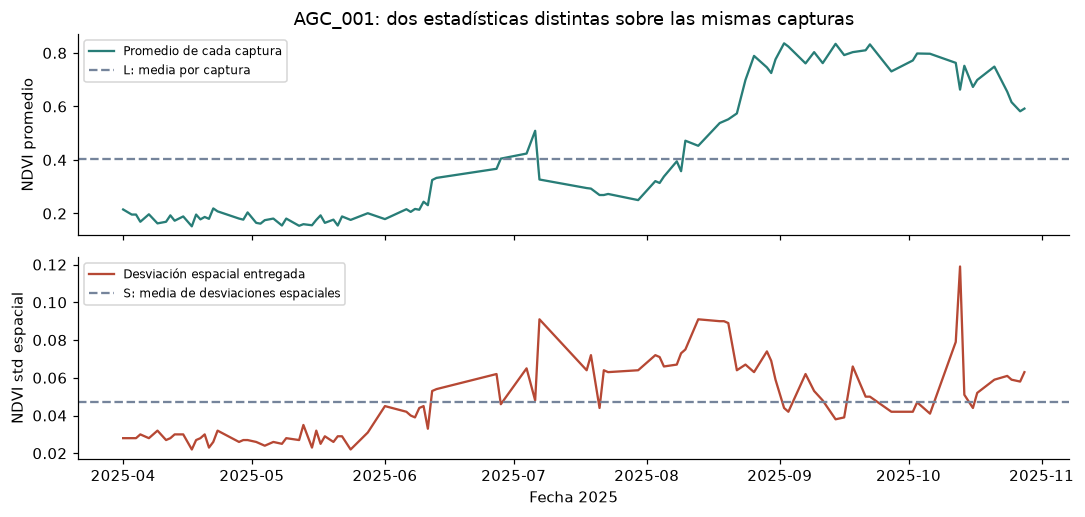

In [6]:
capturas["promedio_finito"] = np.isfinite(capturas.ndvi_promedio)
capturas["std_finita"] = np.isfinite(capturas.ndvi_std)
capturas["pareada"] = capturas.promedio_finito & capturas.std_finita
capturas["mes"] = capturas.fecha.dt.month
par = capturas.loc[capturas.pareada].copy()
ejemplo = par.loc[par.ID_POLIGONO.eq("AGC_001")].sort_values("fecha")
l_uno = float(ejemplo.ndvi_promedio.sum()/len(ejemplo))
s_uno = float(ejemplo.ndvi_std.sum()/len(ejemplo))
display(ejemplo[["fecha","ndvi_promedio","ndvi_std","porcentaje_nubosidad"]].head(8))
display(pd.DataFrame([{"parcela":"AGC_001","capturas_pareadas":len(ejemplo),"L":l_uno,"S":s_uno,
                      "otra_operacion_std_temporal_de_promedios":ejemplo.ndvi_promedio.std(ddof=0)}]))
fig,axes = plt.subplots(2,1,figsize=(10,4.8),sharex=True)
axes[0].plot(ejemplo.fecha,ejemplo.ndvi_promedio,color="#287d77",label="Promedio de cada captura")
axes[0].axhline(l_uno,color="#75849b",ls="--",label="L: media por captura")
axes[1].plot(ejemplo.fecha,ejemplo.ndvi_std,color="#b64834",label="Desviación espacial entregada")
axes[1].axhline(s_uno,color="#75849b",ls="--",label="S: media de desviaciones espaciales")
axes[0].set(ylabel="NDVI promedio",title="AGC_001: dos estadísticas distintas sobre las mismas capturas")
axes[1].set(ylabel="NDVI std espacial",xlabel="Fecha 2025")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 3. La misma regla para las 197 parcelas

Agrupar por ID y promediar dos columnas sobre `par` crea L/S. Los nombres
nuevos preservan las columnas históricas. La extracción anterior omitía NaN
de std por separado; primero comprobamos las máscaras. **Aquí coinciden**:
el pareado no cambia efectivamente la receta; el control posterior lo demuestra.
Construir primero y contrastar después evita usar una salida como entrada.

In [7]:
medias = par.groupby("ID_POLIGONO")[["ndvi_promedio","ndvi_std"]].mean().rename(columns={"ndvi_promedio":L,"ndvi_std":S})
variables = metadata.merge(medias,on="ID_POLIGONO",how="left",validate="one_to_one").sort_values("ID_POLIGONO").reset_index(drop=True)
control = csv_insumo("variables_control").sort_values("ID_POLIGONO").reset_index(drop=True)
pd.testing.assert_frame_equal(variables,control,check_exact=True)
np.testing.assert_allclose(variables.set_index("ID_POLIGONO").loc["AGC_001",[L,S]].to_numpy(float),[l_uno,s_uno],atol=1e-12,rtol=0)
hist = csv_insumo("comparacion_v0_control").set_index("ID_POLIGONO").sort_index()
actual = variables.set_index("ID_POLIGONO").sort_index()
np.testing.assert_allclose(actual[[L,S]],hist[["C_PL_ndvi_media","C_PL_ndvi_std_media"]],atol=1e-12,rtol=0,equal_nan=True)
assert capturas.promedio_finito.eq(capturas.std_finita).all()
assert len(par) == 18248 and len(variables) == 197 and variables[[L,S]].notna().all().all()
assert "RENDIMIENTO_T_HA" not in variables
display(variables.head(8))
print("18,248 capturas pareadas; 197 filas preservadas; igualdad con v0 a 10⁻¹².")

,ID_POLIGONO,Municipio,Estado,AREA_HA,CONJUNTO,H7_PL_ndvi_media_pareada,H7_PL_ndvi_std_media_pareada
0,AGC_001,Calpulalpan,Tlaxcala,7.61,ENTRENAMIENTO,0.402093,0.047278
1,AGC_002,Chignahuapan,Puebla,2.31,ENTRENAMIENTO,0.454918,0.044835
2,AGC_003,Singuilucan,Hidalgo,18.68,PREDICCION,0.463394,0.054070
3,AGC_004,Calpulalpan,Tlaxcala,8.00,ENTRENAMIENTO,0.412143,0.098181
4,AGC_005,Chignahuapan,Puebla,2.27,ENTRENAMIENTO,0.480924,0.054913
5,AGC_006,Chignahuapan,Puebla,3.84,ENTRENAMIENTO,0.408917,0.050417
6,AGC_007,Singuilucan,Hidalgo,2.87,ENTRENAMIENTO,0.448684,0.048241
7,AGC_008,Chignahuapan,Puebla,10.77,ENTRENAMIENTO,0.420021,0.053896


18,248 capturas pareadas; 197 filas preservadas; igualdad con v0 a 10⁻¹².


## 4. Factibilidad sin rendimiento

Hay capturas pareadas en los siete meses para todas las parcelas. No exigimos
el mismo número de escenas ni inventamos valores diarios. Una media por captura
pesa más las fechas observadas con mayor frecuencia; cambiar eso reabriría EXP_02.

En cada uno de los **50 entrenamientos exteriores y 200 interiores** se
comprueba disponibilidad para imputar y variación intramunicipal de S. Solo se
usan sus propias X: mediana → centrado por municipio → escala poblacional.
Estas estadísticas sirven de control de factibilidad, no se reutilizan para
ajustar candidatos. Columnas vacías o S sin variación habrían detenido la ronda.

In [8]:
mensual = pd.MultiIndex.from_product([metadata.ID_POLIGONO,range(4,11)],names=["ID_POLIGONO","mes"]).to_frame(index=False).merge(
    par.groupby(["ID_POLIGONO","mes"]).agg(n_pareadas=("ndvi_std","size"),L_media=("ndvi_promedio","mean"),S_media=("ndvi_std","mean"),nube_media=("porcentaje_nubosidad","mean")).reset_index(),
    how="left",validate="one_to_one")
mensual.n_pareadas = mensual.n_pareadas.fillna(0).astype(int)
mensual_control = csv_insumo("mensual_control")
pd.testing.assert_frame_equal(mensual,mensual_control,check_exact=True)
assert mensual.n_pareadas.gt(0).all() and len(mensual) == 1379
x = variables.set_index("ID_POLIGONO")
var_rows = []
for nivel,roles,keys in [("exterior",externas,["repeticion","pliegue"]),("interior",internas,["repeticion","pliegue","pliegue_interno"])]:
    for clave,g in roles.groupby(keys,sort=True):
        tr = x.loc[g.loc[g.rol.eq("entrenamiento"),"ID_POLIGONO"]]
        for campo in [L,S]:
            v = tr[campo].to_numpy(float); n = int(np.isfinite(v).sum())
            if n == 0: raise ValueError("Columna vacía en entrenamiento: detener")
            mediana = float(np.nanmedian(v)); imp = np.where(np.isnan(v),mediana,v)
            serie = pd.Series(imp,index=tr.index)
            residuo = serie-serie.groupby(tr.Municipio).transform("mean")
            escala = float(np.sqrt(np.mean(residuo.to_numpy()**2)))
            umbral = 1e-12*max(1.,float(np.max(np.abs(imp))))
            var_rows.append({"nivel":nivel,**dict(zip(keys,clave)),"variable":campo,"n_entrenamiento":len(tr),"n_finitos":n,
                             "mediana_diagnostica":mediana,"escala_intramunicipal":escala,"umbral_escala":umbral,"columna_vacia":False,"escala_degenerada":bool(escala<=umbral)})
variacion = pd.DataFrame(var_rows)
var_control = csv_insumo("variacion_control")
pd.testing.assert_frame_equal(variacion,var_control,check_exact=False,atol=1e-12,rtol=0)
assert len(variacion) == 500 and not variacion.loc[variacion.variable.eq(S),"escala_degenerada"].any()
display(mensual.loc[mensual.ID_POLIGONO.eq("AGC_001")])
display(variacion.groupby(["nivel","variable"]).agg(train=("n_entrenamiento","size"),min_finitos=("n_finitos","min"),min_escala=("escala_intramunicipal","min")))

,ID_POLIGONO,mes,n_pareadas,L_media,S_media,nube_media
0,AGC_001,4,20,0.187100,0.027850,0.000000
1,AGC_001,5,17,0.171824,0.027176,7.789000
2,AGC_001,6,11,0.267000,0.045727,1.682000
3,AGC_001,7,9,0.323222,0.063889,0.154222
4,AGC_001,8,16,0.537188,0.073750,8.427937
5,AGC_001,9,11,0.798909,0.048545,8.933455
6,AGC_001,10,13,0.700846,0.059615,7.179692


train  min_finitos  min_escala
nivel    variable                                                    
exterior H7_PL_ndvi_media_pareada         50          110    0.025149
         H7_PL_ndvi_std_media_pareada     50          110    0.012505
interior H7_PL_ndvi_media_pareada        200           82    0.022958
         H7_PL_ndvi_std_media_pareada    200           82    0.011727

**Calidad y alcance:** área, nubosidad y número de capturas pueden acompañar
a la señal. Sus asociaciones con S son diagnósticos entre X, no razones para
seleccionar otra receta según rendimiento. Una correlación baja no elimina
confusión no lineal ni demuestra precisión de la medición.

Las 59 ocultas tienen L/S disponibles. Se muestran rangos frente a sus municipios
etiquetados, sin predecirlas. Nanacamilpa sigue con una etiqueta y no tiene un
caso OOF equivalente a la entrega. Rango univariado no es garantía de soporte.

In [9]:
calidad = csv_insumo("calidad_control")
corrs = csv_insumo("correlaciones_X_control")
assert calidad.ID_POLIGONO.is_unique and len(calidad) == 197
assert calidad.n_pareadas.sum() == len(par) and calidad.meses_con_par.eq(7).all()
assert calidad.n_promedio_sin_std.sum() == calidad.n_std_sin_promedio.sum() == 0
correlacion_recalculada = variables.loc[variables.CONJUNTO.eq("ENTRENAMIENTO"),["Municipio",L,S]].copy()
for c in [L,S]:
    correlacion_recalculada[c] -= correlacion_recalculada.groupby("Municipio")[c].transform("mean")
r_x = correlacion_recalculada[L].corr(correlacion_recalculada[S])
r_control = corrs.loc[corrs.poblacion.eq("ENTRENAMIENTO_X") & corrs.tipo.eq("intramunicipal") & corrs.variable_2.eq(L),"pearson"].iloc[0]
np.testing.assert_allclose(r_x,r_control,atol=1e-12,rtol=0)
soporte = csv_insumo("soporte_control")
assert len(soporte) == 59 and not soporte.L_ausente.any() and not soporte.S_ausente.any()
assert set(soporte.ID_POLIGONO) == set(variables.loc[variables.CONJUNTO.eq("PREDICCION"),"ID_POLIGONO"])
display(corrs.loc[corrs.poblacion.eq("ENTRENAMIENTO_X") & corrs.tipo.eq("intramunicipal"),["variable_2","pearson","n_pares"]])
display(soporte.groupby("Municipio").agg(ocultas=("ID_POLIGONO","size"),etiquetadas=("n_parcelas_etiquetadas_municipio","first"),L_fuera=("L_fuera_rango_municipal","sum"),S_fuera=("S_fuera_rango_municipal","sum")))
display(soporte.loc[soporte.caso_singleton])
print("Factibilidad superada usando X; esto aún no demuestra aporte predictivo de S.")

,variable_2,pearson,n_pares
11,H7_PL_ndvi_media_pareada,-0.128366,138
13,AREA_HA,0.041229,138
15,n_pareadas,-0.142843,138
17,nube_media_pareada,0.100259,138
19,fraccion_nube_parcial_pareada,0.164252,138


,ocultas,etiquetadas,L_fuera,S_fuera
Municipio,,,,
Almoloya,4,10,1,0
Calpulalpan,14,30,1,1
Chignahuapan,29,71,0,0
Cuautepec de Hinojosa,4,5,2,0
Nanacamilpa de Mariano Arista,1,1,1,1
Singuilucan,7,16,1,0


,ID_POLIGONO,Municipio,n_parcelas_etiquetadas_municipio,caso_singleton,L_valor,L_ausente,L_etiquetadas_disponibles,L_fuera_rango_municipal,S_valor,S_ausente,S_etiquetadas_disponibles,S_fuera_rango_municipal
34,AGC_120,Nanacamilpa de Mariano Arista,1,True,0.515566,False,1,True,0.092972,False,1,True


Factibilidad superada usando X; esto aún no demuestra aporte predictivo de S.


## 5. La comparación que responde la hipótesis

| Procedimiento | Variables numéricas | Qué responde |
| --- | --- | --- |
| C0 | L | Control de nivel, con corrección municipal + Ridge |
| C1 | L + S | Añadido de una dimensión espacial, misma arquitectura |
| MUN / MIX | Recetas fijas del recorrido | Competitividad frente a referencias fuertes |

Por entrenamiento: mediana de X → restar medias municipales de X e y →
escalar residuos → Ridge sin intercepto → sumar media municipal al predecir.
Los interceptos municipales no se penalizan. Municipio no visto: media global
sin corrección. Esta arquitectura es la extensión multivariable de las rondas
de lluvia, **no E2**, que penalizaba one-hot municipal.

La imputación es común a C0/C1 y aprendida dentro de cada entrenamiento.
Las columnas de ausencia no entran como predictores. Una escala degenerada
anula solo esa corrección, no las otras; singleton participa con residuo cero.
Una opción `baseline` recupera MUN exactamente. No se corrige MIX con residuos
históricos OOF ni se usan las 59 X para estimar estadísticas de entrenamiento.

In [10]:
PRE = json_insumo("registro_previo")
REG = json_insumo("registro_ejecucion")
assert REG["registro_sha256"] == hashlib.sha256(bytes_insumo("registro_previo",INSUMOS_INCRUSTADOS["registro_previo"]["uso"])).hexdigest()
etiquetas = csv_insumo("etiquetas")
assert len(etiquetas) == 138 and etiquetas.ID_POLIGONO.is_unique
assert set(etiquetas.ID_POLIGONO) == set(metadata.loc[metadata.CONJUNTO.eq("ENTRENAMIENTO"),"ID_POLIGONO"])
assert np.isfinite(etiquetas.RENDIMIENTO_T_HA).all()
assert REG["predicciones_59_generadas"] == 0
print("Solo ahora se cargan etiquetas y resultados de la corrida registrada.")
print("Registro previo UTC:",PRE["registrado_utc"])
print("Corrida UTC:",REG["inicio_utc"],"→",REG["fin_utc"])
print("Entorno de la corrida:",REG["python"],"| presupuesto real:",REG["presupuesto"])
print("Esta ejecución del lector no suma ningún ajuste a ese presupuesto.")

Solo ahora se cargan etiquetas y resultados de la corrida registrada.
Registro previo UTC: 2026-10-08T17:05:38.396066+00:00
Corrida UTC: 2026-10-08T17:05:44.568406+00:00 → 2026-10-08T17:06:05.237649+00:00
Entorno de la corrida: 3.13.13 | presupuesto real: {'evaluaciones_internas': 2400, 'evaluaciones_baseline': 400, 'opciones_ridge_internas': 2000, 'ajustes_ridge_internos': 2000, 'reconstrucciones_exteriores': 100, 'ajustes_ridge_exteriores': 11, 'evaluaciones_referencia': 100}
Esta ejecución del lector no suma ningún ajuste a ese presupuesto.


## 6. Particiones y selector interior, sin nueva búsqueda

Conservamos los mismos CSV: cinco pliegues × diez repeticiones y cuatro
interiores por entrenamiento exterior, siempre por parcela. Medianas, medias
y escala originales se aprendieron otra vez en cada entrenamiento interior.
Selección original sobre FULL interior; SEEN135 solo es población de evaluación
principal. No se busca otra semilla o se cambia selector por el resultado.

In [11]:
ids = set(etiquetas.ID_POLIGONO)
assert len(externas) == 6900 and len(internas) == 22080
assert not externas.duplicated(["repeticion", "pliegue", "ID_POLIGONO"]).any()
assert not internas.duplicated(["repeticion", "pliegue", "pliegue_interno", "ID_POLIGONO"]).any()
assert set(externas.rol) == set(internas.rol) == {"entrenamiento", "validacion"}
assert set(externas.repeticion) == set(range(10)) and set(externas.pliegue) == set(range(5))
assert set(internas.pliegue_interno) == set(range(4))
assert set(internas.groupby(["repeticion", "pliegue"]).groups) == set(externas.groupby(["repeticion", "pliegue"]).groups)
for (r, f), parte in externas.groupby(["repeticion", "pliegue"]):
    train_ids = set(parte.loc[parte.rol.eq("entrenamiento"), "ID_POLIGONO"])
    val_ids = set(parte.loc[parte.rol.eq("validacion"), "ID_POLIGONO"])
    assert train_ids.isdisjoint(val_ids) and train_ids | val_ids == ids
    dentro = internas.loc[internas.repeticion.eq(r) & internas.pliegue.eq(f)]
    assert set(dentro.ID_POLIGONO) == train_ids
    for _, iparte in dentro.groupby("pliegue_interno"):
        assert set(iparte.ID_POLIGONO) == train_ids
    frecuencia = dentro.loc[dentro.rol.eq("validacion")].groupby("ID_POLIGONO").size()
    assert set(frecuencia.index) == train_ids and frecuencia.eq(1).all()
claves = ["repeticion", "pliegue", "ID_POLIGONO"]
validaciones = externas.loc[externas.rol.eq("validacion"), claves].copy()
frecuencia = validaciones.groupby(["repeticion", "ID_POLIGONO"]).size()
assert len(validaciones) == len(frecuencia) == 1380 and frecuencia.eq(1).all()
ejemplo_roles = externas.loc[externas.repeticion.eq(0) & externas.pliegue.eq(0)]
display(ejemplo_roles.groupby("rol").size().rename("parcelas").to_frame())
display(internas.loc[internas.repeticion.eq(0) & internas.pliegue.eq(0)]
        .groupby(["pliegue_interno", "rol"]).size().rename("parcelas").to_frame())

,parcelas
rol,
entrenamiento,110
validacion,28


parcelas
pliegue_interno rol                    
0               entrenamiento        82
                validacion           28
1               entrenamiento        82
                validacion           28
2               entrenamiento        83
                validacion           27
3               entrenamiento        83
                validacion           27

Seis opciones: baseline y alpha 0.01/0.1/1/10/100. RMSE interior agrupado =
raíz de suma SSE de las cuatro validaciones / número total de sus predicciones.
Empate a 10⁻¹²: baseline primero, después alpha mayor. Los archivos conservan
**2,400 SSE interiores**, **600 scores agrupados** y **100 decisiones**; podemos
comprobar esa aritmética sin ejecutar modelos.

Presupuesto de una corrida: 2,400 evaluaciones internas —400 baseline y 2,000
opciones Ridge—, 100 reconstrucciones exteriores y 100 evaluaciones de
referencias. El registro separa llamadas Ridge efectivas de opciones y
reconstrucciones. Una réplica determinista repite coste físico, no añade hipótesis.

In [12]:
scores = csv_insumo("scores")
pliegues = csv_insumo("scores_pliegue")
seleccion = csv_insumo("seleccion")
assert len(scores) == 600 and len(pliegues) == 2400 and len(seleccion) == 100
keys_sel = ["modelo","repeticion","pliegue"]
assert not scores.duplicated(keys_sel+["opcion"]).any()
assert not pliegues.duplicated(keys_sel+["pliegue_interno","opcion"]).any()
assert not seleccion.duplicated(keys_sel).any()
pooled = pliegues.groupby(keys_sel+["opcion"],as_index=False).agg(SSE=("SSE","sum"),n_validacion=("n_validacion","sum"))
pooled["RMSE"] = np.sqrt(pooled.SSE/pooled.n_validacion)
a,b = pooled.set_index(keys_sel+["opcion"]).sort_index(),scores.set_index(keys_sel+["opcion"]).sort_index()
assert a.index.equals(b.index)
np.testing.assert_allclose(a[["SSE","n_validacion","RMSE"]],b[["SSE","n_validacion","RMSE"]],atol=1e-12,rtol=0)
elegidas = []
for key,g in scores.groupby(keys_sel,sort=True):
    vals = g.set_index("opcion").RMSE
    assert set(vals.index) == {"baseline","0.01","0.1","1.0","10.0","100.0"}
    empate = vals[vals <= vals.min()+1e-12].index.tolist()
    opcion = "baseline" if "baseline" in empate else str(max(float(o) for o in empate))
    elegidas.append({**dict(zip(keys_sel,key)),"opcion_elegida":opcion,"RMSE_interior":float(vals[opcion])})
dec = pd.DataFrame(elegidas).set_index(keys_sel).sort_index()
sel = seleccion.set_index(keys_sel).sort_index()
np.testing.assert_array_equal(dec.opcion_elegida,sel.opcion_elegida)
np.testing.assert_allclose(dec.RMSE_interior,sel.RMSE_interior,atol=1e-12,rtol=0)
assert REG["presupuesto"]["evaluaciones_internas"] == 2400
display(seleccion.groupby(["modelo","opcion_elegida"]).size().rename("exteriores").to_frame())
print("600 scores desde 2,400 SSE y 100 elecciones reproducidos; cero nuevas llamadas Ridge.")

exteriores
modelo opcion_elegida            
C0     10.0                     1
       100.0                    3
       baseline                46
C1     100.0                    7
       baseline                43

600 scores desde 2,400 SSE y 100 elecciones reproducidos; cero nuevas llamadas Ridge.


## 7. Abrir una predicción, con parámetros guardados

Para un municipio visto:

`ŷ = media_y_del_municipio + Σ β_j × (X_imputada_j − media_X_municipal_j) / escala_j`.

Se usan mediana, medias, escala y β **guardados de ese entrenamiento**, no
estadísticas calculadas con la parcela validada. Abrimos C1, repetición 0,
pliegue 0 y su primer ID de validación ordenado. No se elige por el error.
Comprobar esta ecuación reproduce la aplicación de parámetros, **no reentrena**
el modelo ni acredita por sí solo toda la selección interior.

In [13]:
parametros = json_insumo("parametros")
oof = csv_insumo("oof")
assert len(parametros) == 100 and len(oof) == 5520
p = next(p for p in parametros if p["modelo"] == "C1" and p["repeticion"] == 0 and p["pliegue"] == 0)
m = p["modelo_ajustado"]
id_uno = sorted(externas.loc[externas.repeticion.eq(0)&externas.pliegue.eq(0)&externas.rol.eq("validacion"),"ID_POLIGONO"])[0]
fila = variables.set_index("ID_POLIGONO").loc[id_uno]
raw = fila[p["columnas"]].to_numpy(float)
imp = np.where(np.isnan(raw),np.asarray(m["medianas"],float),raw)
activa = np.asarray(m["activa"],bool); beta = np.asarray(m["beta"],float)
conocido = fila.Municipio in m["media_y"]
if conocido:
    media_x = np.asarray(m["media_x"][fila.Municipio],float)
    escala = np.asarray(m["escala"],float)
    z = np.zeros(len(raw)); z[activa] = (imp[activa]-media_x[activa])/escala[activa]
    componentes = beta*z
    territorial = m["media_y"][fila.Municipio]
else:
    z = np.zeros(len(raw)); componentes = np.zeros(len(raw)); territorial = m["media_global_y"]
pred_uno = float(territorial+componentes.sum())
guardada = oof.loc[oof.modelo.eq("C1")&oof.repeticion.eq(0)&oof.pliegue.eq(0)&oof.ID_POLIGONO.eq(id_uno),"predicho"].iloc[0]
np.testing.assert_allclose(pred_uno,guardada,atol=1e-12,rtol=0)
display(pd.DataFrame({"columna":p["columnas"],"entrada":raw,"imputada":imp,"z_train":z,"beta_guardada":beta,"correccion":componentes}))
print(id_uno,"· componente municipal",territorial,"+ corrección",float(componentes.sum()),"=",pred_uno,"t/ha")

,columna,entrada,imputada,z_train,beta_guardada,correccion
0,H7_PL_ndvi_media_pareada,0.420021,0.420021,0.384288,0.0,0.0
1,H7_PL_ndvi_std_media_pareada,0.053896,0.053896,-0.107176,0.0,-0.0


AGC_008 · componente municipal 4.531607142857143 + corrección 0.0 = 4.531607142857143 t/ha


## 8. Evaluación OOF sobre las mismas parcelas

Cada procedimiento tiene 1,380 OOF: diez predicciones fuera de muestra de
cada una de 138 parcelas. No son 1,380 muestras independientes. **SEEN135**
puntúa solo municipio presente en su entrenamiento exterior: 1,350 OOF por
procedimiento, sin retirar las tres etiquetas singleton del entrenamiento.
FULL138 sigue como secundario; no se comparan cifras de poblaciones diferentes.

RMSE y MAE se calculan sobre errores concatenados, sin promediar primero por
parcela o pliegue. R² ordena igual que RMSE sobre la misma muestra/pesos; no
queda definido cuando no hay variación efectiva del objetivo. Se conserva la
guarda numérica de la corrida: SST > 10⁻¹⁴ × max(1, suma y²).

,n_parcelas,n_oof,RMSE,MAE,R2
modelo,,,,,
MUN,135,1350,0.493404,0.321274,0.657475
MIX,135,1350,0.487197,0.334215,0.666039
C0,135,1350,0.494064,0.321996,0.656558
C1,135,1350,0.494105,0.321769,0.656501


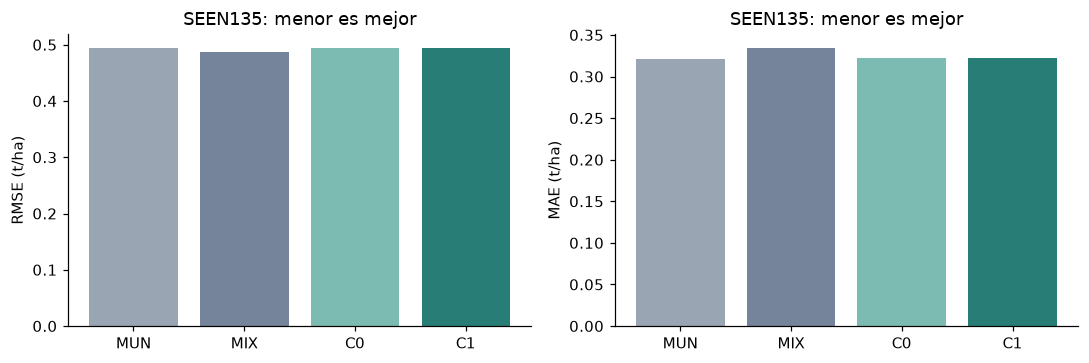

In [14]:
MODELOS = ["MUN","MIX","C0","C1"]
assert set(oof.modelo) == set(MODELOS) and not oof.duplicated(["modelo"]+claves).any()
esperado = set(map(tuple,validaciones[claves].to_numpy()))
y_oficial = etiquetas.set_index("ID_POLIGONO").RENDIMIENTO_T_HA
mascara_rows = []
for (r,f),g in externas.groupby(["repeticion","pliegue"]):
    mun_tr = set(g.loc[g.rol.eq("entrenamiento"),"ID_POLIGONO"].map(x.Municipio))
    va = g.loc[g.rol.eq("validacion"),claves].copy()
    va["municipio_visto"] = va.ID_POLIGONO.map(x.Municipio).isin(mun_tr)
    mascara_rows.append(va)
mascara = pd.concat(mascara_rows,ignore_index=True)
for modelo,g in oof.groupby("modelo"):
    assert len(g) == 1380 and set(map(tuple,g[claves].to_numpy())) == esperado
    np.testing.assert_array_equal(g.observado,g.ID_POLIGONO.map(y_oficial))
    np.testing.assert_array_equal(g.Municipio,g.ID_POLIGONO.map(x.Municipio))
    q = g.merge(mascara,on=claves,validate="one_to_one",suffixes=("_guardada",""))
    np.testing.assert_array_equal(q.municipio_visto_guardada,q.municipio_visto)
    assert int(g.municipio_visto.sum()) == 1350
assert np.isfinite(oof[["observado","predicho"]]).all().all()
seen = oof.loc[oof.municipio_visto].copy()
ESCENARIOS = {"SEEN135":seen,"FULL138":oof}

def metricas(df):
    if df.empty: raise ValueError("No puntuar población vacía")
    y,p = df.observado.to_numpy(float),df.predicho.to_numpy(float)
    if not np.isfinite(y).all() or not np.isfinite(p).all(): raise ValueError("Errores no finitos")
    e = y-p; sse = float(e@e); sst = float((y-y.mean())@(y-y.mean()))
    return {"n_oof":len(df),"n_parcelas":df.ID_POLIGONO.nunique(),"RMSE":float(np.sqrt(sse/len(df))),
            "MAE":float(np.mean(abs(e))),"R2":1-sse/sst if sst>1e-14*max(1,float(y@y)) else np.nan}

def contrastar(tabla,key,keys):
    control = csv_insumo(key)
    a,b = tabla.set_index(keys).sort_index(),control.set_index(keys).sort_index()
    assert a.index.equals(b.index)
    cols = a.select_dtypes(include="number").columns
    np.testing.assert_allclose(a[cols],b[cols],atol=1e-12,rtol=0,equal_nan=True)
    for c in a.columns.difference(cols):
        # CSV representa la lista vacía de IDs como campo vacío/NaN.
        vacio = "" if c == "IDs_excluidos" else "<NA>"
        np.testing.assert_array_equal(a[c].fillna(vacio),b[c].fillna(vacio))

met = pd.DataFrame([{"escenario":s,"modelo":m,**metricas(g)} for s,d in ESCENARIOS.items() for m,g in d.groupby("modelo")])
reps = pd.DataFrame([{"escenario":s,"modelo":m,"repeticion":r,**metricas(g)} for s,d in ESCENARIOS.items() for (m,r),g in d.groupby(["modelo","repeticion"])])
contrastar(met,"metricas_control",["escenario","modelo"])
contrastar(reps,"repeticiones_control",["escenario","modelo","repeticion"])
principal = met.loc[met.escenario.eq("SEEN135")].set_index("modelo").reindex(MODELOS)
display(principal[["n_parcelas","n_oof","RMSE","MAE","R2"]])
fig,axes = plt.subplots(1,2,figsize=(10,3.4))
for ax,c in zip(axes,["RMSE","MAE"]):
    ax.bar(MODELOS,principal[c],color=["#9aa5b3","#75849b","#7cbbb2","#287d77"])
    ax.set(ylabel=c+" (t/ha)",title="SEEN135: menor es mejor")
fig.tight_layout(); plt.show()

## 9. Dos preguntas de decisión, no solo una tabla ganadora

**Aporte H7:** C1 reduce RMSE frente a C0 agrupado y en ≥8/10 repeticiones.
**Competitividad prospectiva:** RMSE<MIX y MAE≤MIX agrupados, ambas condiciones
en ≥8/10 repeticiones. Se conserva también el criterio histórico MAE≤MUN,
sin recalificar cierres anteriores. La política frente a MIX se comunicó y
quedó registrada antes de ajustar esta ronda; no es la fórmula oficial de FIRA.

Un C0 competitivo no confirma H7 si S no aporta. Cumplir una regla de desarrollo
no demuestra significación, robustez causal o extrapolación a otros años.

In [15]:
reglas_rows = []
for escenario,d in ESCENARIOS.items():
    g = pd.DataFrame({m:metricas(q) for m,q in d.groupby("modelo")}).T
    r = reps.loc[reps.escenario.eq(escenario)].pivot(index="repeticion",columns="modelo",values="RMSE")
    a = reps.loc[reps.escenario.eq(escenario)].pivot(index="repeticion",columns="modelo",values="MAE")
    incremental = int((r.C1<r.C0).sum())
    for m in ["C0","C1"]:
        nr,nmix,nmun = int((r[m]<r.MIX).sum()),int((a[m]<=a.MIX).sum()),int((a[m]<=a.MUN).sum())
        rm = g.loc[m,"RMSE"]<g.loc["MIX","RMSE"] and nr>=8
        reglas_rows.append({"escenario":escenario,"modelo":m,"n_RMSE_mejor_MIX":nr,"n_MAE_no_peor_MIX":nmix,"n_MAE_no_peor_MUN":nmun,
                           "competitivo_propuesto":bool(rm and g.loc[m,"MAE"]<=g.loc["MIX","MAE"] and nmix>=8),
                           "cumple_criterio_historico":bool(rm and g.loc[m,"MAE"]<=g.loc["MUN","MAE"] and nmun>=8),
                           "n_RMSE_C1_mejor_C0":incremental,"aporte_H7":bool(m=="C1" and incremental>=8 and g.loc["C1","RMSE"]<g.loc["C0","RMSE"])})
reglas = pd.DataFrame(reglas_rows)
contrastar(reglas,"reglas_control",["escenario","modelo"])
display(reglas.loc[reglas.escenario.eq("SEEN135")])
print("ΔRMSE C1−C0:",float(principal.loc["C1","RMSE"]-principal.loc["C0","RMSE"]),"t/ha")
print("ΔMAE C1−C0:",float(principal.loc["C1","MAE"]-principal.loc["C0","MAE"]),"t/ha")

,escenario,modelo,n_RMSE_mejor_MIX,n_MAE_no_peor_MIX,n_MAE_no_peor_MUN,competitivo_propuesto,cumple_criterio_historico,n_RMSE_C1_mejor_C0,aporte_H7
0,SEEN135,C0,1,10,7,False,False,4,False
1,SEEN135,C1,1,10,5,False,False,4,False


ΔRMSE C1−C0: 4.0847026911594586e-05 t/ha
ΔMAE C1−C0: -0.00022705746249251924 t/ha


## 10. Dónde cambia el error y cuán concentrada está la mejora

Chignahuapan y resto se puntúan aparte, sin confundir un promedio general
favorable con solución del error interno. Ganancia SSE positiva significa menor
error cuadrático del candidato. Sumar los diez errores por parcela conserva la
unidad de análisis. Quitamos las dos/cinco parcelas favorables **solo del
puntaje de sensibilidad**, nunca del entrenamiento ni para elegir otra receta.
Fracción positiva bruta no es fracción de ganancia neta.

In [16]:
zonas = pd.DataFrame([{"escenario":s,"modelo":m,"zona":z,**metricas(q.loc[mask])}
                     for s,d in ESCENARIOS.items() for m,q in d.groupby("modelo")
                     for z,mask in [("Chignahuapan",q.Municipio.eq("Chignahuapan")),("Resto",q.Municipio.ne("Chignahuapan"))]])
municipios = pd.DataFrame([{"escenario":s,"modelo":m,"Municipio":mun,**metricas(q)}
                          for s,d in ESCENARIOS.items() for (m,mun),q in d.groupby(["modelo","Municipio"])])
contrastar(zonas,"zonas_control",["escenario","modelo","zona"])
contrastar(municipios,"municipios_control",["escenario","modelo","Municipio"])
deltas_rows,conc_rows = [],[]
for escenario,d in ESCENARIOS.items():
    for candidato,control in [("C1","C0"),("C1","MIX"),("C0","MIX")]:
        a,b = [d.loc[d.modelo.eq(m)].sort_values(claves).reset_index(drop=True) for m in [candidato,control]]
        assert a[claves].equals(b[claves])
        delta = a[claves+["Municipio"]].copy()
        delta["ganancia_SSE"] = (b.observado-b.predicho)**2-(a.observado-a.predicho)**2
        dg = delta.groupby(["ID_POLIGONO","Municipio"],sort=True).ganancia_SSE.sum().reset_index().sort_values(["ganancia_SSE","ID_POLIGONO"],ascending=[False,True])
        positivo = float(dg.ganancia_SSE.clip(lower=0).sum())
        deltas_rows.extend({"escenario":escenario,"candidato":candidato,"control":control,**row} for row in dg.to_dict("records"))
        for k in [0,2,5]:
            excluidos = dg.loc[dg.ganancia_SSE.gt(0),"ID_POLIGONO"].head(k).tolist()
            mask = ~a.ID_POLIGONO.isin(excluidos)
            share = float(dg.loc[dg.ID_POLIGONO.isin(excluidos),"ganancia_SSE"].sum())/positivo if positivo else np.nan
            conc_rows.append({"escenario":escenario,"candidato":candidato,"control":control,"top_k_solicitado":k,
                              "n_parcelas_excluidas_solo_evaluacion":len(excluidos),"IDs_excluidos":"|".join(excluidos),
                              "ganancia_SSE_neta_total":float(dg.ganancia_SSE.sum()),"fraccion_ganancia_positiva_top_k":share,
                              "n_parcelas_mejoran":int(dg.ganancia_SSE.gt(0).sum()),"n_parcelas_empeoran":int(dg.ganancia_SSE.lt(0).sum()),
                              "RMSE_candidato":metricas(a[mask])["RMSE"],"RMSE_control":metricas(b[mask])["RMSE"],
                              "MAE_candidato":metricas(a[mask])["MAE"],"MAE_control":metricas(b[mask])["MAE"]})
deltas,concentracion = pd.DataFrame(deltas_rows),pd.DataFrame(conc_rows)
contrastar(deltas,"contrastes_control",["escenario","candidato","control","ID_POLIGONO","Municipio"])
contrastar(concentracion,"concentracion_control",["escenario","candidato","control","top_k_solicitado"])
display(zonas.loc[zonas.escenario.eq("SEEN135"),["modelo","zona","n_parcelas","RMSE","MAE"]])
display(concentracion.loc[concentracion.escenario.eq("SEEN135")&concentracion.candidato.eq("C1")&concentracion.control.eq("C0")])
display(met.loc[met.escenario.eq("FULL138"),["modelo","RMSE","MAE","R2"]])

,modelo,zona,n_parcelas,RMSE,MAE
0,C0,Chignahuapan,71,0.590964,0.381904
1,C0,Resto,64,0.357017,0.255536
2,C1,Chignahuapan,71,0.591400,0.382259
3,C1,Resto,64,0.356334,0.254663
4,MIX,Chignahuapan,71,0.573628,0.389104
5,MIX,Resto,64,0.368299,0.273322
6,MUN,Chignahuapan,71,0.590198,0.381019
7,MUN,Resto,64,0.356496,0.254994


,escenario,candidato,control,top_k_solicitado,n_parcelas_excluidas_solo_evaluacion,IDs_excluidos,ganancia_SSE_neta_total,fraccion_ganancia_positiva_top_k,n_parcelas_mejoran,n_parcelas_empeoran,RMSE_candidato,RMSE_control,MAE_candidato,MAE_control
0,SEEN135,C1,C0,0,0,,-0.054491,0.000000,72,50,0.494105,0.494064,0.321769,0.321996
1,SEEN135,C1,C0,2,2,AGC_005|AGC_171,-0.054491,0.262170,72,50,0.449525,0.449141,0.303462,0.303530
2,SEEN135,C1,C0,5,5,AGC_005|AGC_171|AGC_145|AGC_162|AGC_079,-0.054491,0.432237,72,50,0.440679,0.440050,0.296089,0.295951


,modelo,RMSE,MAE,R2
4,C0,0.512380,0.336101,0.634978
5,C1,0.512418,0.335879,0.634923
6,MIX,0.493845,0.341711,0.660908
7,MUN,0.511757,0.335394,0.635865


## 11. Cierre y límites

**Cierre sin adopción:** en SEEN135, RMSE C0 **0.494064** y C1 **0.494105**
t/ha, frente a MIX **0.487197**. C1 mejora C0 en solo **4/10 repeticiones**;
no cumple aporte H7 ni competitividad. MAE baja ligeramente **0.321996 →
0.321769**, todavía por encima de MUN **0.321274**. No llamamos esa pequeña
reducción de MAE una mejora global ni buscamos otra receta para rescatarla.

El resultado de abajo proviene de las comparaciones declaradas, no de una
búsqueda añadida por este lector. Se distingue aporte de S, competitividad
del procedimiento completo y eventual adopción. La adopción final no ocurre
automáticamente: requiere comprobar estabilidad, soporte e inferencia.

- Una sola campaña etiquetada y reutilización adaptativa de las mismas etiquetas.
- La anidación protege la selección interior; no borra la adaptación entre rondas.
- Sin píxeles/máscara ni metadatos de procesamiento no se identifica la causa
  agronómica de S. No se anuncian diagnósticos de enfermedades o manejo.
- Un resultado negativo vale para esta media espacial, ventana y corrección
  lineal, no para toda heterogeneidad o toda familia de modelos.
- El lector verifica hashes, variables, selector, aplicación de parámetros y
  métricas conservadas. La corrida y réplica reales se ejecutan con el script
  registrado; esta lectura no sustituye esos controles de entrenamiento.

**Después:** discutir la decisión y congelar la receta de entrega. No se
ejecuta automáticamente otra ventana, índice, árbol o filtro para rescatar H7.

In [17]:
regla_seen = reglas.loc[reglas.escenario.eq("SEEN135")].set_index("modelo")
aporte = bool(regla_seen.loc["C1","aporte_H7"])
competitivos = regla_seen.index[regla_seen.competitivo_propuesto].tolist()
print("Aporte incremental H7 según regla:",aporte)
print("Procedimientos competitivos según regla prospectiva:",competitivos)
print("Ningún procedimiento se adopta ni se generan las 59 predicciones por ejecutar esta lectura.")
resumen = {"id":"EXP_07","modo":"lector_resultados_experimento_registrado_sin_ajustes","parcelas":197,"etiquetas":138,
           "capturas_incorporadas":26255,"capturas_pareadas":18248,"variables_recalculadas":2,
           "mascaras_pareadas_identicas":True,"factibilidad_apta":True,"entrenamientos_X_verificados":250,
           "procedimientos":4,"candidatos":1,"controles_modelo":1,"oof_total":5520,"oof_por_procedimiento":1380,
           "poblacion":"SEEN135","oof_seen_por_procedimiento":1350,"poblacion_secundaria":"FULL138",
           "decisiones_verificadas":100,"scores_guardados_verificados":600,"sse_interiores_verificadas":2400,
           "ecuaciones_oof_reproducidas":1,"ajustes_actuales":0,"predicciones_finales_generadas":0,
           "oof_regeneradas":False,"errores_interiores_regenerados":False,"scores_desde_sse_recalculados":600,"metricas_recalculadas":True,
           "aporte_H7_regla":aporte,"competitivos_prospectivos":competitivos,"variantes_adoptadas":[],
           "metricas_seen":principal[["RMSE","MAE","R2"]].to_dict(orient="index"),
           "fecha_ejecucion_utc":datetime.now(timezone.utc).isoformat()}
print("RESUMEN_EXP_07_JSON="+json.dumps(resumen,ensure_ascii=False,sort_keys=True,allow_nan=False))

Aporte incremental H7 según regla: False
Procedimientos competitivos según regla prospectiva: []
Ningún procedimiento se adopta ni se generan las 59 predicciones por ejecutar esta lectura.
RESUMEN_EXP_07_JSON={"ajustes_actuales": 0, "aporte_H7_regla": false, "candidatos": 1, "capturas_incorporadas": 26255, "capturas_pareadas": 18248, "competitivos_prospectivos": [], "controles_modelo": 1, "decisiones_verificadas": 100, "ecuaciones_oof_reproducidas": 1, "entrenamientos_X_verificados": 250, "errores_interiores_regenerados": false, "etiquetas": 138, "factibilidad_apta": true, "fecha_ejecucion_utc": "2026-10-08T22:10:08.075273+00:00", "id": "EXP_07", "mascaras_pareadas_identicas": true, "metricas_recalculadas": true, "metricas_seen": {"C0": {"MAE": 0.32199607826167054, "R2": 0.6565578389501486, "RMSE": 0.49406405021226596}, "C1": {"MAE": 0.321769020799178, "R2": 0.6565010480498601, "RMSE": 0.49410489723917755}, "MIX": {"MAE": 0.3342146913294449, "R2": 0.6660392362523003, "RMSE": 0.48719651

## Referencias y glosario para profundizar

Equipo AgroCebada. (2026). *Diccionario de índices satelitales* [Documento
suministrado con el reto]. Define std como variabilidad espacial dentro de
parcela por observación; no especifica máscara, conteo de píxeles o ddof.

Equipo AgroCebada. (2026, 8 de octubre). *EXP_07: heterogeneidad espacial
NDVI Planet* [Protocolo y registro interno]. Receta, código y evidencia están
incorporados al cuaderno; no hace falta consultar archivos de otra máquina.

Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection
and subsequent selection bias in performance evaluation. *Journal of Machine
Learning Research, 11*, 2079–2107. https://jmlr.org/papers/v11/cawley10a.html

scikit-learn developers. (s. f.). *Ridge*.
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

**Glosario:** soporte pareado = las mismas capturas para dos estadísticas;
heterogeneidad espacial = diferencias dentro de una parcela en una observación;
imputación = regla de reemplazo aprendida en entrenamiento; efecto municipal =
nivel territorial no penalizado; OOF = predicción fuera de muestra; SSE = suma
de errores cuadrados; baseline = corrección cero; SEEN135 = municipio presente
en entrenamiento; sensibilidad = cambiar solo la población evaluada, sin reajuste.